# Team Toffoli

Our designs, tests and results for the DQC Toffoli challenge. The rules and background are in `Toffoli_Hardware_Hackathon_Challenge.ipynb` in this folder. Run this notebook with the "Python (toffoli)" kernel. Our final case for the judges goes in Section 10 of the starter notebook, Every hardware number traces back to a lab queue ID. The IDs are printed in this notebook's outputs and listed in `evidence/queue_ids.csv`, and both are committed from the first hardware batch on. The full queue log (`submissions/`) and the lab's raw files (`returned_results/`) stay out of git, as the starter kit's `.gitignore` sets.

## Decisions

We made these choices before any hardware run, so the hardware data cannot steer them. Each one names the evidence behind it.

### Decision 1: what "best" means

The best design is the one with the highest process fidelity, which measures how close the whole gate, phases included, is to a Toffoli. We measure it with the fidelity range of Section 2:

F_LB = F_T + F_B1 + F_B2 − 2 ≤ process fidelity ≤ min(F_T, F_B1, F_B2)

This needs 24 circuits per design, plus a readout check (8 circuits) that shows how much of the loss comes from readout.

Why this measure and not another:

- A truth table cannot see phases. The starter notebook's lookalike passes every truth-table row but has process fidelity 0.5625, and its range [0.250, 0.625] catches it (Section 2).
- A truth table can also rank designs the wrong way. In the starter kit's noise model, S_TT puts D0 ahead of D1c (0.895 against 0.863), but their true process fidelities are 0.929 and 0.933. The range puts them in the right order on average (Section 3.1), although one run at 128 shots cannot yet separate them (Section 3.3).
- Full process tomography needs 64 inputs × 27 measurement settings = 1,728 circuits, about 110,600 shots at 64 each. Our whole budget is 20,000.
- Standard interleaved randomized benchmarking needs the tested gate to be a Clifford gate, and the Toffoli is not one.

We still report S_TT, since the starter kit uses it, but we never rank on it.

### Decision 2: which designs go to hardware

| Design | What changes against D0 | Question it answers |
|---|---|---|
| D0 | nothing, it is the starter kit's baseline | reference |
| D1c | smaller `rxx` angles: 1.75π in total against 2.25π | do smaller angles make fewer errors? |
| D2 | each `rxx` angle corrected by its own measured error | does calibration help? |

D2 against D0 changes only the `rxx` angles. D1c against D0 keeps the gate counts the same (5 `rxx`, 14 `rx` and `ry`) and shrinks the total angle, but it also places its gates on different ion pairs: D0 puts its four π/2 gates on (0, 1) and (0, 2), while D1c puts its two π/2 gates on (1, 2). So if the pairs differ (H3 in Section 4.1), the gap between D0 and D1c mixes angle size with pair quality. D0c and D1 differ from D0 and D1c by one `rx` or `ry` gate. In the starter kit's model that gate has a 0.1% error, which moves the fidelity by about 0.001, far below our error bars of about 0.02. So they stay on the simulator.

### Decision 3: raw and readout-corrected numbers

- We rank designs on raw F_LB. Every design goes through the same preparation and readout, so a raw difference is a gate difference. Raw F_LB also has the smaller error: 0.015 to 0.020 at 128 shots (Section 3.2), against about 0.03 after readout correction (Section 3.4).
- Next to it we report the readout-corrected range as our estimate of the gate alone. The raw range also contains preparation and readout errors: a perfect gate scores [0.756, 0.912] raw (Section 3.1).
- The correction costs 2,048 extra shots (the two readout checks). It can be wrong in three ways. Readout errors may be correlated between qubits: we test this (H5) and switch to the full 8×8 matrix if needed. Readout may drift between rounds (H7). And the readout check prepares 1 with `rx(π)`, so it counts that gate's error as readout error: a bad `rx(π)` would push the corrected numbers slightly too high.

### Decision 4: when two designs differ

Each error bar is 1σ, from √(p(1 − p)/N) per circuit (Section 2) or from the bootstrap for corrected numbers (Section 3.4). Two designs differ only if their gap is larger than 2σ of the difference, √(σ_A² + σ_B²). Otherwise they are tied.

### Hardware shot plan (20,000 in total)

| Step | Shots |
|---|---|
| Readout check, round 1 (8 circuits × 128) | 1,024 |
| Gate probes, round 1 (3 gates × 2 readouts × 256) | 1,536 |
| Round 1: D0, D1c and D2 (3 × 24 circuits × 128) | 9,216 |
| Readout check, round 2 (8 × 128) | 1,024 |
| Gate probes again, round 2 (3 × 2 × 128) | 768 |
| Round 2: D1c again and D3 (2 × 24 × 128); planned as the top two designs, see Changes after round 1 | 6,144 |
| Spare | 288 |

The readout check runs once in each round. Pooled, it gives 256 shots per state, which the corrected error bars need (Section 3.4), and comparing the two halves shows whether the readout drifted. Round 2 was planned to double the shots on the two leading designs; after round 1 it runs D1c again (doubling its shots) next to D3 (Changes after round 1). Designs run close together in time give the fairest comparison, since hardware drifts. The second gate probe shows whether the `rxx` angles drifted between rounds (it can see a change of about 0.04 rad), which tells us whether D2's correction went stale. The spare 288 shots can rerun two test circuits.

### Other choices

| Choice | What we picked | Why |
|---|---|---|
| Where our work lives | this notebook; the final case goes in Section 10 of the starter notebook | the starter notebook stays as the organizers wrote it, and all our evidence sits in one notebook the judges can rerun |
| Testing order | exact simulation, then noise models, then hardware | hardware shots are limited, and the starter notebook asks for a simulator check first |
| Mystery backend | not used | we have no URL or token for it, so Section 3 uses noise models we build ourselves |
| Shots per test circuit | 128 | 3 designs × 24 circuits × 128 fits round 1 and leaves room for round 2; the F_LB error is then 0.015 to 0.020 (Section 3.2) |
| Error of one row | √(p(1 − p)/N), with (passes + 1)/(N + 2) in place of p | a row with no failures would otherwise get an error of 0 |
| How D2 is built | each of D0's three kinds of `rxx` is measured on its own and corrected by its own error | there is no error model to get wrong, and it worked in every model we tried (Section 3.4) |
| Gate probe | 5 repeats, a Z readout and an X-Y readout, 256 shots each in round 1 and 128 in round 2 | 5 repeats make the error 5 times larger and still leave ±0.63 rad per gate before the angle wraps (Section 3.4) |
| Readout correction | linear inversion without clipping, with bootstrap errors that add 0.5 to every outcome | clipping pulled pass rates down, and the plain bootstrap gave error bars that were too small (Section 3.5) |
| Order in round 1 | readout check and probes at 16:00; if they return within 30 minutes, D0, D1c and D2 go in together in rotated order; if not, D0 and D1c go in at once and D2 follows | designs run close in time give the fairest comparison, but a slow lab must not push round 2 past midnight |
| Readout model | per-qubit matrices, unless the readout check fails the independence test (Section 4.6) at p < 0.05, the 2σ level; then the full 8×8 matrix | fixed before any data, so the gate results cannot steer it; per-qubit has 6 numbers to estimate instead of 56 |
| Queue IDs for the judges | `evidence/queue_ids.csv` (committed) and notebook outputs kept from the first hardware batch on | the starter kit's `.gitignore` leaves out `submissions/` and `returned_results/`, and the hand-in needs the queue ID behind every hardware number |
| Who submits | one teammate, from one laptop | the guard against sending a batch twice works within one queue log, so two senders could spend the same shots twice |
| Pair-aware design (D4 in our first plan) | not a separate design | the gate probe already measures and corrects each pair on its own, so D2 covers it |
| Pauli twirling (D3 in our first plan) | not planned | twirling makes each gate's error random, which stops coherent errors from adding up across the five gates. In the disclosed model that lifts D0 from 0.929 to 0.941 (same superoperator method as Section 3), while correcting the angles (D2*) reaches 0.990. It also needs many random versions of each circuit, and each version is its own submission |

### Changes after round 1 (decided at 21:10)

Round 1 showed that the probe-based correction failed: D2 scored 0.661 against D0's 0.727 in raw F_LB, the opposite of the +0.077 we predicted (H8). Fitting D0's and D2's own round 1 circuit results shows the gates turning slightly too far inside the circuits (+0.07, +0.10 and +0.06 rad), while the 16:59 probe, which repeats each gate 5 times in a row, showed them falling short. So round 2 replaces D0's repeat with D3, which is D2 retuned from its own circuit results (5.8): D1c and D3 run side by side, with the readout check and the re-probe, at the same 7,936 shots. This departs from our "top two" rule, written before any data: we chose to test one tuning step on the hardware over a sharper D1c against D0. The cost is that D0 is not repeated, so any gap between D3 and D0 crosses the two rounds.

### The claim rule (decided at 21:50, before any round 2 result)

The design we claim as best is the one with the highest raw F_LB after round 2, pooled where it ran in both rounds. If other designs are tied with it within 2σ (Decision 4), the tied design with the higher raw F_T, the truth-table pass rate, is claimed, and the tie is stated. F_T alone cannot see phase errors (Section 2), but here it only chooses between designs whose fidelity ranges already tie. We wrote this rule after round 1, which had D1c and D0 tied and D1c ahead on F_T (0.938 against 0.920, within 2σ), and D0 did not run on the lab again, so the tie-break between those two was chosen with that result known.

Still open: which design we run on IonQ Forte 1 after midnight. We decide that from the lab results.

What we changed along the way, and why, is in Section 3.5.

### How this notebook follows the starter kit's rules

| Rule, and where the kit states it | How we follow it | Where |
|---|---|---|
| only `rx`, `ry`, `rz`, `rxx`; 3 qubits in one register `q`; no classical bits, measurements, resets or barriers (Section 6) | every circuit passes `validate_submission_circuit` before it is sent | 4.2 `preflight`, `build_d2` |
| wires q[2] = c1, q[1] = c2, q[0] = t, and every bitstring reads c1c2t (Section 6) | `C1, C2, T = 2, 1, 0`; set T matches the kit's truth-table helper | Sections 1 and 2 |
| shots from the menu 64, 128, 256, 512, 1024 (shot-budget box after Section 3) | 128 for tests and readout checks; 256, then 128, for probes | Decisions, 4.2 |
| the lab starts in \|000⟩ and measures Z only, so inputs and bases are built inside the circuit (Section 8) | native preparations and basis changes from the kit's table, each checked with `Statevector` | Section 2 sign check |
| verify on a simulator first and do not debug on hardware (shot-budget box) | ideal checks, five noise models, and a full rehearsal on a stand-in lab | Sections 2, 3 and 4.7 |
| submissions only from 4 PM to midnight, with time for a second attempt (Section 9, "What happens at midnight") | round 2 sent by 23:00; a resend path for lost results | 4.1, 5.7 |
| 20,000 hardware shots in total (shot-budget box) | 19,712 planned and 288 spare; the budget is checked before each batch | Decisions, 4.4 |
| keep the queue IDs behind every claim (README, "what to hand in") | queue log, `evidence/queue_ids.csv`, and outputs kept from the first hardware batch | 4.4 |
| never commit TEAM_ID or TEAM_SECRET (README, Section 9) | the values live only in `.env`, which git ignores; the notebook prints only whether they are set | Section 0 |
| with mitigation, show the raw numbers next to it, its extra shots, and what could make it wrong (Section 7, strategies) | raw and corrected side by side, 2,048 extra shots, three ways it can fail | Decision 3 |
| work through the Section 8 questions before 4 PM | one answer per question | end of Section 2 |
| hand in the OpenQASM of the best circuit (README, "what to hand in") | 5.3 prints D2's OpenQASM; the final one goes in Section 7 | 5.3 |

## 0. Setup

Team values live in `.env` at the repository root, which git ignores. The first cell copies them into the environment and prints only whether each one is set. It runs before the challenge package is imported, because the mystery-backend client reads its URL when it is imported.

Every hardware submission is logged to `submissions/queue_log.json` (also ignored by git), so each number we present traces back to a queue ID. A copy without the circuits goes to `evidence/queue_ids.csv`, which is committed (Section 4.4).

In [54]:
import json
import os
from datetime import datetime
from pathlib import Path

import numpy as np

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())


def load_env(path):
    """Copy KEY=VALUE lines from a .env file into os.environ (values already set win); KEY="value" counts as KEY=value."""
    if not path.exists():
        return
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        key, sep, value = line.partition("=")
        value = value.strip()
        if len(value) >= 2 and value[0] == value[-1] and value[0] in "\"'":
            value = value[1:-1]
        if sep and value:
            os.environ.setdefault(key.strip(), value)


load_env(ROOT / ".env")
for key in ("TEAM_ID", "TEAM_SECRET", "MYSTERY_BACKEND_URL", "MYSTERY_BACKEND_TOKEN"):
    print(f"{key:22s} set: {bool(os.environ.get(key))}")

TEAM_ID                set: True
TEAM_SECRET            set: True
MYSTERY_BACKEND_URL    set: False
MYSTERY_BACKEND_TOKEN  set: False


In [55]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, qasm2
from qiskit.circuit.library import SXGate
from qiskit.quantum_info import Operator, Statevector
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import Optimize1qGatesDecomposition

from toffoli_challenge import (
    TOFFOLI_INPUTS,
    baseline_native_toffoli,
    compare_to_toffoli,
    validate_submission_circuit,
    with_input_preparation,
)

RESULTS_DIR = ROOT / "returned_results"
QUEUE_LOG = ROOT / "submissions" / "queue_log.json"


def log_submission(receipt, log_path=QUEUE_LOG, **details):
    """Append one hardware submission (its queue ID and what it tested) to the local log."""
    log_path.parent.mkdir(parents=True, exist_ok=True)
    log = json.loads(log_path.read_text()) if log_path.exists() else []
    entry = {"queue_id": receipt["submission"]["queue_id"],
             "logged_at": datetime.now().isoformat(timespec="seconds"), **details}
    log.append(entry)
    log_path.write_text(json.dumps(log, indent=2))
    return entry


print("repository root:", ROOT.name)

repository root: DQCIntroChallenge


## 1. Designs

A Toffoli needs at least five two-qubit gates (Yu, Duan and Ying, *Phys. Rev. A* 88, 010304, 2013), so the baseline's five `rxx` gates cannot be cut. Two things can still change: the size of the `rxx` angles, and the number of noisy one-qubit gates around them. `rz` is done in software and is free, so only `rx`, `ry` and `rxx` cost anything.

D0 is the starter kit's baseline. It is Qiskit's compilation, with five `rxx` and a total angle of 2.25π.

D1 uses the construction from Barenco et al., *Phys. Rev. A* 52, 3457 (1995): a controlled-√X from c2 to t, a CNOT from c1 to c2, a controlled-√X† from c2 to t, the same CNOT again, and a controlled-√X from c1 to t. When both controls are 1, the target gets √X twice, which is X. When exactly one control is 1, the target gets one √X and one √X†, which cancel. A controlled-√X needs only `rxx(π/4)`, half the angle of a CNOT's `rxx(π/2)`, so the total angle is 3 × π/4 + 2 × π/2 = 1.75π.

D2 is not a new circuit. It is D0 with each `rxx` angle changed to cancel the error we measure on that same gate at the start of the hardware session (rehearsed in Section 3.4).

### Building each block from one `rxx`

A controlled-√X is exp(iπ/8 (I − Z)⊗(I − X)). When the control is 0 the exponent is 0. When it is 1 the target gets exp(iπ/4 (I − X)), which is √X.

Multiplying out the exponent leaves one two-qubit term, exp(iπ/8 Z⊗X), plus one-qubit rotations: `rz(π/4)` on the control and `rx(π/4)` on the target. An `ry(π/2)` on the control turns its Z into X, so the two-qubit term becomes exp(iπ/8 X⊗X), which is `rxx(-π/4)`.

A CNOT is exp(iπ/4 (I − Z)⊗(I − X)), so the same steps give `rxx(-π/2)`. The next cell checks each block against Qiskit's own gate.

In [56]:
C1, C2, T = 2, 1, 0  # challenge wires: q[2] = c1, q[1] = c2, q[0] = t


def controlled_sqrt_x(qc, control, target, inverse=False):
    """Controlled-sqrt(X), exact up to global phase, built from one rxx(-pi/4)."""
    s = -1 if inverse else 1
    qc.ry(np.pi / 2, control)
    qc.rxx(-s * np.pi / 4, control, target)
    qc.ry(-np.pi / 2, control)
    qc.rz(s * np.pi / 4, control)
    qc.rx(s * np.pi / 4, target)


def cnot_native(qc, control, target):
    """CNOT, exact up to global phase, built from one rxx(-pi/2)."""
    qc.ry(np.pi / 2, control)
    qc.rxx(-np.pi / 2, control, target)
    qc.ry(-np.pi / 2, control)
    qc.rz(np.pi / 2, control)
    qc.rx(np.pi / 2, target)


checks = [
    ("controlled-sqrt(X)", lambda qc: controlled_sqrt_x(qc, 1, 0), lambda qc: qc.append(SXGate().control(1), [1, 0])),
    ("controlled-sqrt(X)^dagger", lambda qc: controlled_sqrt_x(qc, 1, 0, inverse=True),
     lambda qc: qc.append(SXGate().inverse().control(1), [1, 0])),
    ("CNOT", lambda qc: cnot_native(qc, 1, 0), lambda qc: qc.cx(1, 0)),
]
for name, build, build_reference in checks:
    block, reference = QuantumCircuit(2), QuantumCircuit(2)
    build(block)
    build_reference(reference)
    print(f"{name:26s} matches Qiskit's gate: {Operator(block).equiv(Operator(reference))}")

controlled-sqrt(X)         matches Qiskit's gate: True
controlled-sqrt(X)^dagger  matches Qiskit's gate: True
CNOT                       matches Qiskit's gate: True


### The designs and their costs

Between `rxx` gates, the one-qubit gates on each wire can be merged into one rotation, written rz · ry · rz. Since `rz` is free, such a run needs at most one `ry`. `compress_1q` merges the runs with Qiskit's `Optimize1qGatesDecomposition` pass, using only `rz` and `ry`, and leaves every `rxx` as it is. The pass does not know `rz` is free: it counts every gate the same and only replaces a run when the new one has fewer gates or the old one uses `rx`. So two runs on q[2] in D1c stay ry · rz · ry, with two `ry` each. With one `ry` each, D1c would have 12 `ry` instead of 14, which in the starter kit's noise model raises its process fidelity by only about 0.0014. We found this after D1c had run on hardware, so we kept it as it was.

In [57]:
def small_angle_toffoli():
    """D1: the Barenco et al. construction with controls c1 = q[2], c2 = q[1] and target t = q[0]."""
    qc = QuantumCircuit(3)
    controlled_sqrt_x(qc, C2, T)
    cnot_native(qc, C1, C2)
    controlled_sqrt_x(qc, C2, T, inverse=True)
    cnot_native(qc, C1, C2)
    controlled_sqrt_x(qc, C1, T)
    return qc


def compress_1q(circuit):
    """Rewrite each run of one-qubit gates with rz and ry only; the pass counts all gates the same, so a run can keep two ry."""
    return PassManager([Optimize1qGatesDecomposition(basis=["rz", "ry"])]).run(circuit)


def costs(circuit):
    """Return (number of rxx, total |rxx angle| / pi, number of rx and ry)."""
    angles = [float(i.operation.params[0]) for i in circuit.data if i.operation.name == "rxx"]
    costly_1q = sum(1 for i in circuit.data if i.operation.name in ("rx", "ry"))
    return len(angles), sum(map(abs, angles)) / np.pi, costly_1q


designs = {
    "D0": baseline_native_toffoli(),
    "D0c": compress_1q(baseline_native_toffoli()),
    "D1": small_angle_toffoli(),
    "D1c": compress_1q(small_angle_toffoli()),
}

print(f"{'design':7s} {'rxx':>4s} {'total angle':>12s} {'rx + ry':>8s} {'ideal process fidelity':>23s}")
for name, circuit in designs.items():
    validate_submission_circuit(circuit)
    n_rxx, total_angle, costly_1q = costs(circuit)
    _, process_fidelity, _ = compare_to_toffoli(circuit)
    print(f"{name:7s} {n_rxx:4d} {total_angle:10.3f}pi {costly_1q:8d} {process_fidelity:23.6f}")

design   rxx  total angle  rx + ry  ideal process fidelity
D0         5      2.250pi       14                1.000000
D0c        5      2.250pi       13                1.000000
D1         5      1.750pi       15                1.000000
D1c        5      1.750pi       14                1.000000


rxx gates in D0, as (pair, angle / pi): [((0, 1), 0.5), ((0, 2), 0.5), ((1, 2), -0.25)]


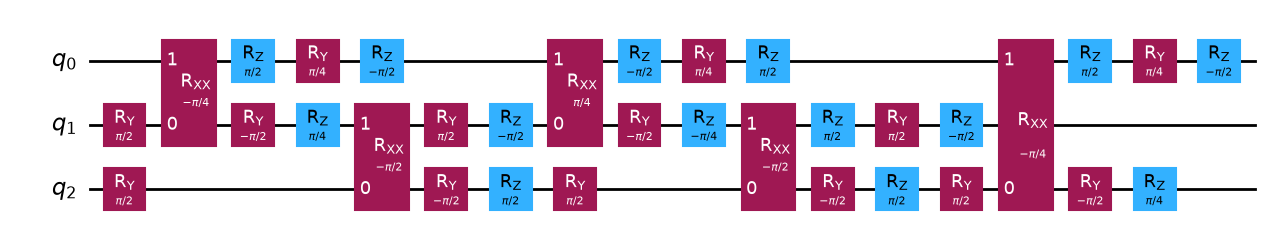

In [58]:
def rxx_gates(circuit):
    """The distinct rxx gates in a circuit, as (sorted qubit pair, angle)."""
    gates = []
    for instruction in circuit.data:
        if instruction.operation.name == "rxx":
            pair = tuple(sorted(circuit.find_bit(q).index for q in instruction.qubits))
            gate = (pair, round(float(instruction.operation.params[0]), 10))
            if gate not in gates:
                gates.append(gate)
    return gates


def correct_each(circuit, errors):
    """Copy a circuit with each rxx(theta) replaced by rxx(theta - error), using that gate's own error.

    errors maps each (sorted qubit pair, angle) from rxx_gates to how far that gate turns past its angle, in radians.
    """
    out = circuit.copy_empty_like()
    for instruction in circuit.data:
        if instruction.operation.name == "rxx":
            theta = float(instruction.operation.params[0])
            pair = tuple(sorted(circuit.find_bit(q).index for q in instruction.qubits))
            out.rxx(theta - errors[(pair, round(theta, 10))], *instruction.qubits)
        else:
            out.append(instruction)
    return out


print("rxx gates in D0, as (pair, angle / pi):", [(pair, round(theta / np.pi, 3)) for pair, theta in rxx_gates(designs["D0"])])
display(designs["D1c"].draw("mpl", fold=-1))

## 2. Proof method: the fidelity range

A truth table checks only probabilities, so it cannot see the relative phases that a Toffoli must get right (Section 8 of the starter notebook). We use three test sets that together bound the process fidelity from both sides. The method is from Mičuda et al., arXiv:1306.1141, and builds on Hofmann, *Phys. Rev. Lett.* 94, 160504 (2005), arXiv:quant-ph/0411011.

| Set | c1 | c2 | t | What an ideal Toffoli does |
|---|---|---|---|---|
| T | Z | Z | Z | flips t when c1 = c2 = 1 (the truth table) |
| B1 | X | Z | X | flips c1 between + and − when c2 = 1 and t = − |
| B2 | Z | X | X | flips c2 between + and − when c1 = 1 and t = − |

Each set has 8 inputs, and each ideal output is one bitstring, so every shot is a pass or a fail. F_T, F_B1 and F_B2 are the average pass rates, and

F_LB = F_T + F_B1 + F_B2 − 2 ≤ process fidelity ≤ min(F_T, F_B1, F_B2).

Why B1 and B2 see phases: a Toffoli with the target in |−⟩ multiplies the state by −1 when both controls are 1 (phase kickback). On the controls this acts as a CZ. With c2 = 1 that CZ is a Z on c1, which swaps |+⟩ and |−⟩. A circuit with the wrong relative phases gets this swap wrong, even when its truth table is perfect.

The cost is 24 circuits per design: 3,072 shots at 128 shots each.

On hardware, every test circuit also has state preparation and readout, so the range bounds the fidelity of the whole run, not of the gate alone. Readout error by itself takes a perfect gate's range down to [0.756, 0.912] (Section 3.1). So we report the raw range, which needs no correction, and next to it a readout-corrected range as our estimate of the gate alone (Section 3.4).

### Where this method comes from, and what we added

The idea of testing a gate in complementary bases is from Hofmann (2005). For two bases he showed F₁ + F₂ − 1 ≤ process fidelity ≤ min(F₁, F₂): a truth table alone cannot see phase errors, but in a second basis a phase error turns into a wrong output. Mičuda et al. (arXiv:1306.1141) extended this to the Toffoli and used it on a linear-optics Toffoli gate. Putting every qubit in X does not work for a Toffoli, because those inputs do not come out as single bitstrings (with the target in |−⟩ the controls come out entangled). So they used the truth table plus two mixed bases, which gives the three-set bound above.

| Part of our method | Source |
|---|---|
| testing in complementary bases so that phase errors cannot hide | Hofmann, *Phys. Rev. Lett.* 94, 160504 (2005), arXiv:quant-ph/0411011 |
| three test sets for a Toffoli, and F_T + F_B1 + F_B2 − 2 ≤ F ≤ min(F_T, F_B1, F_B2) | Mičuda et al., arXiv:1306.1141 |
| our sets B1 and B2, chosen so that each input of an ideal Toffoli gives one bitstring, and an exact check that the bound holds for them (below) | us |
| native preparations and readout (`rx(π)`, `ry(±π/2)`, and `ry(−π/2)` before readout), with the sign checks | us |
| error bars: √(p(1 − p)/N) with (passes + 1)/(N + 2) in place of p, combined in quadrature, checked over 200 runs (3.2) | us |
| the 2σ rule for calling two designs different | us (Decision 4) |
| 128 shots per circuit, two rounds, pooled | us (shot plan) |
| the raw range next to a readout-corrected range (linear inversion, smoothed bootstrap errors) | us (Decision 3, Sections 3.4 and 3.5) |
| ranking designs on raw F_LB | us (Decision 3) |
| using the bound to compare designs (D0, D1c, D2) rather than to describe one gate | us |

How tight the range is: in our practice runs (3.4) the readout-corrected lower end sat 0.02 to 0.15 below the true process fidelity, and the upper end within 0.011 of it. The lower end is the side that is guaranteed, so we rank on it and report the upper end next to it.

In [59]:
TEST_SETS = {"T": ("Z", "Z", "Z"), "B1": ("X", "Z", "X"), "B2": ("Z", "X", "X")}  # bases of (c1, c2, t)
LABELS = {"Z": ("0", "1"), "X": ("+", "-")}
FLIP = {"+": "-", "-": "+"}


def prepare(qc, qubit, label):
    """Prepare |label> from |0> with native gates (table in Section 8 of the starter notebook)."""
    if label == "1":
        qc.rx(np.pi, qubit)
    elif label == "+":
        qc.ry(np.pi / 2, qubit)
    elif label == "-":
        qc.ry(-np.pi / 2, qubit)


def to_z_basis(qc, qubit, basis):
    """Rotate so the lab's Z measurement reads the X basis: |+> gives 0 and |-> gives 1."""
    if basis == "X":
        qc.ry(-np.pi / 2, qubit)


def ideal_output(test_set, c1, c2, t):
    """Output labels of an ideal Toffoli for input labels (c1, c2, t) in one test set."""
    if test_set == "T":
        return c1, c2, str(int(t) ^ (int(c1) & int(c2)))
    if test_set == "B1":
        return (FLIP[c1] if c2 == "1" and t == "-" else c1), c2, t
    return c1, (FLIP[c2] if c1 == "1" and t == "-" else c2), t


def as_bits(labels):
    """The lab's readout string for output labels, in c1 c2 t order."""
    return "".join({"0": "0", "1": "1", "+": "0", "-": "1"}[label] for label in labels)


def test_circuits(candidate):
    """Return {(test set, input labels): (circuit, expected readout)} for all 24 tests."""
    tests = {}
    for name, (b1, b2, bt) in TEST_SETS.items():
        for c1 in LABELS[b1]:
            for c2 in LABELS[b2]:
                for t in LABELS[bt]:
                    qc = QuantumCircuit(3)
                    prepare(qc, C1, c1)
                    prepare(qc, C2, c2)
                    prepare(qc, T, t)
                    qc.compose(candidate, inplace=True)
                    for qubit, basis in ((C1, b1), (C2, b2), (T, bt)):
                        to_z_basis(qc, qubit, basis)
                    validate_submission_circuit(qc)
                    tests[(name, c1 + c2 + t)] = (qc, as_bits(ideal_output(name, c1, c2, t)))
    return tests


print("test circuits per design:", len(test_circuits(designs["D0"])))

test circuits per design: 24


### Sign check

The starter notebook warns that signs are easy to get wrong. The next cell checks, with exact simulation, that each preparation gives the right state, and that the X-basis readout sends |+⟩ to 0 and |−⟩ to 1. It also checks that set T expects the same outputs as the starter kit's truth-table helper.

In [60]:
from toffoli_challenge import expected_output_bitstring

for basis, labels in LABELS.items():
    for label in labels:
        prep = QuantumCircuit(1)
        prepare(prep, 0, label)
        right_state = Statevector(prep).equiv(Statevector.from_label(label))
        to_z_basis(prep, 0, basis)
        p_expected = Statevector(prep).probabilities_dict().get(as_bits(label), 0.0)
        print(f"|{label}>: right state {right_state}, read in {basis} basis as {as_bits(label)} with probability {p_expected:.3f}")

same = all(expected == expected_output_bitstring(key[1])
           for key, (_, expected) in test_circuits(designs["D0"]).items() if key[0] == "T")
print("set T matches the starter kit's truth table:", same)

|0>: right state True, read in Z basis as 0 with probability 1.000
|1>: right state True, read in Z basis as 1 with probability 1.000
|+>: right state True, read in X basis as 0 with probability 1.000
|->: right state True, read in X basis as 1 with probability 1.000
set T matches the starter kit's truth table: True


### Exact check that the bound holds for our test sets

Picture sending one half of a maximally entangled pair of 3-qubit registers through the gate, and call the result ρ. The process fidelity is F = ⟨Φ_U|ρ|Φ_U⟩, where Φ_U is what an ideal Toffoli would give. Test set k passes with probability F_k = Tr(Π_k ρ), where Π_k adds up |input*⟩⟨input*| ⊗ |ideal output⟩⟨ideal output| over the set's 8 inputs.

- Φ_U lies inside every Π_k, so F ≤ F_k. That is the upper end.
- If the three Π_k commute and Φ_U is the only state inside all three, then anything that is not Φ_U fails at least one set: 1 − |Φ_U⟩⟨Φ_U| ≤ (1 − Π_T) + (1 − Π_B1) + (1 − Π_B2). Taking the average in ρ gives 1 − F ≤ (1 − F_T) + (1 − F_B1) + (1 − F_B2), which is F ≥ F_T + F_B1 + F_B2 − 2. That is the lower end.

The next cell checks both conditions exactly for our sets. Because it is a statement about operators, the bound then holds for any noise, on any machine. On hardware it bounds the whole run, with preparation and readout included (Section 2 above).

In [61]:
from toffoli_challenge import ideal_toffoli_in_submission_order

U = Operator(ideal_toffoli_in_submission_order()).data
d = 8
ideal_state = sum(np.kron(np.eye(d)[j], U[:, j]) for j in range(d)) / np.sqrt(d)  # Phi_U
pass_projector = {}
for name, (b1, b2, bt) in TEST_SETS.items():
    p = np.zeros((d * d, d * d), dtype=complex)
    for c1 in LABELS[b1]:
        for c2 in LABELS[b2]:
            for t in LABELS[bt]:
                state_in = Statevector.from_label(c1 + c2 + t).data
                state_out = Statevector.from_label("".join(ideal_output(name, c1, c2, t))).data
                assert np.isclose(abs(np.vdot(state_out, U @ state_in)), 1)  # an ideal Toffoli gives exactly this output
                v = np.kron(state_in.conj(), state_out)
                p += np.outer(v, v.conj())
    pass_projector[name] = p
    print(f"{name}: projector of rank {np.trace(p).real:.0f}, contains the ideal Toffoli state: {np.allclose(p @ ideal_state, ideal_state)}")
for a, b in (("T", "B1"), ("T", "B2"), ("B1", "B2")):
    commutator = pass_projector[a] @ pass_projector[b] - pass_projector[b] @ pass_projector[a]
    print(f"{a} and {b} commute: {np.allclose(commutator, 0)}")
common = pass_projector["T"] @ pass_projector["B1"] @ pass_projector["B2"]
print("only the ideal Toffoli state passes all three sets:", np.allclose(common, np.outer(ideal_state, ideal_state.conj())))

T: projector of rank 8, contains the ideal Toffoli state: True
B1: projector of rank 8, contains the ideal Toffoli state: True
B2: projector of rank 8, contains the ideal Toffoli state: True
T and B1 commute: True
T and B2 commute: True
B1 and B2 commute: True
only the ideal Toffoli state passes all three sets: True


### From counts to the fidelity range

Each test gives a pass rate p = (shots with the expected readout) / N. Its 1σ error is √(p(1 − p)/N). A row with no failures would get an error of zero, which is too optimistic, so the error uses (passes + 1)/(N + 2) in place of p. The error of an average over 8 rows is √(sum of the row variances) / 8, and the error of F_LB adds the three set errors in quadrature. Readout-corrected numbers get their errors by resampling instead (Section 3.4).

In [62]:
def fidelity_range(counts_by_test, tests):
    """Pass rates per test set, the fidelity range and S_TT, each with a 1 sigma error.

    counts_by_test maps (test set, input labels) to the counts dict of that circuit.
    """
    rates, errors = {}, {}
    for name in TEST_SETS:
        rows, variances = [], []
        for key, (_, expected) in tests.items():
            if key[0] != name:
                continue
            counts = counts_by_test[key]
            shots = sum(counts.values())
            passes = counts.get(expected, 0)
            rows.append(passes / shots)
            p_err = (passes + 1) / (shots + 2)
            variances.append(p_err * (1 - p_err) / shots)
        rates[name] = float(np.mean(rows))
        errors[name] = float(np.sqrt(np.sum(variances)) / len(rows))
    weakest = min(rates, key=rates.get)
    return {
        "F": rates,
        "F_err": errors,
        "S_TT": rates["T"],
        "S_TT_err": errors["T"],
        "F_LB": rates["T"] + rates["B1"] + rates["B2"] - 2,
        "F_LB_err": float(np.sqrt(sum(e ** 2 for e in errors.values()))),
        "upper": rates[weakest],
        "upper_err": errors[weakest],
    }


def report(name, result):
    f, e = result["F"], result["F_err"]
    print(f"{name:10s} S_TT {f['T']:.3f}±{e['T']:.3f}   F_B1 {f['B1']:.3f}±{e['B1']:.3f}   F_B2 {f['B2']:.3f}±{e['B2']:.3f}   "
          f"range [{result['F_LB']:.3f}±{result['F_LB_err']:.3f}, {result['upper']:.3f}±{result['upper_err']:.3f}]")

### Check on the ideal simulator

D0 and D1c should give 1 for every set. The starter notebook's lookalike (Section 8) has a perfect truth table but the wrong phases, so B1 and B2 should catch it, and its true process fidelity should land inside its range.

In [63]:
from qiskit import transpile


def lookalike_toffoli():
    """The starter notebook's relative-phase lookalike: perfect truth table, wrong gate."""
    qc = QuantumCircuit(3)
    qc.ry(np.pi / 4, 0)
    qc.cx(1, 0)
    qc.ry(np.pi / 4, 0)
    qc.cx(2, 0)
    qc.ry(-np.pi / 4, 0)
    qc.cx(1, 0)
    qc.ry(-np.pi / 4, 0)
    return transpile(qc, basis_gates=["rx", "ry", "rz", "rxx"], optimization_level=3, seed_transpiler=1)


def exact_counts(circuit, scale=10**6):
    """Noise-free outcome weights, used in place of counts for ideal checks."""
    return {k: v * scale for k, v in Statevector(circuit).probabilities_dict().items() if v > 1e-12}


for name, candidate in {"D0": designs["D0"], "D1c": designs["D1c"], "lookalike": lookalike_toffoli()}.items():
    tests = test_circuits(candidate)
    result = fidelity_range({key: exact_counts(qc) for key, (qc, _) in tests.items()}, tests)
    _, true_fidelity, _ = compare_to_toffoli(candidate)
    report(name, result)
    print(f"{'':10s} true process fidelity {true_fidelity:.4f}")

D0         S_TT 1.000±0.000   F_B1 1.000±0.000   F_B2 1.000±0.000   range [1.000±0.000, 1.000±0.000]
           true process fidelity 1.0000
D1c        S_TT 1.000±0.000   F_B1 1.000±0.000   F_B2 1.000±0.000   range [1.000±0.000, 1.000±0.000]
           true process fidelity 1.0000
lookalike  S_TT 1.000±0.000   F_B1 0.625±0.000   F_B2 0.625±0.000   range [0.250±0.000, 0.625±0.000]
           true process fidelity 0.5625


expected readout c1 c2 t: 111


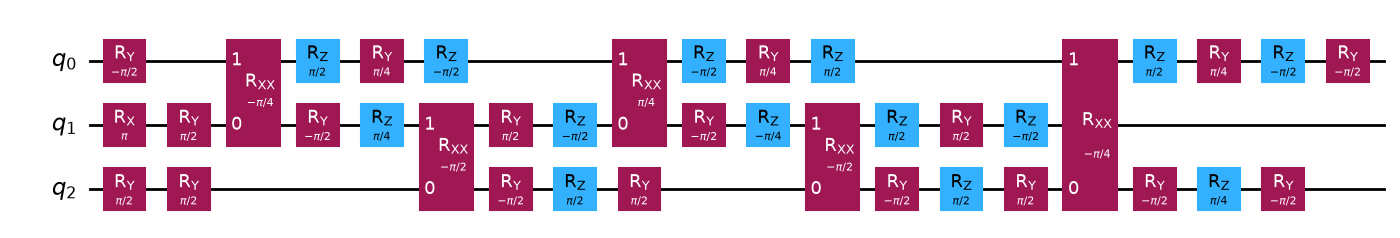

In [64]:
# One B1 test for D1c: c1 in |+>, c2 = 1, t in |->, so an ideal Toffoli turns c1 into |->.
example, expected = test_circuits(designs["D1c"])[("B1", "+1-")]
print("expected readout c1 c2 t:", expected)
display(example.draw("mpl", fold=-1))

### Answers to the starter notebook's Section 8 questions

The starter notebook asks six questions to work through before 4:00 PM.

1. Which circuits pass the truth table perfectly, and what else is needed? Exactly the circuits U = Toffoli · D, where D gives each of the 8 inputs its own phase. A global phase has no effect, so 7 relative phases are left to pin down.
2. What would full process tomography cost? 4³ inputs × 3³ measurement bases = 1,728 circuits, or 110,592 shots at 64 each. That is 5.5 times our 20,000 shots, and one submission every 17 seconds for the whole 8-hour window.
3. Which inputs keep a clear pass or fail per shot, and which phases do they test? Our sets B1 and B2: every input of an ideal Toffoli comes out as one bitstring. A circuit U = Toffoli · D passes B1 perfectly only if the 4 phases with the same c2 are equal, and passes B2 perfectly only if the 4 phases with the same c1 are equal. Together they force all 8 phases to be equal, which the exact check above confirms. Both catch the lookalike: F_B1 = F_B2 = 0.625 while its truth table is perfect.
4. Is there a cheap pair of classical fidelities that bounds the process fidelity? Yes, Hofmann's pair. A Toffoli needs three sets (T, B1, B2), which gives our fidelity range.
5. How do we tell a bad Toffoli apart from bad preparation and readout (SPAM)? Every design runs through the same preparation and readout, so the differences between designs are gate differences, and we rank on those (Decision 3). The readout check measures the readout error, and we report a readout-corrected range next to the raw one. The gate probe measures each `rxx` on its own. What stays mixed in are the errors of the `rx` and `ry` gates that prepare and rotate the test states; separating those would take randomized benchmarking or gate set tomography, which cost more shots than we have.
6. Did we rehearse on the simulators, does the method reject the lookalike, and is the baseline believable? On the ideal simulator the lookalike's range is [0.250, 0.625], which rules out a true Toffoli and contains its true fidelity 0.5625. On the disclosed model the baseline's corrected range averages [0.832, 0.922] against a true 0.929, and holds the truth within 2σ in 93% of runs (3.4). We could not rehearse on the mystery backend, because we did not have its URL and token.

## 3. Practice runs on simulators

Before spending hardware shots, we run the whole method on noise models and ask four questions. Does each design score as theory predicts? Are the error bars right? Can 128 shots per circuit tell the designs apart? Can the 4 PM calibration steps recover a known error?

| Model | Gate error | Readout error | Why we use it |
|---|---|---|---|
| disclosed | every `rxx` turns 0.2 rad too far, and `rx`/`ry` are 0.1% depolarizing | yes | the starter kit's model (`toffoli_challenge/known_noise.py`) |
| angle | every `rxx` turns 5% too far, plus depolarizing that grows with the angle (2% for a π/2 gate) | yes | a machine where smaller angles really make fewer errors, the case where D1c should win |
| readout only | none | yes | shows how much readout alone costs |
| large offset | every `rxx` turns 0.35 rad too far | yes | tests the gate probe (3.4) past the point where our first probe failed |
| same direction | every `rxx` turns 0.15 rad too far in its own direction, so the error has the sign of the angle | yes | an error that one offset plus one scale factor cannot describe; tests the gate probe (3.4) |

The first three models test the whole method. The last two test only the gate probe.

The readout error is the starter kit's: P(read 1 given 0) = 0.015 and P(read 0 given 1) = 0.040. The "true fidelity" of a design is the exact process fidelity of its noisy gate alone, computed from Aer's superoperator simulation. Real hardware never gives us this number, but the simulator does, so we can check whether our measured range tells the truth.

In [65]:
from qiskit.quantum_info import SuperOp, process_fidelity
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError, coherent_unitary_error, depolarizing_error

from toffoli_challenge import ideal_toffoli_in_submission_order

TARGET = Operator(ideal_toffoli_in_submission_order())
NATIVE = ["rx", "ry", "rz", "rxx"]
READOUT = [[0.985, 0.015], [0.040, 0.960]]  # rows: prepared 0, 1; columns: read 0, 1


def gate_noise(offset=0.0, depolarizing_1q=0.001):
    """Gate errors only: an optional fixed rxx over-rotation and depolarizing on rx and ry."""
    model = NoiseModel(basis_gates=NATIVE)
    model.add_all_qubit_quantum_error(depolarizing_error(depolarizing_1q, 1), ["rx", "ry"])
    if offset:
        extra = QuantumCircuit(2)
        extra.rxx(offset, 0, 1)
        model.add_all_qubit_quantum_error(coherent_unitary_error(Operator(extra).data), "rxx")
    return model


def with_readout(model):
    model.add_all_qubit_readout_error(ReadoutError(READOUT))
    return model


def angle_noise(circuit, relative=0.05, depolarizing_per_half_pi=0.02):
    """rxx(theta) becomes rxx(theta * (1 + relative)) followed by depolarizing that grows with |theta|."""
    out = circuit.copy_empty_like()
    for instruction in circuit.data:
        if instruction.operation.name == "rxx":
            theta = float(instruction.operation.params[0])
            out.rxx(theta * (1 + relative), *instruction.qubits)
            p = depolarizing_per_half_pi * abs(theta) / (np.pi / 2)
            out.append(depolarizing_error(p, 2).to_instruction(), instruction.qubits)
        else:
            out.append(instruction)
    return out


def same_direction_noise(circuit, size=0.15):
    """rxx(theta) becomes rxx(theta + size * sign(theta)): every rxx turns too far in its own direction."""
    out = circuit.copy_empty_like()
    for instruction in circuit.data:
        if instruction.operation.name == "rxx":
            theta = float(instruction.operation.params[0])
            out.rxx(theta + size * np.sign(theta), *instruction.qubits)
        else:
            out.append(instruction)
    return out


# name: (circuit change, noise model for sampling counts, noise model for the true-fidelity channel)
MODELS = {
    "disclosed": (lambda c: c.copy(), with_readout(gate_noise(offset=0.2)), gate_noise(offset=0.2)),
    "angle": (angle_noise, with_readout(gate_noise()), gate_noise()),
    "readout only": (lambda c: c.copy(), with_readout(NoiseModel(basis_gates=NATIVE)), None),
    "large offset": (lambda c: c.copy(), with_readout(gate_noise(offset=0.35)), gate_noise(offset=0.35)),
    "same direction": (same_direction_noise, with_readout(gate_noise()), gate_noise()),
}
MAIN_MODELS = ["disclosed", "angle", "readout only"]
# how far rxx(theta) turns past theta in each model
TRUE_ERROR = {
    "disclosed": lambda theta: 0.2,
    "angle": lambda theta: 0.05 * theta,
    "readout only": lambda theta: 0.0,
    "large offset": lambda theta: 0.35,
    "same direction": lambda theta: 0.15 * np.sign(theta),
}


def true_fidelity(candidate, model):
    """Exact process fidelity of the noisy gate alone (no preparation or readout error)."""
    change, _, channel_noise = MODELS[model]
    qc = change(candidate.copy())
    qc.save_superop()
    sim = AerSimulator(method="superop", noise_model=channel_noise) if channel_noise else AerSimulator(method="superop")
    return process_fidelity(SuperOp(sim.run(qc).result().data()["superop"]), TARGET)


def simulate(candidate, model, shots=128, seed=1):
    """Run all 24 test circuits on a noise model; return (fidelity_range result, counts, tests)."""
    change, noise, _ = MODELS[model]
    tests = test_circuits(candidate)
    keys = list(tests)
    batch = []
    for key in keys:
        qc = change(tests[key][0])
        qc.measure_all()
        batch.append(qc)
    result = AerSimulator(noise_model=noise, seed_simulator=seed).run(batch, shots=shots).result()
    counts = {key: result.get_counts(i) for i, key in enumerate(keys)}
    return fidelity_range(counts, tests), counts, tests

### 3.1 The full method at 128 shots, repeated 20 times

D2* is D0 with each `rxx` corrected by the model's exact error on that gate (`correct_each`). That is perfect calibration, the best D2 could be. Each design is run with 20 different random seeds. "spread" is the standard deviation of F_LB across those 20 runs, which should match the error bar that `fidelity_range` predicts from a single run.

In [66]:
d0_gates = rxx_gates(designs["D0"])
perfect_d2 = {model: correct_each(designs["D0"], {gate: TRUE_ERROR[model](gate[1]) for gate in d0_gates}) for model in MAIN_MODELS}
practice = {}
for model in MAIN_MODELS:
    print(f"{model} model")
    for name, candidate in {"D0": designs["D0"], "D1c": designs["D1c"], "D2*": perfect_d2[model]}.items():
        runs = [simulate(candidate, model, seed=s)[0] for s in range(20)]
        lower = np.array([r["F_LB"] for r in runs])
        practice[(model, name)] = lower
        print(f"  {name:4s} true {true_fidelity(candidate, model):.3f} | S_TT {np.mean([r['S_TT'] for r in runs]):.3f} | "
              f"range [{lower.mean():.3f}, {np.mean([r['upper'] for r in runs]):.3f}] | "
              f"F_LB spread {lower.std(ddof=1):.4f}, predicted {np.mean([r['F_LB_err'] for r in runs]):.4f}")

disclosed model
  D0   true 0.929 | S_TT 0.895 | range [0.606, 0.850] | F_LB spread 0.0206, predicted 0.0185
  D1c  true 0.933 | S_TT 0.863 | range [0.618, 0.858] | F_LB spread 0.0180, predicted 0.0183
  D2*  true 0.990 | S_TT 0.913 | range [0.731, 0.904] | F_LB spread 0.0179, predicted 0.0159
angle model
  D0   true 0.901 | S_TT 0.853 | range [0.534, 0.834] | F_LB spread 0.0253, predicted 0.0198
  D1c  true 0.921 | S_TT 0.864 | range [0.583, 0.852] | F_LB spread 0.0221, predicted 0.0189
  D2*  true 0.913 | S_TT 0.858 | range [0.559, 0.844] | F_LB spread 0.0236, predicted 0.0193
readout only model
  D0   true 1.000 | S_TT 0.919 | range [0.756, 0.912] | F_LB spread 0.0167, predicted 0.0152
  D1c  true 1.000 | S_TT 0.919 | range [0.756, 0.912] | F_LB spread 0.0167, predicted 0.0152
  D2*  true 1.000 | S_TT 0.919 | range [0.756, 0.912] | F_LB spread 0.0167, predicted 0.0152


### 3.2 Are the error bars right?

Twenty runs are too few to judge a spread (its own uncertainty is about 16%). The next cell repeats D0 200 times on each model.

In [67]:
for model in MAIN_MODELS:
    runs = [simulate(designs["D0"], model, seed=s)[0] for s in range(200)]
    print(f"{model:12s} F_LB spread {np.std([r['F_LB'] for r in runs], ddof=1):.4f} vs predicted "
          f"{np.mean([r['F_LB_err'] for r in runs]):.4f} | S_TT spread {np.std([r['S_TT'] for r in runs], ddof=1):.4f} "
          f"vs predicted {np.mean([r['S_TT_err'] for r in runs]):.4f}")

disclosed    F_LB spread 0.0185 vs predicted 0.0184 | S_TT spread 0.0095 vs predicted 0.0097
angle        F_LB spread 0.0201 vs predicted 0.0197 | S_TT spread 0.0111 vs predicted 0.0112
readout only F_LB spread 0.0150 vs predicted 0.0151 | S_TT spread 0.0087 vs predicted 0.0087


### 3.3 Can 128 shots tell the designs apart?

Decision 4 says two designs differ only if their gap is larger than 2σ of the difference. For one run of each design, σ of the difference is √(σ_A² + σ_B²), using the spreads from 3.1.

In [68]:
for model in MAIN_MODELS:
    for a, b in (("D1c", "D0"), ("D2*", "D0"), ("D2*", "D1c")):
        gap = practice[(model, a)].mean() - practice[(model, b)].mean()
        two_sigma = 2 * np.sqrt(practice[(model, a)].var(ddof=1) + practice[(model, b)].var(ddof=1))
        verdict = "different" if abs(gap) > two_sigma else "tied"
        print(f"{model:12s} F_LB({a}) - F_LB({b}) = {gap:+.3f}, 2 sigma = {two_sigma:.3f} -> {verdict}")

disclosed    F_LB(D1c) - F_LB(D0) = +0.012, 2 sigma = 0.055 -> tied
disclosed    F_LB(D2*) - F_LB(D0) = +0.125, 2 sigma = 0.055 -> different
disclosed    F_LB(D2*) - F_LB(D1c) = +0.113, 2 sigma = 0.051 -> different
angle        F_LB(D1c) - F_LB(D0) = +0.048, 2 sigma = 0.067 -> tied
angle        F_LB(D2*) - F_LB(D0) = +0.025, 2 sigma = 0.069 -> tied
angle        F_LB(D2*) - F_LB(D1c) = -0.024, 2 sigma = 0.065 -> tied
readout only F_LB(D1c) - F_LB(D0) = +0.000, 2 sigma = 0.047 -> tied
readout only F_LB(D2*) - F_LB(D0) = +0.000, 2 sigma = 0.047 -> tied
readout only F_LB(D2*) - F_LB(D1c) = +0.000, 2 sigma = 0.047 -> tied


### 3.4 Rehearsal of the first hardware steps

Two measurements come first on the hardware.

The readout check prepares each of 000 to 111 with `rx(π)` flips and measures straight away (8 circuits × 128 shots, once in each round). It gives each qubit's P(read 1 given 0) and P(read 0 given 1) as a 2×2 matrix. We undo readout error by solving the linear equations those matrices give (linear inversion). The answer can have small negative entries. We keep them, because setting them to 0 pulls every pass rate down (shown below). Correcting also adds the readout check's own shot noise, so the corrected range gets its error bars from a bootstrap: we redraw every circuit's counts and the readout check's counts 200 times from their own measured frequencies, redo the correction each time, and take the spread. Before each redraw we add 0.5 to the count of every one of the 8 outcomes. Without it, an outcome seen 0 times in 128 shots can never be redrawn, and the error bars came out 10 to 15% too small (Section 3.5).

The gate probe measures how far each `rxx` in D0 really turns. D0 has three kinds: `rxx(π/2)` on pairs (0, 1) and (0, 2), and `rxx(-π/4)` on pair (1, 2). For each one we repeat the gate 5 times on |00⟩, which makes its error 5 times larger. The pair ends in cos(Φ/2)|00⟩ − i sin(Φ/2)|11⟩, where Φ is the real total angle. Two readouts give Φ:

- the Z readout gives P(00) − P(11) = cos Φ;
- an X readout on the first qubit (`ry(-π/2)`) and a Y readout on the second (`rx(π/2)`) give ⟨X⊗Y⟩ = P(even) − P(odd) = −sin Φ.

Then Φ = atan2(sin Φ, cos Φ). We subtract the commanded 5θ and divide by 5 to get the error of one gate.

Why this probe:

- With both sin Φ and cos Φ the angle is never ambiguous while the total error stays within ±π, which is ±0.63 rad per gate. Our first probe read only P(11), which cannot tell an error d from π − d (Section 3.5).
- Depolarizing shrinks both readouts by the same factor, and the ratio inside atan2 cancels it.
- It assumes no error model. Each gate is corrected by its own measured error, whether that error is a fixed offset, grows with the angle, or depends on the sign.

Cost: 3 gates × 2 readouts × 256 shots = 1,536.

In [69]:
def readout_check_circuits():
    """Prepare each of 000 to 111 with rx(pi) flips and nothing else."""
    circuits = {}
    for bits in TOFFOLI_INPUTS:
        qc = QuantumCircuit(3)
        for qubit, bit in enumerate(reversed(bits)):
            if bit == "1":
                qc.rx(np.pi, qubit)
        circuits[bits] = qc
    return circuits


def readout_matrices(counts_by_state):
    """Per-qubit 2x2 matrices A[read, prepared] estimated from the readout check."""
    matrices = []
    for qubit in range(3):
        a = np.zeros((2, 2))
        for bits, counts in counts_by_state.items():
            prepared = int(bits[2 - qubit])
            for outcome, n in counts.items():
                a[int(outcome[2 - qubit]), prepared] += n
        matrices.append(a / a.sum(axis=0, keepdims=True))
    return matrices


def correct_readout(counts, matrices, qubits=(0, 1, 2), clip=False):
    """Undo readout error on the given qubits by linear inversion; returns corrected weights that still sum to the shots.

    clip=True sets negative weights to 0 and renormalizes. That was our first version, kept only to show its bias.
    """
    n, shots = len(qubits), sum(counts.values())
    measured = np.zeros(2 ** n)
    for outcome, c in counts.items():
        measured[int("".join(outcome[2 - q] for q in reversed(qubits)), 2)] += c
    full = np.array([[1.0]])
    for q in reversed(qubits):
        full = np.kron(full, matrices[q])
    p = np.linalg.solve(full, measured / shots)
    if clip:
        p = np.clip(p, 0, None)
        p /= p.sum()
    return {format(i, f"0{n}b"): p[i] * shots for i in range(2 ** n)}


def resample(counts, rng, pseudo=0.5):
    """One bootstrap sample of 3-bit counts, drawn from (count + 0.5) over all 8 outcomes so unseen outcomes can appear."""
    outcomes = [format(i, "03b") for i in range(8)]
    weights = np.array([counts.get(k, 0) + pseudo for k in outcomes])
    return dict(zip(outcomes, rng.multinomial(int(round(sum(counts.values()))), weights / weights.sum())))


def full_matrix(check_counts):
    """The 8x8 matrix A[read, prepared] taken straight from the readout check, with no independence assumption."""
    a = np.zeros((8, 8))
    for bits, counts in check_counts.items():
        for outcome, n in counts.items():
            a[int(outcome, 2), int(bits, 2)] += n
    return a / a.sum(axis=0, keepdims=True)


def make_corrector(check_counts, full=False):
    """A function that undoes readout error on 3-bit counts, with per-qubit matrices or the full 8x8 matrix."""
    if not full:
        matrices = readout_matrices(check_counts)
        return lambda counts: correct_readout(counts, matrices)
    a = full_matrix(check_counts)

    def correct(counts):
        shots = sum(counts.values())
        measured = np.zeros(8)
        for outcome, c in counts.items():
            measured[int(outcome, 2)] += c
        p = np.linalg.solve(a, measured / shots)
        return {format(i, "03b"): p[i] * shots for i in range(8)}
    return correct


def marginal(weights, pair):
    """Sum 3-bit weights down to the two qubits of a pair."""
    out = {}
    for outcome, w in weights.items():
        key = "".join(outcome[2 - q] for q in reversed(pair))
        out[key] = out.get(key, 0) + w
    return out


def corrected_range(counts_by_test, tests, check_counts, full=False, repeats=200, seed=0):
    """Readout-corrected fidelity range, with 1 sigma errors from resampling the tests and the readout check together."""
    rng = np.random.default_rng(seed)
    with np.errstate(invalid="ignore"):  # fidelity_range's own error formula does not apply to corrected weights
        correct = make_corrector(check_counts, full)
        result = fidelity_range({key: correct(c) for key, c in counts_by_test.items()}, tests)
        samples = []
        for _ in range(repeats):
            correct = make_corrector({bits: resample(c, rng) for bits, c in check_counts.items()}, full)
            samples.append(fidelity_range({key: correct(resample(c, rng)) for key, c in counts_by_test.items()}, tests))
    for name in TEST_SETS:
        result["F_err"][name] = float(np.std([s["F"][name] for s in samples], ddof=1))
    result["S_TT_err"] = result["F_err"]["T"]
    result["F_LB_err"] = float(np.std([s["F_LB"] for s in samples], ddof=1))
    result["upper_err"] = float(np.std([s["upper"] for s in samples], ddof=1))
    return result


PROBE_REPEATS, PROBE_SHOTS = 5, 256


def probe_circuit(pair, theta, readout):
    """rxx(theta) repeated on |00> of a pair, then the Z readout or the X (first qubit) and Y (second qubit) readout."""
    qc = QuantumCircuit(3)
    for _ in range(PROBE_REPEATS):
        qc.rxx(theta, *pair)
    if readout == "XY":
        qc.ry(-np.pi / 2, pair[0])  # measure X
        qc.rx(np.pi / 2, pair[1])   # measure Y
    return qc


def probe_result(pair, theta, z_counts, xy_counts, correct):
    """(error of one rxx(theta) in radians, contrast) from its two readout-corrected probe readouts.

    The contrast, sqrt(cos^2 + sin^2), is 1 when the error is purely coherent and falls with random error.
    """
    z = marginal(correct(z_counts), pair)
    xy = marginal(correct(xy_counts), pair)
    cos_phi = (z.get("00", 0) - z.get("11", 0)) / sum(z.values())
    sin_phi = -(xy.get("00", 0) + xy.get("11", 0) - xy.get("01", 0) - xy.get("10", 0)) / sum(xy.values())
    total = np.angle(np.exp(1j * (np.arctan2(sin_phi, cos_phi) - PROBE_REPEATS * theta)))  # wrapped to -pi..pi
    return float(total / PROBE_REPEATS), float(np.hypot(cos_phi, sin_phi))


# Noise-free check of the two readouts
for phi in (0.3, 2.5, -2.0):
    z = Statevector(probe_circuit((0, 1), phi / PROBE_REPEATS, "Z")).probabilities_dict(qargs=[0, 1])
    xy = Statevector(probe_circuit((0, 1), phi / PROBE_REPEATS, "XY")).probabilities_dict(qargs=[0, 1])
    print(f"phi {phi:+.1f}: cos {np.cos(phi):+.3f}, P00 - P11 {z.get('00', 0) - z.get('11', 0):+.3f} | "
          f"-sin {-np.sin(phi):+.3f}, <XY> {xy.get('00', 0) + xy.get('11', 0) - xy.get('01', 0) - xy.get('10', 0):+.3f}")

phi +0.3: cos +0.955, P00 - P11 +0.955 | -sin -0.296, <XY> -0.296
phi +2.5: cos -0.801, P00 - P11 -0.801 | -sin -0.598, <XY> -0.598
phi -2.0: cos -0.416, P00 - P11 -0.416 | -sin +0.909, <XY> +0.909


In [70]:
def readout_check_counts(model, seed, shots=128):
    """Simulate one readout check (8 circuits) on a noise model."""
    sim = AerSimulator(noise_model=MODELS[model][1], seed_simulator=seed)
    check = readout_check_circuits()
    batch = [qc.copy() for qc in check.values()]
    for qc in batch:
        qc.measure_all()
    result = sim.run(batch, shots=shots).result()
    return {bits: result.get_counts(i) for i, bits in enumerate(check)}


def pool(*checks):
    """Add readout checks from several rounds, state by state."""
    pooled = {}
    for check in checks:
        for bits, counts in check.items():
            for outcome, n in counts.items():
                pooled.setdefault(bits, {})
                pooled[bits][outcome] = pooled[bits].get(outcome, 0) + n
    return pooled


def rehearse(model, seed):
    """Simulate the round 1 readout check and the gate probes; return the measured error of each D0 gate."""
    change, noise, _ = MODELS[model]
    correct = make_corrector(readout_check_counts(model, seed))
    keys, batch = [], []
    for pair, theta in d0_gates:
        for readout in ("Z", "XY"):
            qc = change(probe_circuit(pair, theta, readout))
            qc.measure_all()
            keys.append((pair, theta, readout))
            batch.append(qc)
    result = AerSimulator(noise_model=noise, seed_simulator=seed + 50_000).run(batch, shots=PROBE_SHOTS).result()
    counts = {key: result.get_counts(i) for i, key in enumerate(keys)}
    return {(pair, theta): probe_result(pair, theta, counts[(pair, theta, "Z")], counts[(pair, theta, "XY")], correct)[0]
            for pair, theta in d0_gates}

The next cell rehearses the probe 30 times on four models and compares each measured gate error with the truth. It then builds D2 from the first rehearsal and compares its true fidelity with D0 and with D2 built from the exact errors.

In [71]:
for model in ("disclosed", "angle", "large offset", "same direction"):
    runs = [rehearse(model, seed) for seed in range(30)]
    print(f"{model} model, 30 rehearsals")
    for gate in d0_gates:
        values = np.array([run[gate] for run in runs])
        print(f"  rxx({gate[1] / np.pi:+.2f}pi) on {gate[0]}: measured {values.mean():+.3f} ± {values.std(ddof=1):.3f}, "
              f"truth {TRUE_ERROR[model](gate[1]):+.3f}")
    exact = correct_each(designs["D0"], {gate: TRUE_ERROR[model](gate[1]) for gate in d0_gates})
    print(f"  true fidelity: D0 {true_fidelity(designs['D0'], model):.3f}, D2 from one rehearsal "
          f"{true_fidelity(correct_each(designs['D0'], runs[0]), model):.3f}, D2 from the exact errors {true_fidelity(exact, model):.3f}")

disclosed model, 30 rehearsals
  rxx(+0.50pi) on (0, 1): measured +0.200 ± 0.009, truth +0.200
  rxx(+0.50pi) on (0, 2): measured +0.202 ± 0.012, truth +0.200
  rxx(-0.25pi) on (1, 2): measured +0.198 ± 0.017, truth +0.200
  true fidelity: D0 0.929, D2 from one rehearsal 0.989, D2 from the exact errors 0.990
angle model, 30 rehearsals
  rxx(+0.50pi) on (0, 1): measured +0.079 ± 0.011, truth +0.079
  rxx(+0.50pi) on (0, 2): measured +0.081 ± 0.012, truth +0.079
  rxx(-0.25pi) on (1, 2): measured -0.043 ± 0.011, truth -0.039
  true fidelity: D0 0.901, D2 from one rehearsal 0.913, D2 from the exact errors 0.913
large offset model, 30 rehearsals
  rxx(+0.50pi) on (0, 1): measured +0.350 ± 0.014, truth +0.350
  rxx(+0.50pi) on (0, 2): measured +0.352 ± 0.016, truth +0.350
  rxx(-0.25pi) on (1, 2): measured +0.353 ± 0.011, truth +0.350
  true fidelity: D0 0.815, D2 from one rehearsal 0.989, D2 from the exact errors 0.990
same direction model, 30 rehearsals
  rxx(+0.50pi) on (0, 1): measured 

Does the readout-corrected range contain the true gate fidelity? Each case below is run 30 times with 128 shots per test circuit. The readout check is pooled from both rounds (8 × 256 shots in all). "inside" counts the runs where the true fidelity lies between F_LB − 2σ and upper + 2σ. The last column is the corrected upper end with clipping, our first version.

In [72]:
for model in ("disclosed", "angle"):
    candidates = {"D0": designs["D0"], "D1c": designs["D1c"], "D2": correct_each(designs["D0"], rehearse(model, 0))}
    print(f"{model} model")
    for name, candidate in candidates.items():
        truth = true_fidelity(candidate, model)
        raw_rows, rows, clipped_upper = [], [], []
        for s in range(30):
            raw, counts, tests = simulate(candidate, model, seed=1000 + s)
            check = pool(readout_check_counts(model, 2000 + s), readout_check_counts(model, 3000 + s))
            raw_rows.append(raw)
            rows.append(corrected_range(counts, tests, check, seed=s))
            clipped = {key: correct_readout(c, readout_matrices(check), clip=True) for key, c in counts.items()}
            clipped_upper.append(fidelity_range(clipped, tests)["upper"])
        lb, ub = np.array([r["F_LB"] for r in rows]), np.array([r["upper"] for r in rows])
        lb_bar, ub_bar = np.mean([r["F_LB_err"] for r in rows]), np.mean([r["upper_err"] for r in rows])
        inside = np.mean([r["F_LB"] - 2 * r["F_LB_err"] <= truth <= r["upper"] + 2 * r["upper_err"] for r in rows])
        print(f"  {name:3s} true {truth:.3f} | raw [{np.mean([r['F_LB'] for r in raw_rows]):.3f}, {np.mean([r['upper'] for r in raw_rows]):.3f}] | "
              f"corrected [{lb.mean():.3f}, {ub.mean():.3f}], F_LB spread {lb.std(ddof=1):.3f} vs bar {lb_bar:.3f}, "
              f"upper spread {ub.std(ddof=1):.3f} vs bar {ub_bar:.3f} | inside {inside:.0%} | clipped upper {np.mean(clipped_upper):.3f}")

disclosed model
  D0  true 0.929 | raw [0.608, 0.849] | corrected [0.832, 0.922], F_LB spread 0.031 vs bar 0.032, upper spread 0.014 vs bar 0.014 | inside 93% | clipped upper 0.912
  D1c true 0.933 | raw [0.616, 0.856] | corrected [0.840, 0.929], F_LB spread 0.032 vs bar 0.032, upper spread 0.014 vs bar 0.014 | inside 93% | clipped upper 0.918
  D2  true 0.989 | raw [0.730, 0.900] | corrected [0.966, 0.978], F_LB spread 0.032 vs bar 0.031, upper spread 0.013 vs bar 0.013 | inside 90% | clipped upper 0.963
angle model
  D0  true 0.901 | raw [0.537, 0.835] | corrected [0.752, 0.905], F_LB spread 0.030 vs bar 0.033, upper spread 0.012 vs bar 0.014 | inside 100% | clipped upper 0.899
  D1c true 0.921 | raw [0.584, 0.849] | corrected [0.804, 0.921], F_LB spread 0.032 vs bar 0.032, upper spread 0.013 vs bar 0.014 | inside 100% | clipped upper 0.913
  D2  true 0.913 | raw [0.562, 0.842] | corrected [0.780, 0.914], F_LB spread 0.030 vs bar 0.033, upper spread 0.012 vs bar 0.014 | inside 100% |

### 3.5 What Section 3 found, and what we changed

What the practice runs show:

- The true fidelities follow the physics. With a fixed over-rotation (disclosed model), D2* is far ahead: 0.990 against 0.933 for D1c and 0.929 for D0. When errors grow with the angle (angle model), D1c is ahead: 0.921 against 0.913 for D2* and 0.901 for D0 (3.1).
- The error bars are right. Over 200 runs the real spread of F_LB matches the formula: 0.0185 against 0.0184 in the disclosed model, 0.0201 against 0.0197 in the angle model (3.2).
- One run at 128 shots can see a calibration gain as large as the disclosed model's (D2* − D0 = +0.125, 2σ = 0.055). It cannot see the D1c − D0 gaps: +0.012 and +0.048, against 2σ of 0.055 and 0.067 (3.3). Round 2 cuts 2σ by √2, to about 0.047 in the angle model, so a gap like +0.048 would sit right at the edge.
- Readout alone takes a perfect gate's raw range to [0.756, 0.912] (3.1). The raw range is a floor for the whole run, not the gate's own number.
- The gate probe measures each of D0's three gates within 0.004 rad of the truth, with a spread of 0.009 to 0.017 rad, in four models, including a 0.35 rad error and an error that follows the sign of the angle. D2 built from one rehearsal reaches 0.989 against 0.990 with the exact errors, or matches the exact value (0.913) in the angle model (3.4).
- The readout-corrected range contains the true gate fidelity within 2σ in 90 to 100% of runs, and its error bars match its real spread (F_LB 0.031 to 0.033 against 0.030 to 0.032) (3.4). Its upper end sits up to 0.011 below the truth in the disclosed model, because the smallest of three noisy pass rates is pulled down by their noise (by about 0.85σ for three equal rates). So we read it with its error bars.

What we changed, and why:

1. We first planned to rank designs on the truth table. In the starter kit's model it ranks D0 above D1c while D1c is the better gate (Decision 1), so we moved to the fidelity range.
2. Our first gate probe repeated `rxx(π/2)` 3 times and `rxx(π/4)` 2 times, read only P(11), and fitted one fixed offset and one scale factor to all gates. In the disclosed model it found the 0.2 rad offset only to ±0.073 rad (earlier draft, not kept).
3. The second probe repeated the gates 5 and 6 times, which made the error larger and gave ±0.026 rad. But P(11) measures only the sine of the error, so an error d and π − d look the same, and past 0.26 rad per gate it gives the wrong one. A cheap single-gate probe (64 shots) added to pick the right answer made things worse: 0.227 ± 0.047 for a true 0.2, and 0.259 for a true 0.35, because 64 shots cannot tell 0.20 from 0.32 (earlier draft, not kept).
4. The probe in 3.4 reads both the sine and the cosine, so the angle is clear up to ±0.63 rad per gate, and it measures each gate of D0 directly instead of fitting a model.
5. Our first readout correction set negative weights to 0 and renormalized. That pulled every pass rate down: the corrected upper end for D2 was 0.963 against a true 0.989 (last column in 3.4). Linear inversion without clipping removes this bias.
6. Our first bootstrap redrew only outcomes that had already appeared, so its error bars came out 10 to 15% smaller than the real spread. Adding 0.5 to every outcome before redrawing fixed this.

## 4. Hardware plan and tools

This section gets everything ready for the lab session (4:00 PM to midnight). Nothing here spends shots: 4.3 only asks the relay for our budget, and `submit_batch` sends nothing to the lab unless `SUBMIT = True`. Section 4.7 runs the whole session on a local stand-in for the lab, so the code that reads the lab's files is tested before real data arrives. The starter notebook asks for this: "Do not use hardware to debug a circuit."

### 4.1 Hypotheses, written before any hardware data

Written at 14:13 on 24 October. The starter notebook says none of its simulators is "a calibration model of the live device", so our noise models are guesses. Each hypothesis below names the data that tests it and what it would change. Together they answer the Section 10 question "What would change your mind?" H8 was added at 15:30, still before any hardware data.

| | Hypothesis | Test | If true | If false |
|---|---|---|---|---|
| H1 | Each `rxx` turns too far by the same fixed amount, like the disclosed model's +0.2 rad | the three measured gate errors have the same sign and agree within 2σ | D2 should beat D0 by more than 2σ of one round, about 0.055 in raw F_LB (Section 3.3) | D2 ties D0, and D0 against D1c is the main question |
| H2 | The error grows with the size of the angle | the −π/4 gate's error has the opposite sign of the +π/2 gates' error and about half its size (ratio near −0.5) | D1c, with smaller angles, should tie or beat D0 | smaller angles buy nothing |
| H3 | Different ion pairs have different errors | (0, 1) and (0, 2), both at +π/2, differ by more than 2σ of the difference (about 0.035 rad) | the per-gate correction in D2 already handles it | one correction for all pairs would have been enough |
| H4 | Readout reads 1 as 0 more often than 0 as 1 | P(0 given 1) > P(1 given 0) on each qubit in the readout check | same pattern as the disclosed model | the correction handles either case |
| H5 | Readout errors are independent between qubits | the independence test in 4.6 gives p ≥ 0.05 | per-qubit matrices | the full 8×8 matrix (decided now) |
| H6 | Random gate error is small next to the coherent part | the probe contrast after 5 gates stays above about 0.9 (its error is about 0.05, Section 4.6) | correcting the angles gives most of the possible gain | D2 gains less, and D1c may win |
| H7 | The device stays calibrated through the evening | one combined test of the 9 changes from round 1 to round 2 (6 readout rates, 3 gate errors) gives p ≥ 0.05 | pool the two rounds | report the rounds separately; D2's correction may be stale |
| H8 | A gate's error inside D0 is the same as in the probe, where the gate repeats 5 times in a row | D2's gain over D0 matches what a model built from the measured gate errors and readout predicts (Section 7) | the correction works as planned | the error depends on the gates around it (for example heating of the ions), so D2 gains less than the probes predict |

Session plan:

| Batch | When | What | Circuits | Shots |
|---|---|---|---|---|
| `round1-A` | 16:00 | readout check (8 × 128) and gate probes (6 × 256) | 14 | 2,560 |
| `round1-B` | when `round1-A` is back; if it takes over 30 minutes, D0 and D1c go at once as `round1-B` and D2 follows as `round1-C` | D0, D1c and D2, 24 tests each × 128, rotated order | 72 | 9,216 |
| `round2` | when round 1 is back, sent by 23:00 at the latest | readout check, gate probes at 128, and the top two designs × 24 × 128 | 62 | 7,936 |
| spare | | reruns | | 288 |

After round 1, round 2's two designs became D1c and D3 rather than the top two (Decisions, "Changes after round 1"). The plan above is kept as it was written at 14:13.

One teammate sends every batch, from one laptop. The readout circuit that prepares 000 is sent as `rz(0)` rather than as an empty circuit (decided at 16:10): `rz` runs in software and adds no error, and the lab never receives an empty program, which it might accept without returning a result.

### 4.2 Build every circuit and check it before the lab sees it

`preflight` checks each job: the circuit passes `validate_submission_circuit`, the shot number is on the lab's menu, the circuit survives the trip to OpenQASM and back unchanged, and its ideal outcome is right. D2 is checked separately in 4.6, because its angles are shifted on purpose and it is not an exact Toffoli on an ideal machine.

In [73]:
import tempfile
from collections import Counter

from toffoli_challenge.validation import STANDARD_SHOTS


def job(circuit, shots, **info):
    return {"circuit": circuit, "shots": shots, "info": info}


def readout_jobs(shots=128):
    """The 8 readout-check circuits."""
    return [job(qc, shots, kind="readout", prepared=bits) for bits, qc in readout_check_circuits().items()]


def probe_jobs(shots):
    """The Z and X-Y probes of each of D0's three rxx gates."""
    return [job(probe_circuit(pair, theta, readout), shots, kind="probe", pair=list(pair), theta=theta, readout=readout)
            for pair, theta in d0_gates for readout in ("Z", "XY")]


def test_jobs(candidates, shots=128):
    """All 24 tests of each design, in rotated order so no design always runs first."""
    tests = {name: test_circuits(circuit) for name, circuit in candidates.items()}
    names = list(candidates)
    jobs = []
    for i, key in enumerate(tests[names[0]]):
        for name in names[i % len(names):] + names[:i % len(names)]:
            circuit, expected = tests[name][key]
            jobs.append(job(circuit, shots, kind="test", design=name, test_set=key[0], labels=key[1], expected=expected))
    return jobs


def preflight(jobs, exact_designs=("D0", "D1c")):
    """Check every job before it is sent; raise on the first problem."""
    for j in jobs:
        circuit, info = j["circuit"], j["info"]
        validate_submission_circuit(circuit)
        assert j["shots"] in STANDARD_SHOTS, j["shots"]
        back = qasm2.loads(qasm2.dumps(circuit), custom_instructions=qasm2.LEGACY_CUSTOM_INSTRUCTIONS)
        assert Operator(back).equiv(Operator(circuit)), f"the QASM round trip changed a circuit: {info}"
        ideal = Statevector(circuit).probabilities_dict()
        if info["kind"] == "readout":
            assert ideal.get(info["prepared"], 0) > 1 - 1e-9, info
        if info["kind"] == "test" and info["design"] in exact_designs:
            assert ideal.get(info["expected"], 0) > 1 - 1e-9, info
    # a perfect gate must give probe error 0 and contrast 1
    for pair, theta in {(tuple(j["info"]["pair"]), j["info"]["theta"]) for j in jobs if j["info"]["kind"] == "probe"}:
        error, contrast = probe_result(pair, theta, exact_counts(probe_circuit(pair, theta, "Z")),
                                       exact_counts(probe_circuit(pair, theta, "XY")), lambda c: c)
        assert abs(error) < 1e-9 and abs(contrast - 1) < 1e-9, (pair, theta, error, contrast)
    kinds = dict(Counter(j["info"]["kind"] for j in jobs))
    print(f"{len(jobs)} circuits passed {kinds}, {sum(j['shots'] for j in jobs):,} shots")


preflight(readout_jobs(128) + probe_jobs(256))
preflight(test_jobs({"D0": designs["D0"], "D1c": designs["D1c"]}))

plan = {
    "round1-A": readout_jobs(128) + probe_jobs(256),
    "round1-B": test_jobs({"D0": designs["D0"], "D1c": designs["D1c"], "D2": designs["D0"]}),  # D0 stands in for D2 to count shots
    "round2": readout_jobs(128) + probe_jobs(128) + test_jobs({"first": designs["D0"], "second": designs["D1c"]}),
}
for batch, jobs in plan.items():
    print(f"{batch:9s} {len(jobs):3d} circuits {sum(j['shots'] for j in jobs):6,d} shots")
used = sum(j["shots"] for jobs in plan.values() for j in jobs)
assert used <= 20_000
print(f"total {used:,} shots, spare {20_000 - used:,}")

14 circuits passed {'readout': 8, 'probe': 6}, 2,560 shots
48 circuits passed {'test': 48}, 6,144 shots
round1-A   14 circuits  2,560 shots
round1-B   72 circuits  9,216 shots
round2     62 circuits  7,936 shots
total 19,712 shots, spare 288


### 4.3 Connection check

`Lab` wraps the starter kit's relay functions. `connect_team` only stores the team values in memory. The status call asks the relay for our budget and the queue window, which costs nothing and works at any time.

In [74]:
from toffoli_challenge import (
    bitstrings_to_counts,
    connect_team,
    fetch_my_results,
    remaining_hardware_shots,
    results_by_queue_id,
    submit_circuit,
)


class Lab:
    """The real lab, through the starter kit's relay functions."""
    log_path = QUEUE_LOG
    results_dir = RESULTS_DIR

    def __init__(self):
        connect_team(os.environ["TEAM_ID"], os.environ["TEAM_SECRET"])

    def status(self):
        return remaining_hardware_shots()

    def remaining(self):
        return self.status()["hardware_shots_remaining"]

    def submit(self, circuit, shots):
        return submit_circuit(circuit, shots=shots)

    def fetch(self, queue_ids=None):
        """Result files as {filename: text}. With queue_ids, only those files: saved ones are read from
        results_dir, and missing ones are fetched one queue ID at a time (one request for every file
        took longer than the relay's 30 s limit once we had 86 results)."""
        if queue_ids is None:
            return fetch_my_results(destination=self.results_dir)
        self.results_dir.mkdir(parents=True, exist_ok=True)
        saved = {int(p.name.split("_")[0]) for p in self.results_dir.glob("*.txt")}
        failures = 0
        for queue_id in queue_ids:
            if queue_id in saved:
                continue
            try:
                fetch_my_results(destination=self.results_dir, queue_id=queue_id)
                failures = 0
            except Exception as error:  # the relay sometimes cannot reach its storage; files fetched so far are kept
                failures += 1
                if failures == 3:
                    print(f"fetching stopped after 3 failures in a row ({error}); rerun later, saved files are kept")
                    break
        wanted = set(queue_ids)
        return {p.name: p.read_text(encoding="utf-8") for p in self.results_dir.glob("*.txt") if int(p.name.split("_")[0]) in wanted}


LAB = None
if os.environ.get("TEAM_ID") and os.environ.get("TEAM_SECRET"):
    try:
        LAB = Lab()
        status = LAB.status()
        window = status.get("submission_window", {})
        print(f"charged {status['charged_hardware_shots']}, remaining {status['hardware_shots_remaining']}; "
              f"queue {'OPEN' if window.get('open') else 'CLOSED'} (opens {window.get('opens_at')}, closes {window.get('closes_at')})")
    except Exception as error:  # bad team values, no network, or relay down: the rest of the notebook still runs
        print("real lab not connected:", error)
else:
    print("TEAM_ID or TEAM_SECRET not set: the real lab is not connected")

charged 11776, remaining 8224; queue OPEN (opens 2026-10-24T16:00:00-04:00, closes 2026-10-24T23:59:00-04:00)


### 4.4 Sending a batch

`submit_batch` sends one batch to the real lab only when `SUBMIT = True` and the operator then types the batch name when asked. The typed name is a second lock: a teammate who runs the whole notebook with a `SUBMIT = True` left in a cell is asked for a name and sends nothing. It writes each queue ID to the log right after that circuit is sent, the same habit as IQM's "retrieve results later" example: save the ID first, fetch whenever. It refuses a batch name that is already in the log, so running a cell twice cannot spend the shots twice. It checks the budget before sending. After every real batch it rewrites `evidence/queue_ids.csv` from the log (queue ID, batch, time, shots, and what the circuit tests), so the judges can see every queue ID. It stops at the first error and never retries by itself, because a relay timeout (30 s) does not prove the circuit was not queued: check the remaining shots and the log first.

In [75]:
SUBMIT = False  # the operator sets this to True for one batch, then back to False


EVIDENCE = ROOT / "evidence" / "queue_ids.csv"
EVIDENCE_FIELDS = ["queue_id", "batch", "logged_at", "shots", "kind", "design", "test_set", "labels", "expected",
                   "prepared", "pair", "theta", "readout"]


def logged(lab):
    return json.loads(lab.log_path.read_text()) if lab.log_path.exists() else []


def write_evidence(lab):
    """Copy the queue log, without the circuits, to evidence/queue_ids.csv for the judges."""
    import csv

    EVIDENCE.parent.mkdir(exist_ok=True)
    with EVIDENCE.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=EVIDENCE_FIELDS, extrasaction="ignore")
        writer.writeheader()
        for entry in logged(lab):
            writer.writerow({**entry, "pair": " ".join(map(str, entry.get("pair", [])))})


def submit_batch(batch, jobs, lab):
    """Send each job and log its queue ID straight after it is sent."""
    shots = sum(j["shots"] for j in jobs)
    if any(entry["batch"] == batch for entry in logged(lab)):
        raise RuntimeError(f"batch {batch!r} is already in {lab.log_path.name}, so it was sent before. "
                           "To send only the circuits a stopped batch missed, give them a new batch name.")
    if isinstance(lab, Lab):
        if not SUBMIT:
            print(f"SUBMIT is False: {batch!r} not sent ({len(jobs)} circuits, {shots:,} shots)")
            return []
        if input(f"Type {batch} to send {len(jobs)} circuits ({shots:,} shots) to the lab: ").strip() != batch:
            print(f"{batch!r} not sent")
            return []
    remaining = lab.remaining()
    if shots > remaining:
        raise RuntimeError(f"{batch!r} needs {shots:,} shots but only {remaining:,} remain")
    entries = []
    try:
        for n, j in enumerate(jobs, start=1):
            try:
                receipt = lab.submit(j["circuit"], j["shots"])
            except Exception:
                print(f"stopped at circuit {n} of {len(jobs)}; {len(entries)} were sent and logged. "
                      "Do not resend yet: run 5.1 and check that the charged shots match the queue log. "
                      "If they match, rerun this same cell: it sends only the circuits that did not go out.")
                raise
            entries.append(log_submission(receipt, log_path=lab.log_path, batch=batch, shots=j["shots"],
                                          qasm=qasm2.dumps(j["circuit"]), relay_receipt=receipt["submission"], **j["info"]))
    finally:
        if isinstance(lab, Lab) and entries:
            write_evidence(lab)
    print(f"{batch}: sent {len(entries)} circuits, {shots:,} shots, queue IDs {entries[0]['queue_id']} to {entries[-1]['queue_id']}")
    return entries

### 4.5 Collecting results

`collect` gathers the result files of one batch and lists what is still pending. It reads the files already saved in `returned_results/` and fetches only the missing ones, one queue ID at a time (about 2 s each). Our first version fetched every file in one request, which took longer than the relay's 30-second limit once we had 86 results; fetching one at a time also keeps whatever arrived before a timeout. The lab writes each shot as a number from 0 to 7, one per line, not as the three-bit strings the starter kit describes, so the kit's own `results_by_queue_id` rejects the real files. `lab_results` reads both forms. A number's binary form is the bitstring q[2]q[1]q[0], which is our c1c2t order, so 6 means `110`. Our readout check in `round1-A` confirmed this order: every prepared state read mostly as its own number (5.3 prints this check). `lab_results` makes the same checks as the kit's parser: a valid file name, the number of shots the name says, and one file per queue ID. Once a batch is complete it prints how long the lab took, which decides the round 1 order (4.1).

In [109]:
from toffoli_challenge.benchmarking import normalize_bitstring_list, parse_result_filename


def lab_outcomes(text):
    """A lab result file as c1c2t bitstrings: one number 0 to 7 per line (binary q[2]q[1]q[0]), or the kit's three-bit strings."""
    values = [line.strip() for line in text.strip().splitlines() if line.strip()]
    if values and all(v.isdigit() and int(v) < 8 for v in values):
        return [format(int(v), "03b") for v in values]
    return normalize_bitstring_list(text)


def lab_results(raw_text_by_filename):
    """{queue ID: bitstrings} from the lab's files, with the kit's checks on names, shot counts and repeated queue IDs."""
    parsed = {}
    for filename, text in raw_text_by_filename.items():
        fields = parse_result_filename(filename)
        values = lab_outcomes(text)
        if fields["queue_id"] in parsed:
            raise ValueError(f"more than one result file for queue ID {fields['queue_id']}")
        if len(values) != fields["shots"]:
            raise ValueError(f"queue ID {fields['queue_id']}: {len(values)} outcomes, but the file name says {fields['shots']}")
        parsed[fields["queue_id"]] = values
    return parsed


def collect(batch, lab):
    """Return ([(log entry, counts)], pending queue IDs) for one batch."""
    entries = [entry for entry in logged(lab) if entry["batch"] == batch]
    returned = lab_results(lab.fetch([entry["queue_id"] for entry in entries]))
    done = [(entry, bitstrings_to_counts(returned[entry["queue_id"]])) for entry in entries if entry["queue_id"] in returned]
    pending = [entry["queue_id"] for entry in entries if entry["queue_id"] not in returned]
    for entry, counts in done:
        assert sum(counts.values()) == entry["shots"], entry["queue_id"]
    message = f"{batch}: {len(done)} of {len(entries)} returned"
    if pending:
        message += f"; pending queue IDs {pending}"
    elif entries:
        minutes = (datetime.now() - datetime.fromisoformat(entries[-1]["logged_at"])).total_seconds() / 60
        message += f"; complete, {minutes:.1f} minutes after the last circuit was sent"
    print(message)
    return done, pending

### 4.6 Turning lab files into numbers

- `independence_test` checks H5. It compares the 8×8 readout table with what the per-qubit matrices predict, and gets the p-value by simulating many readout checks in which the qubits really are independent. p < 0.05 means the full 8×8 matrix (Decisions).
- `probe_table` gives each D0 gate's error and contrast, with 1σ errors from the same smoothed bootstrap as 3.4. `hypothesis_report` prints the numbers H1 to H6 need. For H2, the ratio of the −π/4 gate's error to the +π/2 gates' error is +1 for a fixed offset, −0.5 for an error that grows with the angle, and −1 for an error that follows the sign of the angle.
- `build_d2` corrects D0 with the measured errors, then checks that D2 is D0 with only its `rxx` angles changed, each by exactly the measured error, and that adding the errors back gives an exact Toffoli.
- `design_report` gives the raw and readout-corrected ranges of each design, ranks the designs on raw F_LB, and applies the 2σ rule (Decisions 3 and 4) to every pair, so both planned comparisons (D1c against D0, D2 against D0) are always printed. Tests repeated in two rounds are pooled.
- `drift_report` checks H7 by comparing round 2 with round 1. It prints each of the 9 changes in σ, but the verdict comes from one combined test: the sum of the squared changes in σ, compared with a chi-square distribution with 9 degrees of freedom. Checking 9 numbers one at a time at 2σ would flag at least one about 34% of the time even with no drift (1 − 0.954⁹); the combined test keeps the false-alarm rate at 5%, the same as a single 2σ check; the rehearsal below shows two such false alarms at 2.2σ.

Two things to expect in the results. Readout-corrected numbers can come out above 1, because the linear correction is unbiased but noisy; we do not clip them, since clipping biases them down (Section 3.5). And the probe contrast has an error of about 0.05 at 256 shots, so H6 can only see random error that pulls the contrast after 5 gates below about 0.9.

In [77]:
def readout_counts(done):
    """Readout-check counts by prepared state; a rerun of a state adds to its counts."""
    out = {}
    for entry, counts in done:
        if entry["kind"] == "readout":
            out[entry["prepared"]] = merged(out.get(entry["prepared"], {}), counts)
    return out


def independence_test(check_counts, samples=2000, seed=0):
    """H5: p-value for "readout errors are independent between qubits"."""
    rng = np.random.default_rng(seed)
    outcomes = [format(i, "03b") for i in range(8)]

    def predicted(counts_by_state):
        matrices = readout_matrices(counts_by_state)
        return {bits: np.array([np.prod([matrices[q][int(o[2 - q]), int(bits[2 - q])] for q in range(3)]) for o in outcomes])
                for bits in counts_by_state}

    def statistic(counts_by_state):
        total = 0.0
        for bits, p in predicted(counts_by_state).items():
            counts = counts_by_state[bits]
            shots = sum(counts.values())
            observed = np.array([counts.get(o, 0) for o in outcomes])
            total += np.sum((observed - shots * p) ** 2 / np.maximum(shots * p, 0.5))
        return total

    model = predicted(check_counts)
    null = []
    for _ in range(samples):
        fake = {bits: dict(zip(outcomes, rng.multinomial(sum(counts.values()), model[bits] / model[bits].sum())))
                for bits, counts in check_counts.items()}
        null.append(statistic(fake))
    return float(np.mean(np.array(null) >= statistic(check_counts)))


def probe_table(done, check_counts, full=False, repeats=200, seed=0):
    """Each D0 gate's error and contrast from the probe results, with bootstrap 1 sigma errors."""
    rng = np.random.default_rng(seed)
    counts = {}
    for e, c in done:
        if e["kind"] == "probe":
            key = (tuple(e["pair"]), e["theta"], e["readout"])
            counts[key] = merged(counts.get(key, {}), c)
    correct = make_corrector(check_counts, full)
    table = {}
    for pair, theta in d0_gates:
        z, xy = counts[(pair, theta, "Z")], counts[(pair, theta, "XY")]
        error, contrast = probe_result(pair, theta, z, xy, correct)
        boot = np.array([probe_result(pair, theta, resample(z, rng), resample(xy, rng),
                                      make_corrector({b: resample(c, rng) for b, c in check_counts.items()}, full))
                         for _ in range(repeats)])
        table[(pair, theta)] = {"error": error, "error_err": float(boot[:, 0].std(ddof=1)),
                                "contrast": contrast, "contrast_err": float(boot[:, 1].std(ddof=1))}
    return table


def hypothesis_report(check_counts, table, p_independent):
    matrices = readout_matrices(check_counts)
    print("H4 readout: P(read 1 given 0), P(read 0 given 1)")
    for q in range(3):
        n0 = sum(sum(c.values()) for bits, c in check_counts.items() if bits[2 - q] == "0")
        n1 = sum(sum(c.values()) for bits, c in check_counts.items() if bits[2 - q] == "1")
        e01, e10 = matrices[q][1, 0], matrices[q][0, 1]
        print(f"  q{q}: {e01:.3f} ± {np.sqrt(e01 * (1 - e01) / n0):.3f}, {e10:.3f} ± {np.sqrt(e10 * (1 - e10) / n1):.3f}")
    print(f"H5 independence test: p = {p_independent:.3f}, so we use the {'full 8x8 matrix' if p_independent < 0.05 else 'per-qubit matrices'}")
    print("H1, H2, H3, H6 gate probes: error per gate (rad), contrast after 5 gates, contrast per gate")
    for (pair, theta), row in table.items():
        print(f"  rxx({theta / np.pi:+.2f}pi) on {pair}: error {row['error']:+.3f} ± {row['error_err']:.3f}, "
              f"contrast {row['contrast']:.3f} ± {row['contrast_err']:.3f}, per gate {row['contrast'] ** (1 / PROBE_REPEATS):.4f}")
    a, b, c = (table[gate] for gate in d0_gates)  # +pi/2 on (0, 1), +pi/2 on (0, 2), -pi/4 on (1, 2)
    gap, gap_err = a["error"] - b["error"], np.hypot(a["error_err"], b["error_err"])
    print(f"  H3: (0, 1) minus (0, 2) = {gap:+.3f} ± {gap_err:.3f}, {abs(gap) / gap_err:.1f} sigma")
    mean = (a["error"] + b["error"]) / 2
    mean_err = np.hypot(a["error_err"], b["error_err"]) / 2
    if abs(mean) > 2 * mean_err:
        ratio = c["error"] / mean
        ratio_err = abs(ratio) * np.hypot(c["error_err"] / c["error"], mean_err / mean) if c["error"] else np.nan
        print(f"  H2: ratio of the -pi/4 error to the +pi/2 error = {ratio:+.2f} ± {ratio_err:.2f} "
              "(fixed offset +1, grows with angle -0.5, follows the sign -1)")
    else:
        print(f"  H1, H2: the +pi/2 gates' error {mean:+.3f} ± {mean_err:.3f} is within 2 sigma of 0, so the ratio is not defined")


def build_d2(table, name="D2"):
    """D0 with each rxx corrected by its measured error, after checking that nothing else changed."""
    errors = {gate: row["error"] for gate, row in table.items()}
    d0 = designs["D0"]
    d2 = correct_each(d0, errors)
    validate_submission_circuit(d2)
    assert len(d2.data) == len(d0.data)
    restore = {}
    for old, new in zip(d0.data, d2.data):
        assert old.operation.name == new.operation.name
        assert [d0.find_bit(q).index for q in old.qubits] == [d2.find_bit(q).index for q in new.qubits]
        if old.operation.name == "rxx":
            pair = tuple(sorted(d0.find_bit(q).index for q in old.qubits))
            theta, shifted = float(old.operation.params[0]), float(new.operation.params[0])
            error = errors[(pair, round(theta, 10))]
            assert abs(theta - shifted - error) < 1e-12
            restore[(pair, round(shifted, 10))] = -error
        else:
            assert list(map(float, old.operation.params)) == list(map(float, new.operation.params))
    _, restored_fidelity, _ = compare_to_toffoli(correct_each(d2, restore))
    assert abs(restored_fidelity - 1) < 1e-9
    print(f"{name} checked: only the rxx angles changed, and adding the measured errors back gives an exact Toffoli")
    return d2


def merged(*count_dicts):
    out = {}
    for counts in count_dicts:
        for outcome, n in counts.items():
            out[outcome] = out.get(outcome, 0) + n
    return out


def design_report(done, check_counts, names, full=False):
    """Raw and readout-corrected ranges of each design, ranked on raw F_LB with the 2 sigma rule."""
    rows = {}
    for name in names:
        counts, tests = {}, {}
        for entry, c in done:
            if entry["kind"] == "test" and entry["design"] == name:
                key = (entry["test_set"], entry["labels"])
                counts[key] = merged(counts.get(key, {}), c)
                tests[key] = (None, entry["expected"])
        assert len(counts) == 24, f"{name}: only {len(counts)} of 24 tests returned"
        rows[name] = (fidelity_range(counts, tests), corrected_range(counts, tests, check_counts, full=full))
        report(f"{name} raw", rows[name][0])
        report(f"{name} corr.", rows[name][1])
    ranked = sorted(rows, key=lambda n: rows[n][0]["F_LB"], reverse=True)
    for i, a in enumerate(ranked):
        for b in ranked[i + 1:]:
            gap = rows[a][0]["F_LB"] - rows[b][0]["F_LB"]
            two_sigma = 2 * np.hypot(rows[a][0]["F_LB_err"], rows[b][0]["F_LB_err"])
            print(f"raw F_LB({a}) - F_LB({b}) = {gap:+.3f}, 2 sigma = {two_sigma:.3f} -> {'different' if gap > two_sigma else 'tied'}")
    return rows, ranked


def drift_report(check_1, check_2, table_1, table_2):
    """H7: round 2 against round 1, in sigma, and one combined test of all 9 changes."""
    from scipy.stats import chi2

    z = []
    for q in range(3):
        for prepared, label in ((0, "P(read 1 given 0)"), (1, "P(read 0 given 1)")):
            rates = []
            for check in (check_1, check_2):
                n = sum(sum(c.values()) for bits, c in check.items() if bits[2 - q] == str(prepared))
                rate = readout_matrices(check)[q][1 - prepared, prepared]
                rates.append((rate, np.sqrt(max(rate * (1 - rate), 1 / n) / n)))
            (r1, s1), (r2, s2) = rates
            z.append((r2 - r1) / np.hypot(s1, s2))
            print(f"  q{q} {label}: {r1:.3f} then {r2:.3f}, change {abs(z[-1]):.1f} sigma")
    for gate in d0_gates:
        one, two = table_1[gate], table_2[gate]
        z.append((two["error"] - one["error"]) / np.hypot(one["error_err"], two["error_err"]))
        print(f"  rxx({gate[1] / np.pi:+.2f}pi) on {gate[0]}: error {one['error']:+.3f} then {two['error']:+.3f}, "
              f"change {abs(z[-1]):.1f} sigma")
    total = float(np.sum(np.square(z)))
    p = float(chi2.sf(total, df=len(z)))
    print(f"  combined: sum of squares {total:.1f} with {len(z)} degrees of freedom, p = {p:.3f} -> "
          f"{'drift: report the rounds separately' if p < 0.05 else 'no drift seen: pool the rounds'}")
    return p

### 4.7 Rehearsal of the whole session on a stand-in lab

`StandInLab` behaves like the lab from our side: it accepts the same circuits, charges shots, hands back the same receipts, and returns files named `<queueID>_<shots>_<teamID>.txt` in the lab's real format, one number from 0 to 7 per shot. It simulates the disclosed noise model and keeps its log and files in a temporary folder, so the real queue log is never touched. The cells below run batch `round1-A`, the analysis and D2, batch `round1-B`, and `round2`, exactly as we will at 4 PM, but with `rehearsal` in place of `LAB`.

In [78]:
class StandInLab:
    """A local stand-in for the lab, simulated with one of the Section 3 noise models."""

    def __init__(self, model="disclosed", budget=20_000, seed=0):
        folder = Path(tempfile.mkdtemp(prefix="standin_lab_"))
        self.log_path, self.results_dir = folder / "queue_log.json", folder / "returned_results"
        self.model, self.budget, self.seed = model, budget, seed
        self.files, self.next_id = {}, 1

    def remaining(self):
        return self.budget

    def submit(self, circuit, shots):
        validate_submission_circuit(circuit)
        if shots not in STANDARD_SHOTS or shots > self.budget:
            raise RuntimeError("shot number not on the menu, or over budget")
        change, noise, _ = MODELS[self.model]
        qc = change(circuit.copy())
        qc.measure_all()
        sim = AerSimulator(noise_model=noise, seed_simulator=self.seed + self.next_id)
        memory = sim.run(qc, shots=shots, memory=True).result().get_memory()
        self.files[f"{self.next_id}_{shots}_standin.txt"] = "\n".join(str(int(bits, 2)) for bits in memory) + "\n"  # the lab's format
        self.budget -= shots
        self.next_id += 1
        return {"submission": {"queue_id": self.next_id - 1, "shots": shots}}

    def fetch(self, queue_ids=None):
        self.results_dir.mkdir(parents=True, exist_ok=True)
        for name, text in self.files.items():
            (self.results_dir / name).write_text(text)
        if queue_ids is None:
            return dict(self.files)
        wanted = set(queue_ids)
        return {name: text for name, text in self.files.items() if int(name.split("_")[0]) in wanted}


rehearsal = StandInLab("disclosed", seed=7)
batch_a = readout_jobs(128) + probe_jobs(256)
preflight(batch_a)
submit_batch("round1-A", batch_a, rehearsal)
done_a, _ = collect("round1-A", rehearsal)
check_1 = readout_counts(done_a)
p_independent = independence_test(check_1)
FULL_READOUT = p_independent < 0.05
table_1 = probe_table(done_a, check_1, FULL_READOUT)
hypothesis_report(check_1, table_1, p_independent)
d2 = build_d2(table_1)
print(f"stand-in only, true fidelity: D0 {true_fidelity(designs['D0'], 'disclosed'):.3f}, D2 {true_fidelity(d2, 'disclosed'):.3f}")

14 circuits passed {'readout': 8, 'probe': 6}, 2,560 shots
round1-A: sent 14 circuits, 2,560 shots, queue IDs 1 to 14
round1-A: 14 of 14 returned; complete, 0.0 minutes after the last circuit was sent
H4 readout: P(read 1 given 0), P(read 0 given 1)
  q0: 0.012 ± 0.005, 0.037 ± 0.008
  q1: 0.010 ± 0.004, 0.051 ± 0.010
  q2: 0.020 ± 0.006, 0.064 ± 0.011
H5 independence test: p = 0.223, so we use the per-qubit matrices
H1, H2, H3, H6 gate probes: error per gate (rad), contrast after 5 gates, contrast per gate
  rxx(+0.50pi) on (0, 1): error +0.207 ± 0.012, contrast 1.035 ± 0.051, per gate 1.0070
  rxx(+0.50pi) on (0, 2): error +0.188 ± 0.010, contrast 1.032 ± 0.058, per gate 1.0064
  rxx(-0.25pi) on (1, 2): error +0.212 ± 0.013, contrast 1.072 ± 0.036, per gate 1.0140
  H3: (0, 1) minus (0, 2) = +0.019 ± 0.015, 1.3 sigma
  H2: ratio of the -pi/4 error to the +pi/2 error = +1.07 ± 0.08 (fixed offset +1, grows with angle -0.5, follows the sign -1)
D2 checked: only the rxx angles changed, a

In [79]:
round1_designs = {"D0": designs["D0"], "D1c": designs["D1c"], "D2": d2}
batch_b = test_jobs(round1_designs)
preflight(batch_b)
submit_batch("round1-B", batch_b, rehearsal)
done_b, _ = collect("round1-B", rehearsal)
round1, ranked = design_report(done_b, check_1, round1_designs, FULL_READOUT)
top_two = ranked[:2]
print("top two for round 2:", top_two)

72 circuits passed {'test': 72}, 9,216 shots
round1-B: sent 72 circuits, 9,216 shots, queue IDs 15 to 86
round1-B: 72 of 72 returned; complete, 0.0 minutes after the last circuit was sent
D0 raw     S_TT 0.882±0.010   F_B1 0.854±0.011   F_B2 0.854±0.011   range [0.590±0.019, 0.854±0.011]
D0 corr.   S_TT 0.972±0.018   F_B1 0.942±0.019   F_B2 0.941±0.019   range [0.855±0.045, 0.941±0.018]
D1c raw    S_TT 0.869±0.011   F_B1 0.876±0.010   F_B2 0.885±0.010   range [0.630±0.018, 0.869±0.011]
D1c corr.  S_TT 0.959±0.019   F_B1 0.966±0.018   F_B2 0.976±0.016   range [0.902±0.042, 0.959±0.017]
D2 raw     S_TT 0.919±0.009   F_B1 0.932±0.008   F_B2 0.917±0.009   range [0.768±0.015, 0.917±0.009]
D2 corr.   S_TT 1.015±0.020   F_B1 1.029±0.019   F_B2 1.012±0.018   range [1.056±0.050, 1.012±0.017]
raw F_LB(D2) - F_LB(D1c) = +0.138, 2 sigma = 0.047 -> different
raw F_LB(D2) - F_LB(D0) = +0.178, 2 sigma = 0.048 -> different
raw F_LB(D1c) - F_LB(D0) = +0.040, 2 sigma = 0.052 -> tied
top two for round 2:

In [80]:
batch_2 = readout_jobs(128) + probe_jobs(128) + test_jobs({name: round1_designs[name] for name in top_two})
preflight(batch_2, exact_designs=[n for n in top_two if n != "D2"])
submit_batch("round2", batch_2, rehearsal)
done_2, _ = collect("round2", rehearsal)
check_2 = readout_counts(done_2)
print("H7 drift, round 2 against round 1")
drift_report(check_1, check_2, table_1, probe_table(done_2, check_2, FULL_READOUT))
print("final comparison: both rounds pooled, readout check pooled (8 x 256)")
final, final_ranked = design_report(done_b + done_2, pool(check_1, check_2), top_two, FULL_READOUT)
for name in final_ranked:
    print(f"stand-in only, true fidelity of {name}: {true_fidelity(round1_designs[name], 'disclosed'):.3f}")
print(f"shots used {20_000 - rehearsal.remaining():,}, spare {rehearsal.remaining():,}")
try:
    submit_batch("round1-A", batch_a, rehearsal)
except RuntimeError as error:
    print("guard against sending twice:", error)

62 circuits passed {'readout': 8, 'probe': 6, 'test': 48}, 7,936 shots
round2: sent 62 circuits, 7,936 shots, queue IDs 87 to 148
round2: 62 of 62 returned; complete, 0.0 minutes after the last circuit was sent
H7 drift, round 2 against round 1
  q0 P(read 1 given 0): 0.012 then 0.014, change 0.3 sigma
  q0 P(read 0 given 1): 0.037 then 0.031, change 0.5 sigma
  q1 P(read 1 given 0): 0.010 then 0.016, change 0.8 sigma
  q1 P(read 0 given 1): 0.051 then 0.041, change 0.7 sigma
  q2 P(read 1 given 0): 0.020 then 0.012, change 1.0 sigma
  q2 P(read 0 given 1): 0.064 then 0.035, change 2.2 sigma
  rxx(+0.50pi) on (0, 1): error +0.207 then +0.193, change 0.7 sigma
  rxx(+0.50pi) on (0, 2): error +0.188 then +0.170, change 1.1 sigma
  rxx(-0.25pi) on (1, 2): error +0.212 then +0.255, change 2.2 sigma
  combined: sum of squares 13.7 with 9 degrees of freedom, p = 0.135 -> no drift seen: pool the rounds
final comparison: both rounds pooled, readout check pooled (8 x 256)
D2 raw     S_TT 0.918±

## 5. Round 1 on the lab

The operator runs this section from 4:00 PM, one cell at a time. Every cell is safe to rerun: fetching results is free, a batch already in the queue log is reported and not sent again, and nothing goes to the lab unless `SUBMIT = True` and the operator types the batch name. After a kernel restart, rerun the whole notebook: the queue log and the files in `returned_results/` rebuild every number.

1. 5.1: the relay must accept our team values and show the queue OPEN.
2. 5.2: send `round1-A`, the readout check and gate probes (14 circuits, 2,560 shots).
3. 5.3: rerun every few minutes until `round1-A` is complete. It then reports H1 to H6 and builds D2.
4. 5.4: send round 1's tests. If D2 is built, all three designs go as `round1-B`. If `round1-A` has been out for 30 minutes or more without coming back, D0 and D1c go as `round1-B` straight away (rule in 4.1).
5. 5.5: only in that second case, send D2's tests as `round1-C` once 5.3 has built D2.
6. 5.6: rerun until round 1 is complete. It ranks the designs on raw F_LB and names the top two for round 2 (after round 1, 5.8 set round 2's designs instead; see Decisions).

After each batch, the operator shares `submissions/queue_log.json` with the team. It holds queue IDs and circuits, no secrets, and teammates need it to run 5.3 and 5.6 on their own laptops. Teammates never send.

| Problem | What to do |
|---|---|
| `submit_batch` stops with an error | Do not rerun anything yet. Run 5.1 and compare the charged shots with the queue log. If they match, the circuit that failed was not charged: rerun the same send cell, and it sends only the circuits that did not go out, as `<batch>-rest` (type that name when asked). If they differ, a circuit was charged but not logged: ask the organizers before sending more. |
| the relay refuses the first circuit of `round1-A` | Do not resend. Rerun 5.1: if nothing was charged, read the error message and fix its cause before sending again. |
| a result has not come back after about 2 hours | Use 5.7 to send only the missing circuits again, from the 288 spare shots. |

### 5.1 Connection and budget check

Asks the relay for our budget and the queue window, and compares the shots the relay has charged with the shots in our queue log. If the two differ, a circuit was sent but not logged, or the other way round: find out why before sending anything more.

In [110]:
if "live" not in globals():
    live = {}  # filled by 5.3 and 5.6

if LAB is None:
    print("real lab not connected: TEAM_ID and TEAM_SECRET are not set (Section 0)")
else:
    try:
        status = LAB.status()
        window = status.get("submission_window", {})
        in_log = sum(entry["shots"] for entry in logged(LAB))
        print(f"relay accepted our team: charged {status['charged_hardware_shots']:,}, remaining {status['hardware_shots_remaining']:,}; "
              f"queue {'OPEN' if window.get('open') else 'CLOSED'} (opens {window.get('opens_at')}, closes {window.get('closes_at')})")
        print(f"queue log on this laptop: {len(logged(LAB))} circuits, {in_log:,} shots")
        if status["charged_hardware_shots"] != in_log:
            print("charged shots and the queue log differ: find out why before sending anything")
    except Exception as error:
        print("relay did not accept the request:", error)

relay accepted our team: charged 19,712, remaining 288; queue OPEN (opens 2026-10-24T16:00:00-04:00, closes 2026-10-24T23:59:00-04:00)
queue log on this laptop: 148 circuits, 19,712 shots


### 5.2 Send `round1-A`

Builds the 8 readout-check circuits and the 6 probe circuits, runs `preflight` on them, and sends them as `round1-A` (2,560 shots).

In [82]:
EMPTY_FALLBACK = True  # send 000 as rz(0): same physics, and the lab never gets an empty program (decided 16:10)


def live_readout_jobs(shots=128):
    """Readout-check jobs; with EMPTY_FALLBACK the 000 circuit gets rz(0), which runs in software and changes nothing."""
    jobs = readout_jobs(shots)
    if EMPTY_FALLBACK:
        for j in jobs:
            if j["info"]["prepared"] == "000":
                j["circuit"].rz(0.0, 0)
    return jobs


def job_key(info):
    """What a circuit measures, so that a rerun or a resumed send counts as the same circuit."""
    if info["kind"] == "readout":
        return ("readout", info["prepared"])
    if info["kind"] == "probe":
        return ("probe", tuple(info["pair"]), info["theta"], info["readout"])
    return ("test", info["design"], info["test_set"], info["labels"])


def in_batches(name, batches):
    """True if a logged batch name is one of these batches, or a resumed part of one (`<batch>-rest`, `<batch>-rest2`, ...)."""
    return any(name == batch or name.startswith(f"{batch}-rest") for batch in batches)


def send_once(batch, jobs):
    """Send a batch once. If an earlier send of it stopped part way, send only the circuits that did not go out."""
    if LAB is None:
        print("real lab not connected (4.3)")
        return
    entries = [entry for entry in logged(LAB) if in_batches(entry["batch"], (batch,))]
    if not entries:
        preflight(jobs)
        submit_batch(batch, jobs, LAB)
        return
    sent = {job_key(entry) for entry in entries}
    rest = [j for j in jobs if job_key(j["info"]) not in sent]
    if not rest:
        print(f"{batch}: already sent (in the queue log)")
        return
    parts = {entry["batch"] for entry in entries}
    name = f"{batch}-rest" if len(parts) == 1 else f"{batch}-rest{len(parts)}"
    print(f"{batch}: {len(jobs) - len(rest)} of {len(jobs)} circuits went out before a stop; sending the other {len(rest)} as {name}")
    preflight(rest)
    submit_batch(name, rest, LAB)


SUBMIT = False  # operator: set True, run this cell once, and type the batch name when asked
try:
    send_once("round1-A", live_readout_jobs(128) + probe_jobs(256))
finally:
    SUBMIT = False

round1-A: already sent (in the queue log)


### 5.3 Collect `round1-A`, test H1 to H6, build D2

The readout model is chosen here by the rule fixed in 4.1: per-qubit matrices unless the independence test gives p < 0.05. Fetching is free, so rerun this cell as often as you like. Once all 14 results are back it prints the numbers for H1 to H6, builds D2 with its checks, and prints D2's OpenQASM.

In [83]:
ROUND1_A = ("round1-A", "round1-A-rerun")
ROUND1_TESTS = ("round1-B", "round1-C", "round1-tests-rerun")
live = {}


def live_collect(batches):
    """Collect a batch with its resumed parts and reruns; returns (done, circuits still missing), or (None, None) if there is nothing to collect."""
    if LAB is None:
        print("real lab not connected (4.3)")
        return None, None
    entries = [entry for entry in logged(LAB) if in_batches(entry["batch"], batches)]
    if not entries:
        print(f"{batches[0]}: not sent yet")
        return None, None
    done = []
    try:
        for batch in dict.fromkeys(entry["batch"] for entry in entries):
            done += collect(batch, LAB)[0]
    except Exception as error:
        print("could not fetch results:", error)
        return None, None
    missing = {job_key(entry) for entry in entries} - {job_key(entry) for entry, _ in done}
    return done, missing


done_a, missing_a = live_collect(ROUND1_A)
if done_a is not None and missing_a:
    print(f"{len(missing_a)} of round1-A's results are not collected yet: rerun this cell later")
elif done_a is not None:
    live["check_1"] = readout_counts(done_a)
    order_ok = all(max(counts, key=counts.get) == bits for bits, counts in live["check_1"].items())
    print("bit order check: every prepared state reads mostly as itself:", order_ok)
    live["p_independent"] = independence_test(live["check_1"])
    live["full"] = live["p_independent"] < 0.05
    live["table_1"] = probe_table(done_a, live["check_1"], live["full"])
    hypothesis_report(live["check_1"], live["table_1"], live["p_independent"])
    live["D2"] = build_d2(live["table_1"])
    live["designs"] = {"D0": designs["D0"], "D1c": designs["D1c"], "D2": live["D2"]}
    print("D2 as OpenQASM:")
    print(qasm2.dumps(live["D2"]))

round1-A: 14 of 14 returned; complete, 262.3 minutes after the last circuit was sent
bit order check: every prepared state reads mostly as itself: True
H4 readout: P(read 1 given 0), P(read 0 given 1)
  q0: 0.004 ± 0.003, 0.006 ± 0.003
  q1: 0.004 ± 0.003, 0.016 ± 0.005
  q2: 0.010 ± 0.004, 0.020 ± 0.006
H5 independence test: p = 0.649, so we use the per-qubit matrices
H1, H2, H3, H6 gate probes: error per gate (rad), contrast after 5 gates, contrast per gate
  rxx(+0.50pi) on (0, 1): error -0.135 ± 0.009, contrast 1.062 ± 0.048, per gate 1.0121
  rxx(+0.50pi) on (0, 2): error -0.179 ± 0.010, contrast 1.043 ± 0.048, per gate 1.0085
  rxx(-0.25pi) on (1, 2): error +0.037 ± 0.014, contrast 0.839 ± 0.062, per gate 0.9656
  H3: (0, 1) minus (0, 2) = +0.044 ± 0.013, 3.3 sigma
  H2: ratio of the -pi/4 error to the +pi/2 error = -0.23 ± 0.09 (fixed offset +1, grows with angle -0.5, follows the sign -1)
D2 checked: only the rxx angles changed, and adding the measured errors back gives an exact

### H8 prediction, made before any round 1 test result

Made at 17:16:37 on 24 October, when only `round1-A`'s 14 result files had come back (checked at 17:17). It was first committed to this repository before we looked at any round 1 test result, and that commit's time stamp is the public record.

From `round1-A`'s measured gate errors and readout matrices, we computed what D0 and D2 should score: exact expected pass rates with no shot noise (Aer density matrices, our measured per-qubit readout matrices applied, preparation and rotation gates taken as perfect).

| Model | D0 raw F_LB | D2 raw F_LB | D2 − D0 | true process fidelity, D0 and D2 |
|---|---|---|---|---|
| M1: the measured `rxx` angle errors only | 0.835 | 0.913 | +0.078 | 0.967 and 1.000 |
| M2: M1 plus random error on pair (1, 2), 2-qubit depolarizing of 3.4% per gate, from that probe's contrast of 0.84 | 0.762 | 0.838 | +0.076 | 0.936 and 0.968 |

M1 takes D2's correction as exact, so D2's gate is perfect in it and its raw score below 1 comes from readout alone.

Both models predict that D2 beats D0 by about 0.077 in raw F_LB, more than one round's 2σ for a difference (about 0.05, Section 3.3). H8 holds if the measured gap agrees with +0.077 within 2σ of the measured gap. A much smaller gap would mean the probe's errors do not carry over to the same gates inside D0. Where D0's own raw F_LB lands, near 0.835 or near 0.762, shows which model fits better.

D1c uses gates we did not probe, so its prediction depends on an assumption. If each pair's gates fall short by the same fraction of their angle, D1c's raw F_LB is 0.895 (M1) or 0.749 (M2). If they fall short by the same angle whatever their size, it is 0.874 (M1) or 0.730 (M2).

### 5.4 Send round 1's tests (`round1-B`)

Applies the round 1 rule from 4.1: all three designs if D2 is built, D0 and D1c alone if `round1-A` has been out for 30 minutes without D2, and nothing otherwise.

In [84]:
def round1_order(limit_minutes=30):
    """'together' once D2 is built; 'split' if round1-A has been out for limit_minutes without D2; otherwise 'wait'."""
    sent_a = [entry for entry in logged(LAB) if in_batches(entry["batch"], ("round1-A",))] if LAB is not None else []
    if not sent_a:
        return "wait"
    if "D2" in live:
        return "together"
    minutes = (datetime.now() - datetime.fromisoformat(sent_a[-1]["logged_at"])).total_seconds() / 60
    print(f"round1-A was sent {minutes:.0f} minutes ago and D2 is not built yet")
    return "split" if minutes >= limit_minutes else "wait"


SUBMIT = False  # operator: set True, run this cell once, and type the batch name when asked
try:
    order = round1_order()
    print("round 1 order:", order)
    if order == "together":
        send_once("round1-B", test_jobs(live["designs"]))
    elif order == "split":
        send_once("round1-B", test_jobs({"D0": designs["D0"], "D1c": designs["D1c"]}))
    else:
        print("nothing sent: send round1-A first, or rerun 5.3 and then this cell")
finally:
    SUBMIT = False

round 1 order: together
round1-B: already sent (in the queue log)


### Checks run before sending `round1-B-rest` (17:44 to 18:12)

Before spending the last 7,040 shots of round 1, we checked the plan on models of the machine built from `round1-A`. The next two cells reproduce these checks. They take about 30 seconds and need 5.3's `round1-A` results; set `RUN_PRESEND_CHECKS = False` to skip them. Every model uses our measured `rxx` errors and readout matrices. D1c's gates were not probed, so their errors come from one of two rules: each pair's gates fall short by the same fraction of their angle as measured, or by the same angle whatever their size. "Random error on (1, 2)" adds 2-qubit depolarizing of 3.4% per gate on that pair, from its probe contrast of 0.84. Preparation and rotation gates are taken as perfect.

1. Ideal simulator: every D0 and D1c test gives its expected output with probability 1. D2's tests give 0.9545 to 1 (mean 0.9732), because D2 asks for more angle on purpose to cancel the machine's shortfall.
2. Expected raw F_LB with no shot noise (true process fidelity in brackets). D1c-cal is D2's method applied to D1c, with its corrections taken from one of the two rules:

| Machine model | D0 | D1c | D2 | D1c-cal (fraction) | D1c-cal (angle) |
|---|---|---|---|---|---|
| same fraction short, no random error | 0.835 (0.967) | 0.895 (0.992) | 0.912 (1.000) | 0.913 (1.000) | 0.905 (0.996) |
| same fraction short, random error on (1, 2) | 0.762 (0.936) | 0.749 (0.929) | 0.837 (0.967) | 0.766 (0.936) | 0.758 (0.933) |
| same angle short, no random error | 0.835 (0.967) | 0.874 (0.982) | 0.913 (1.000) | 0.902 (0.995) | 0.913 (1.000) |
| same angle short, random error on (1, 2) | 0.762 (0.936) | 0.730 (0.920) | 0.838 (0.968) | 0.755 (0.932) | 0.766 (0.937) |
| control: no angle error at all | 0.913 (1.000) | 0.913 (1.000) | 0.835 (0.967) | 0.895 (0.992) | 0.874 (0.982) |

3. The two planned comparisons, from 60 sampled runs per case at 128 shots per test (run separately with the same models; slow, so not kept as a cell). The next cell gives the same picture without shot noise, as expected gaps against their expected 2σ. D2 − D0 is +0.076 to +0.080 and counts as different in 97 to 100% of runs on all four measured models, but it is −0.077 (behind in every run) on the control with no angle error. So round 1 tells the two cases apart, which makes it a test of H8. D1c − D0 is +0.041 to +0.062 without random error on (1, 2) (ahead in 70 to 95% of runs) and −0.012 to −0.032 with it (mostly tied), so it shows whether that random error is real.
4. Tuning: tuning all 25 angles of D0's circuit against the measured models (best of 12 starts) beat D2 by at most 0.0004 in process fidelity, so D2 already uses everything `round1-A` measured.
5. Sensitivity: a D2 built from corrections that are off by 3σ on every gate loses at most 0.003. The machine would have to lose about 0.08 rad of its shortfall before D0 overtook D2 (D2 still ahead by 0.012 at 0.05 rad, behind by 0.0095 at 0.10 rad), and the round 2 re-probe can see a change of 0.04 rad.
6. D1c-cal ties D2 without random error on (1, 2) and falls to about D0's level with it. It can at best tie D2, it would need 3,072 shots that the plan does not have, and round 1's D1c against D0 already shows whether the random error is real, so it was not added.

Decision: send the rest of round 1 as planned. `round1-B-rest` went out from 18:20:29 to 18:22:32 (queue IDs 32 to 86).

In [85]:
RUN_PRESEND_CHECKS = True  # this cell and the next take about 30 seconds and need 5.3's round1-A results


def machine_models(table):
    """Machine models from round1-A: two rules for gates we did not probe, each with and without random error on (1, 2)."""
    err = {gate: row["error"] for gate, row in table.items()}
    frac = {gate[0]: err[gate] / gate[1] for gate in err}  # fraction of the angle; negative means short
    short = {gate[0]: -np.sign(gate[1]) * err[gate] for gate in err}  # how far short, in rad
    p12 = 1 - table[((1, 2), round(-np.pi / 4, 10))]["contrast"] ** (1 / PROBE_REPEATS)
    rules = {"same fraction short": lambda pair, theta: frac[pair] * theta,
             "same angle short": lambda pair, theta: -np.sign(theta) * short[pair]}
    models = {}
    for rule, error_of in rules.items():
        models[f"{rule}, no random error"] = (error_of, {})
        models[f"{rule}, random error on (1, 2)"] = (error_of, {(1, 2): p12})
    models["control: no angle error at all"] = (lambda pair, theta: 0.0, {})
    return rules, models, p12


def on_machine(circuit, error_of, depol):
    """The circuit as a machine model runs it: rxx(theta) turns theta + error_of(pair, theta), plus random error on chosen pairs."""
    out = circuit.copy_empty_like()
    for instruction in circuit.data:
        if instruction.operation.name == "rxx":
            theta = float(instruction.operation.params[0])
            pair = tuple(sorted(circuit.find_bit(q).index for q in instruction.qubits))
            out.rxx(theta + error_of(pair, theta), *instruction.qubits)
            if depol.get(pair):
                out.append(depolarizing_error(depol[pair], 2).to_instruction(), instruction.qubits)
        else:
            out.append(instruction)
    return out


def expected_scores(design, error_of, depol, matrices, shots=128):
    """Expected raw F_LB, its expected 1 sigma at this many shots, and the true process fidelity, on a machine model."""
    full = np.array([[1.0]])
    for q in (2, 1, 0):
        full = np.kron(full, matrices[q])
    rates = {name: [] for name in TEST_SETS}
    for (name, _), (qc, expected) in test_circuits(design).items():
        noisy = on_machine(qc, error_of, depol)
        noisy.save_density_matrix()
        rho = AerSimulator(method="density_matrix").run(noisy).result().data()["density_matrix"]
        rates[name].append((full @ np.real(np.diag(np.asarray(rho))))[int(expected, 2)])
    f = {name: np.mean(r) for name, r in rates.items()}
    sigma = np.sqrt(sum(np.sum(np.array(r) * (1 - np.array(r)) / shots) / len(r) ** 2 for r in rates.values()))
    gate = on_machine(design, error_of, depol)
    gate.save_superop()
    true = process_fidelity(SuperOp(AerSimulator(method="superop").run(gate).result().data()["superop"]), TARGET)
    return f["T"] + f["B1"] + f["B2"] - 2, sigma, true


if not RUN_PRESEND_CHECKS:
    print("skipped: RUN_PRESEND_CHECKS is False")
elif "table_1" not in live:
    print("run 5.3 first: the checks need round1-A's results")
else:
    rules, models, p12 = machine_models(live["table_1"])
    matrices = readout_matrices(live["check_1"])
    candidates = dict(live["designs"])
    for rule, error_of in rules.items():
        candidates[f"D1c-cal ({rule.split()[1]})"] = correct_each(designs["D1c"], {gate: error_of(*gate) for gate in rxx_gates(designs["D1c"])})
    ideal = {name: [] for name in live["designs"]}
    for j in test_jobs(live["designs"]):
        ideal[j["info"]["design"]].append(Statevector(j["circuit"]).probabilities_dict().get(j["info"]["expected"], 0))
    print("ideal simulator, chance of the expected output per test:",
          ", ".join(f"{n} {min(v):.4f} to {max(v):.4f} (mean {np.mean(v):.4f})" for n, v in ideal.items()))
    print(f"random error on (1, 2): {p12:.4f} per gate")
    print("expected raw F_LB ± its 1 sigma at 128 shots (true process fidelity)")
    results = {}
    for mname, (error_of, depol) in models.items():
        results[mname] = {name: expected_scores(c, error_of, depol, matrices) for name, c in candidates.items()}
        print(f"  {mname}: " + " | ".join(f"{n} {lb:.3f} ± {s:.3f} ({t:.3f})" for n, (lb, s, t) in results[mname].items()))
    print("planned comparisons: expected gap against its expected 2 sigma at 128 shots")
    for mname, row in results.items():
        print(f"  {mname}: " + ", ".join(f"{a} - D0 {row[a][0] - row['D0'][0]:+.3f} (2 sigma {2 * np.hypot(row[a][1], row['D0'][1]):.3f})"
                                          for a in ("D1c", "D2")))

ideal simulator, chance of the expected output per test: D0 1.0000 to 1.0000 (mean 1.0000), D1c 1.0000 to 1.0000 (mean 1.0000), D2 0.9545 to 1.0000 (mean 0.9732)
random error on (1, 2): 0.0344 per gate
expected raw F_LB ± its 1 sigma at 128 shots (true process fidelity)
  same fraction short, no random error: D0 0.835 ± 0.012 (0.967) | D1c 0.895 ± 0.010 (0.992) | D2 0.912 ± 0.009 (1.000) | D1c-cal (fraction) 0.913 ± 0.009 (1.000) | D1c-cal (angle) 0.905 ± 0.009 (0.996)
  same fraction short, random error on (1, 2): D0 0.762 ± 0.015 (0.936) | D1c 0.749 ± 0.015 (0.929) | D2 0.837 ± 0.012 (0.967) | D1c-cal (fraction) 0.766 ± 0.015 (0.936) | D1c-cal (angle) 0.758 ± 0.015 (0.933)
  same angle short, no random error: D0 0.835 ± 0.012 (0.967) | D1c 0.874 ± 0.011 (0.982) | D2 0.913 ± 0.009 (1.000) | D1c-cal (fraction) 0.902 ± 0.010 (0.995) | D1c-cal (angle) 0.913 ± 0.009 (1.000)
  same angle short, random error on (1, 2): D0 0.762 ± 0.015 (0.936) | D1c 0.730 ± 0.015 (0.920) | D2 0.838 ± 0.012 

In [86]:
from scipy.optimize import minimize

PAULI = {"I": np.eye(2, dtype=complex), "X": np.array([[0, 1], [1, 0]], dtype=complex),
         "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1.0 + 0j, -1.0])}


def embed(matrix, qubit):
    """A one-qubit matrix on one of the 3 qubits (Qiskit order: qubit 0 is the last factor)."""
    factors = [PAULI["I"]] * 3
    factors[2 - qubit] = matrix
    return np.kron(np.kron(factors[0], factors[1]), factors[2])


def rotation(name, theta):
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return {"rx": np.array([[c, -1j * s], [-1j * s, c]]), "ry": np.array([[c, -s], [s, c]]),
            "rz": np.diag([np.exp(-1j * theta / 2), np.exp(1j * theta / 2)])}[name]


XX_ON = {pair: embed(PAULI["X"], pair[0]) @ embed(PAULI["X"], pair[1]) for pair in ((0, 1), (0, 2), (1, 2))}
PAULIS_12 = [embed(PAULI[a], 1) @ embed(PAULI[b], 2) for a in "IXYZ" for b in "IXYZ"][1:]  # the 15 non-identity Paulis on (1, 2)


def gate_list(circuit):
    """(name, qubit or sorted pair, angle) for every gate of a circuit."""
    out = []
    for instruction in circuit.data:
        qubits = tuple(circuit.find_bit(q).index for q in instruction.qubits)
        out.append((instruction.operation.name, tuple(sorted(qubits)) if len(qubits) == 2 else qubits[0],
                    float(instruction.operation.params[0])))
    return out


def machine_fidelity(gates, angles, error_of, p12=0.0, drift=0.0):
    """Process fidelity on a machine model. drift makes every rxx fall short by that much more (rad)."""
    if p12 > 0 and sum(g[0] == "rxx" and g[1] == (1, 2) for g in gates) > 1:
        raise ValueError("this formula handles one rxx on (1, 2)")
    before, after, split = np.eye(8, dtype=complex), np.eye(8, dtype=complex), False
    for (name, where, _), theta in zip(gates, angles):
        if name == "rxx":
            actual = theta + error_of(where, theta) - np.sign(theta) * drift
            u = np.cos(actual / 2) * np.eye(8) - 1j * np.sin(actual / 2) * XX_ON[where]
        else:
            u = embed(rotation(name, theta), where)
        if split:
            after = u @ after
        else:
            before = u @ before
        if name == "rxx" and where == (1, 2) and p12 > 0:
            split = True  # the random error acts right after this gate
    t = TARGET.data.conj().T
    core = abs(np.trace(t @ after @ before)) ** 2
    if not split:
        return core / 64
    spread = sum(abs(np.trace(t @ after @ p @ before)) ** 2 for p in PAULIS_12)
    return ((1 - 15 * p12 / 16) * core + (p12 / 16) * spread) / 64


if not RUN_PRESEND_CHECKS:
    print("skipped: RUN_PRESEND_CHECKS is False")
elif "table_1" not in live:
    print("run 5.3 first: the checks need round1-A's results")
else:
    rules, _, p12 = machine_models(live["table_1"])
    g0, g2 = gate_list(designs["D0"]), gate_list(live["D2"])
    a0, a2 = np.array([g[2] for g in g0]), np.array([g[2] for g in g2])
    print(f"tuning all {len(a0)} angles of D0's circuit against the measured models (best of 12 starts)")
    rng = np.random.default_rng(7)
    for rule, error_of in rules.items():
        for label, p in (("no random error", 0.0), ("random error on (1, 2)", p12)):
            starts = [a2, a0] + [a2 + rng.normal(0, 0.3, len(a2)) for _ in range(10)]
            fits = [minimize(lambda x: 1 - machine_fidelity(g0, x, error_of, p), s, method="BFGS",
                             options={"gtol": 1e-10, "maxiter": 4000}) for s in starts]
            best, f2 = 1 - min(fit.fun for fit in fits), machine_fidelity(g2, a2, error_of, p)
            print(f"  {rule}, {label}: D0 {machine_fidelity(g0, a0, error_of, p):.4f}, D2 {f2:.6f}, "
                  f"best tuned {best:.6f}, gain over D2 {best - f2:+.6f}")
    table = live["table_1"]
    print("D2 built from corrections off by k sigma on every gate (worst direction), machine as measured")
    for rule, error_of in rules.items():
        worst = []
        for k in (1, 2, 3):
            fs = []
            for sign in (1, -1):
                wrong = correct_each(designs["D0"], {g: table[g]["error"] + sign * k * table[g]["error_err"] for g in table})
                fs.append(machine_fidelity(gate_list(wrong), [g[2] for g in gate_list(wrong)], error_of))
            worst.append(min(fs))
        print(f"  {rule}: 1, 2, 3 sigma: {', '.join(f'{f:.4f}' for f in worst)} (exact calibration {machine_fidelity(g2, a2, error_of):.4f})")
    print("the machine drifts after round1-A: every rxx falls short by an extra amount (same angle short)")
    error_of = rules["same angle short"]
    for drift in (-0.10, -0.05, -0.02, 0.0, 0.02, 0.05, 0.10):
        f0, f2 = machine_fidelity(g0, a0, error_of, 0, drift), machine_fidelity(g2, a2, error_of, 0, drift)
        f0r, f2r = machine_fidelity(g0, a0, error_of, p12, drift), machine_fidelity(g2, a2, error_of, p12, drift)
        print(f"  extra {drift:+.2f} rad: no random error D0 {f0:.4f}, D2 {f2:.4f} ({f2 - f0:+.4f}) | "
              f"random error on (1, 2) D0 {f0r:.4f}, D2 {f2r:.4f} ({f2r - f0r:+.4f})")

tuning all 25 angles of D0's circuit against the measured models (best of 12 starts)
  same fraction short, no random error: D0 0.9667, D2 0.999626, best tuned 1.000000, gain over D2 +0.000374
  same fraction short, random error on (1, 2): D0 0.9355, D2 0.967362, best tuned 0.967723, gain over D2 +0.000362
  same angle short, no random error: D0 0.9667, D2 1.000000, best tuned 1.000000, gain over D2 +0.000000
  same angle short, random error on (1, 2): D0 0.9355, D2 0.967723, best tuned 0.967723, gain over D2 +0.000000
D2 built from corrections off by k sigma on every gate (worst direction), machine as measured
  same fraction short: 1, 2, 3 sigma: 0.9991, 0.9984, 0.9973 (exact calibration 0.9996)
  same angle short: 1, 2, 3 sigma: 0.9998, 0.9993, 0.9985 (exact calibration 1.0000)
the machine drifts after round1-A: every rxx falls short by an extra amount (same angle short)
  extra -0.10 rad: no random error D0 0.9939, D2 0.9844 (-0.0095) | random error on (1, 2) D0 0.9618, D2 0.9526 (

### 5.5 Send D2's tests (`round1-C`), only if `round1-B` went without D2

D2's 24 tests, built from the probes in `round1-A` (3,072 shots).

In [87]:
SUBMIT = False  # operator: set True, run this cell once, and type the batch name when asked
try:
    sent_b = {entry["design"] for entry in logged(LAB) if in_batches(entry["batch"], ("round1-B",))} if LAB is not None else set()
    if not sent_b:
        print("round1-B not sent yet")
    elif "D2" in sent_b:
        print("round1-C not needed: D2 went with round1-B")
    elif "D2" not in live:
        print("D2 is not built yet: rerun 5.3 once round1-A is back, then this cell")
    else:
        send_once("round1-C", test_jobs({"D2": live["D2"]}))
finally:
    SUBMIT = False

round1-C not needed: D2 went with round1-B


### 5.6 Collect round 1 and rank the designs

Ranks the designs on raw F_LB with the 2σ rule (Decisions 3 and 4) and names the two highest for round 2, even if they are tied with the third: round 2 doubles their shots, which is what can break a tie. After round 1 we replaced this rule: 5.8 sets round 2's designs (Decisions, "Changes after round 1"). The readout-corrected numbers here use only round 1's readout check (128 shots per state). With so few shots the smoothed bootstrap is cautious: its error bars come out about 30% wider than the real spread (checked with this notebook's functions, 60 runs on the disclosed model, not kept as a cell). After round 2 both checks are pooled, and the bars match the spread (3.4).

In [88]:
done_tests, missing_tests = live_collect(ROUND1_TESTS)
if done_tests is not None and missing_tests:
    print(f"{len(missing_tests)} of round 1's test results are not collected yet: rerun this cell later")
elif done_tests is not None and "check_1" not in live:
    print("run 5.3 first: the readout check from round1-A is needed")
elif done_tests is not None:
    names = [name for name in ("D0", "D1c", "D2") if any(entry["design"] == name for entry, _ in done_tests)]
    if "D2" not in names:
        print("D2's tests (round1-C) are not sent or not back yet")
    else:
        live["round1"], live["ranked"] = design_report(done_tests, live["check_1"], names, live["full"])
        live["top_two"] = live["ranked"][:2]
        print("top two for round 2:", live["top_two"])

round1-B: 17 of 17 returned; complete, 247.3 minutes after the last circuit was sent
round1-B-rest: 55 of 55 returned; complete, 180.0 minutes after the last circuit was sent
D0 raw     S_TT 0.920±0.009   F_B1 0.902±0.010   F_B2 0.904±0.009   range [0.727±0.016, 0.902±0.010]
D0 corr.   S_TT 0.947±0.015   F_B1 0.929±0.014   F_B2 0.931±0.014   range [0.808±0.034, 0.929±0.012]
D1c raw    S_TT 0.938±0.008   F_B1 0.913±0.009   F_B2 0.901±0.010   range [0.752±0.015, 0.901±0.010]
D1c corr.  S_TT 0.965±0.014   F_B1 0.940±0.014   F_B2 0.928±0.015   range [0.833±0.035, 0.928±0.014]
D2 raw     S_TT 0.897±0.010   F_B1 0.880±0.010   F_B2 0.884±0.010   range [0.661±0.017, 0.880±0.010]
D2 corr.   S_TT 0.924±0.014   F_B1 0.906±0.014   F_B2 0.910±0.015   range [0.740±0.033, 0.906±0.013]
raw F_LB(D1c) - F_LB(D0) = +0.025, 2 sigma = 0.044 -> tied
raw F_LB(D1c) - F_LB(D2) = +0.091, 2 sigma = 0.046 -> different
raw F_LB(D0) - F_LB(D2) = +0.065, 2 sigma = 0.047 -> different
top two for round 2: ['D1c', 'D0'

### 5.7 Send missing circuits again (only after about 2 hours)

`resend_missing` rebuilds each missing circuit from the OpenQASM in the queue log and sends it under a new batch name. The analysis counts a rerun as more shots of the same circuit. Uncomment the line you need, set `SUBMIT = True`, and run the cell once.

In [89]:
def resend_missing(batches, new_batch):
    """Send again every circuit of these batches whose result has not come back."""
    _, missing = live_collect(batches)
    if not missing:
        print("nothing missing")
        return
    jobs, seen = [], set()
    for entry in logged(LAB):
        key = job_key(entry)
        if in_batches(entry["batch"], batches) and key in missing and key not in seen:
            seen.add(key)
            circuit = qasm2.loads(entry["qasm"], custom_instructions=qasm2.LEGACY_CUSTOM_INSTRUCTIONS)
            info = {k: v for k, v in entry.items() if k not in ("queue_id", "logged_at", "batch", "shots", "qasm", "relay_receipt")}
            jobs.append(job(circuit, entry["shots"], **info))
    print(f"{len(jobs)} circuits to send again, {sum(j['shots'] for j in jobs):,} shots")
    send_once(new_batch, jobs)


SUBMIT = False  # operator: set True only for a resend
try:
    pass
    # resend_missing(("round1-A",), "round1-A-rerun")
    # resend_missing(("round1-B", "round1-C"), "round1-tests-rerun")
finally:
    SUBMIT = False

### 5.8 Retune D2 on its own circuit results (D3)

Round 1 showed that D2's probe-based correction made things worse (H8 failed). This cell tunes again, on the actual machine and in the right setting. It fits how far each pair's `rxx` really turns inside the Toffoli circuits, from D0's and D2's 48 round 1 results: they are the same circuit with the angles shifted by known amounts, which pins the errors down. The model applies our measured readout matrices and one share of shots with uniform random error, and the fit is maximum likelihood over all 8 outcomes of every circuit, with 1σ from 12 bootstrap refits. D3 is D0 with each `rxx` corrected by its fitted error, checked the same way as D2. The cell takes about 1.5 minutes and sets the round 2 designs to D1c and D3 (Decisions, "Changes after round 1").

Tuned angles for reference, for D0's five `rxx` in order: pair (0, 1), (0, 2), (0, 1), (0, 2), (1, 2).

| Design | `rxx` angles, in units of π | Tuned from |
|---|---|---|
| D0 | +0.5000, +0.5000, +0.5000, +0.5000, −0.2500 | untuned baseline |
| D2 | +0.5429, +0.5571, +0.5429, +0.5571, −0.2617 | `round1-A` probes, each gate repeated 5 times in a row |
| D3 | +0.4768, +0.4692, +0.4768, +0.4692, −0.2679 | D0's and D2's round 1 circuit results |

On the fitted model D3 should beat D0 by about +0.02 in raw F_LB. That is smaller than one round's 2σ (about 0.044), because most of D0's loss is random error that no angle can remove. Round 2 measures it.

In [90]:
def fit_in_circuit(done, check_counts, designs_to_fit=("D0", "D2"), refits=12, seed=3):
    """Each pair's in-circuit rxx error (actual minus commanded, rad) and the share of shots without random error, from test results."""
    matrices = readout_matrices(check_counts)
    full = np.array([[1.0]])
    for q in (2, 1, 0):
        full = np.kron(full, matrices[q])
    data = []
    for entry, counts in done:
        if entry["kind"] == "test" and entry["design"] in designs_to_fit:
            circuit = qasm2.loads(entry["qasm"], custom_instructions=qasm2.LEGACY_CUSTOM_INSTRUCTIONS)
            n = np.zeros(8)
            for outcome, c in counts.items():
                n[int(outcome, 2)] += c
            data.append((gate_list(circuit), n))
    pairs = ((0, 1), (0, 2), (1, 2))

    def probabilities(gates, errors, keep):
        psi = np.zeros(8, dtype=complex)
        psi[0] = 1
        for name, where, theta in gates:
            if name == "rxx":
                a = theta + errors[where]
                psi = (np.cos(a / 2) * np.eye(8) - 1j * np.sin(a / 2) * XX_ON[where]) @ psi
            else:
                psi = embed(rotation(name, theta), where) @ psi
        return full @ (keep * np.abs(psi) ** 2 + (1 - keep) / 8)

    def nll(x, sample):
        if not 0 < x[3] <= 1:
            return 1e12
        errors = dict(zip(pairs, x[:3]))
        return -sum(np.sum(n * np.log(np.clip(probabilities(g, errors, x[3]), 1e-12, 1))) for g, n in sample)

    def best_fit(sample, starts, tol):
        fits = [minimize(nll, s, args=(sample,), method="Nelder-Mead", options={"xatol": tol, "fatol": 10 * tol, "maxiter": 4000})
                for s in starts]
        return min(fits, key=lambda f: f.fun).x

    x = best_fit(data, [(0.0, 0.0, 0.0, 0.9), (-0.1, -0.1, 0.03, 0.85), (0.1, 0.1, -0.03, 0.85)], 1e-5)
    rng = np.random.default_rng(seed)
    boot = [best_fit([(g, rng.multinomial(int(n.sum()), n / n.sum()).astype(float)) for g, n in data], [x], 1e-4) for _ in range(refits)]
    sigma = np.std(boot, axis=0, ddof=1)
    return dict(zip(pairs, x[:3])), x[3], dict(zip(pairs, sigma[:3])), probabilities


def expected_raw_lb(design, probabilities, errors, keep):
    """Expected raw F_LB of a design on the fitted model (no shot noise)."""
    rates = {name: [] for name in TEST_SETS}
    for (name, _), (qc, expected) in test_circuits(design).items():
        rates[name].append(probabilities(gate_list(qc), errors, keep)[int(expected, 2)])
    return sum(np.mean(r) for r in rates.values()) - 2


if "live" not in globals():
    live = {}  # filled by 5.3, 5.6 and 6.2

if "check_1" not in live:
    print("run 5.3 first: the fit needs round1-A's readout check")
else:
    done_r1, missing_r1 = live_collect(ROUND1_TESTS)
    if done_r1 is None or missing_r1:
        print("round 1's test results are not all collected yet: run 5.6 first")
    else:
        errors, keep, sigma, probabilities = fit_in_circuit(done_r1, live["check_1"])
        print("in-circuit error per pair (actual minus commanded, rad), fitted on D0's and D2's 48 round 1 circuits:")
        for pair in errors:
            probe = next(row["error"] for gate, row in live["table_1"].items() if gate[0] == pair)
            print(f"  {pair}: {errors[pair]:+.3f} ± {sigma[pair]:.3f} (round1-A probe {probe:+.3f})")
        print(f"  share of shots without the extra random error: {keep:.3f}")
        d3 = build_d2({gate: {"error": errors[gate[0]]} for gate in rxx_gates(designs["D0"])}, name="D3")
        live["designs"]["D3"] = d3
        live["D3_fit"] = {"errors": errors, "sigma": sigma, "keep": keep}
        print("D3 rxx angles / pi:", [round(float(i.operation.params[0]) / np.pi, 4) for i in d3.data if i.operation.name == "rxx"])
        lb_d0, lb_d3 = (expected_raw_lb(d, probabilities, errors, keep) for d in (designs["D0"], d3))
        print(f"predicted raw F_LB on the fitted model: D0 {lb_d0:.3f}, D3 {lb_d3:.3f}, gain {lb_d3 - lb_d0:+.3f}")
        live["round2_designs"] = ["D1c", "D3"]  # Decisions, "Changes after round 1"
        print("round 2 designs:", live["round2_designs"])
        print("D3 as OpenQASM:")
        print(qasm2.dumps(d3))

round1-B: 17 of 17 returned; complete, 247.3 minutes after the last circuit was sent
round1-B-rest: 55 of 55 returned; complete, 180.0 minutes after the last circuit was sent
in-circuit error per pair (actual minus commanded, rad), fitted on D0's and D2's 48 round 1 circuits:
  (0, 1): +0.073 ± 0.048 (round1-A probe -0.135)
  (0, 2): +0.097 ± 0.023 (round1-A probe -0.179)
  (1, 2): +0.056 ± 0.064 (round1-A probe +0.037)
  share of shots without the extra random error: 0.948
D3 checked: only the rxx angles changed, and adding the measured errors back gives an exact Toffoli
D3 rxx angles / pi: [0.4768, 0.4692, 0.4768, 0.4692, -0.2679]
predicted raw F_LB on the fitted model: D0 0.757, D3 0.780, gain +0.023
round 2 designs: ['D1c', 'D3']
D3 as OpenQASM:
OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];
ry(pi/2) q[0];
rx(pi) q[0];
ry(pi/2) q[1];
rxx(1.4978079838841123) q[1],q[0];
rx(-pi/2) q[0];
rz(-pi/4) q[0];
rx(-pi/2) q[1];
ry(pi/2) q[2];
rxx(1.4739611949874785) q[2],q[0];
rx(-pi/2) q[0];
r

## 6. Round 2 on the lab

Round 2 runs D1c and D3 (5.8; Decisions, "Changes after round 1"), and it must be sent by 23:00 (the queue closes at 23:59). It repeats the readout check (8 × 128) and the gate probes at 128 shots, and runs the two designs' 24 tests at 128 shots each: 62 circuits, 7,936 shots. Three things come out of it.

- H7, drift: round 2's readout rates and gate errors against round 1's, judged by one combined test (4.6).
- The final comparison. If H7 finds no drift, both rounds are pooled: D1c gets 256 shots per test circuit, and the readout check 256 shots per state. D3 has round 2 only, and D0 is shown from round 1 for reference.
- The readout model for the final numbers. The 4.1 rule (per-qubit matrices unless the independence test gives p < 0.05) is applied again to the pooled readout check, since that is all the readout data we have.

If H7 finds drift (p < 0.05), the rounds are not pooled. Each round is reported on its own, with its own readout check. Within each round the designs ran side by side, so each round is a fair comparison by itself. D1c ran in both rounds, so its change shows how far the machine moved.

### 6.1 Send `round2`

Builds the readout check, the gate probes at 128 shots, and the 24 tests of each round 2 design (D1c and D3, set by 5.8) in rotated order, runs `preflight`, and sends them as `round2`.

In [96]:
ROUND2 = ("round2", "round2-rerun")
if "live" not in globals():
    live = {}  # filled by 5.3, 5.6 and 6.2


SUBMIT = False  # operator: set True, run this cell once, and type the batch name when asked
try:
    if "round2_designs" not in live:
        print("run 5.8 first: it builds D3 and sets the round 2 designs")
    else:
        if datetime.now().hour >= 23:
            print("after 23:00: the queue closes at 23:59, so send now or not at all")
        print("round 2 designs:", live["round2_designs"])
        send_once("round2", live_readout_jobs(128) + probe_jobs(128)
                  + test_jobs({name: live["designs"][name] for name in live["round2_designs"]}))
finally:
    SUBMIT = False

round 2 designs: ['D1c', 'D3']
62 circuits passed {'readout': 8, 'probe': 6, 'test': 48}, 7,936 shots
round2: sent 62 circuits, 7,936 shots, queue IDs 87 to 148


### 6.2 Collect `round2` and test for drift (H7)

Rerun until all 62 results are back. It then compares round 2 with round 1: the 6 readout rates and the 3 gate errors, each in σ, and one combined test of all 9.

In [103]:
if "live" not in globals():
    live = {}  # filled by 5.3, 5.6 and 6.2

done_2, missing_2 = live_collect(ROUND2)
if done_2 is not None and missing_2:
    print(f"{len(missing_2)} of round 2's results are not collected yet: rerun this cell later")
elif done_2 is not None and "table_1" not in live:
    print("run 5.3 first: round 1's readout check and probes are needed")
elif done_2 is not None:
    live["done_2"] = done_2
    live["check_2"] = readout_counts(done_2)
    live["table_2"] = probe_table(done_2, live["check_2"], live["full"])
    print("H7 drift, round 2 against round 1")
    live["p_drift"] = drift_report(live["check_1"], live["check_2"], live["table_1"], live["table_2"])

round2: 62 of 62 returned; complete, 20.8 minutes after the last circuit was sent
H7 drift, round 2 against round 1
  q0 P(read 1 given 0): 0.004 then 0.002, change 0.6 sigma
  q0 P(read 0 given 1): 0.006 then 0.006, change 0.0 sigma
  q1 P(read 1 given 0): 0.004 then 0.002, change 0.6 sigma
  q1 P(read 0 given 1): 0.016 then 0.020, change 0.5 sigma
  q2 P(read 1 given 0): 0.010 then 0.002, change 1.6 sigma
  q2 P(read 0 given 1): 0.020 then 0.018, change 0.2 sigma
  rxx(+0.50pi) on (0, 1): error -0.135 then -0.077, change 3.3 sigma
  rxx(+0.50pi) on (0, 2): error -0.179 then +0.026, change 10.0 sigma
  rxx(-0.25pi) on (1, 2): error +0.037 then +0.017, change 1.0 sigma
  combined: sum of squares 115.6 with 9 degrees of freedom, p = 0.000 -> drift: report the rounds separately


### 6.3 Final comparison

With no drift, both rounds are pooled and the independence test is run again on the pooled readout check. D1c then has 256 shots per test, D3 has 128 (round 2 only), and D0 is shown from round 1 for reference, so the D3 against D0 gap crosses the two rounds. With drift, each round is reported on its own, and D1c, which ran in both, shows how far the machine moved.

In [106]:
if "live" not in globals():
    live = {}  # filled by 5.3, 5.6 and 6.2

if "p_drift" not in live:
    print("run 6.2 first")
else:
    done_1, _ = live_collect(ROUND1_TESTS)
    round2 = live["round2_designs"]
    names = round2 + [n for n in ("D0",) if n not in round2]  # D0 from round 1, for reference
    if live["p_drift"] >= 0.05:
        check = pool(live["check_1"], live["check_2"])
        p_pooled = independence_test(check)
        live["full_final"] = p_pooled < 0.05
        print(f"pooled readout check (8 x 256): independence p = {p_pooled:.3f}, so "
              f"{'the full 8x8 matrix' if live['full_final'] else 'per-qubit matrices'}")
        print("final comparison, both rounds pooled (D1c ran in both rounds, D3 in round 2 only, D0 in round 1 only):")
        live["final"], live["final_ranked"] = design_report(done_1 + live["done_2"], check, names, live["full_final"])
    else:
        print("drift seen, so each round is reported on its own")
        print("round 1:")
        rows_1, _ = design_report(done_1, live["check_1"], ["D1c", "D0", "D2"], live["full"])
        print("round 2:")
        live["final"], live["final_ranked"] = design_report(live["done_2"], live["check_2"], round2, live["full"])
        a, b = rows_1["D1c"][0], live["final"]["D1c"][0]
        print(f"D1c, which ran in both rounds, moved from {a['F_LB']:.3f} to {b['F_LB']:.3f} "
              f"({b['F_LB'] - a['F_LB']:+.3f}, 2 sigma {2 * np.hypot(a['F_LB_err'], b['F_LB_err']):.3f})")

round1-B: 17 of 17 returned; complete, 302.8 minutes after the last circuit was sent
round1-B-rest: 55 of 55 returned; complete, 235.6 minutes after the last circuit was sent
drift seen, so each round is reported on its own
round 1:
D1c raw    S_TT 0.938±0.008   F_B1 0.913±0.009   F_B2 0.901±0.010   range [0.752±0.015, 0.901±0.010]
D1c corr.  S_TT 0.965±0.014   F_B1 0.940±0.014   F_B2 0.928±0.015   range [0.833±0.035, 0.928±0.014]
D0 raw     S_TT 0.920±0.009   F_B1 0.902±0.010   F_B2 0.904±0.009   range [0.727±0.016, 0.902±0.010]
D0 corr.   S_TT 0.947±0.015   F_B1 0.929±0.014   F_B2 0.931±0.014   range [0.808±0.034, 0.929±0.012]
D2 raw     S_TT 0.897±0.010   F_B1 0.880±0.010   F_B2 0.884±0.010   range [0.661±0.017, 0.880±0.010]
D2 corr.   S_TT 0.924±0.014   F_B1 0.906±0.014   F_B2 0.910±0.015   range [0.740±0.033, 0.906±0.013]
raw F_LB(D1c) - F_LB(D0) = +0.025, 2 sigma = 0.044 -> tied
raw F_LB(D1c) - F_LB(D2) = +0.091, 2 sigma = 0.046 -> different
raw F_LB(D0) - F_LB(D2) = +0.065, 2 si

### 6.4 Send missing round 2 circuits again (only after about 2 hours)

Same as 5.7, for round 2. Uncomment the line, set `SUBMIT = True`, and run the cell once.

In [ ]:
SUBMIT = False  # operator: set True only for a resend
try:
    pass
    # resend_missing(("round2",), "round2-rerun")
finally:
    SUBMIT = False

## 7. Results

This section collects what the hardware showed, with every number traceable to its queue ID (`evidence/queue_ids.csv`). It needs the earlier cells to have run; on a laptop without the team values, the cells that need lab data say so and skip.

### 7.1 Every hardware circuit we sent

Read from `evidence/queue_ids.csv`, the copy of our queue log that is committed for the judges.

In [108]:
import csv

with open(EVIDENCE) as f:
    sent = list(csv.DictReader(f))
batches = {}
for row in sent:
    batches.setdefault(row["batch"], []).append(row)
print(f"{'batch':14s} {'circuits':>8s} {'shots':>7s}  {'queue IDs':11s} {'sent':19s} contents")
for batch, rows in batches.items():
    contents = dict(Counter(row["design"] or row["kind"] for row in rows))
    print(f"{batch:14s} {len(rows):8d} {sum(int(row['shots']) for row in rows):7,d}  {rows[0]['queue_id']:>3s} to {rows[-1]['queue_id']:>4s}  "
          f"{rows[0]['logged_at'][11:]} to {rows[-1]['logged_at'][11:]}  {contents}")
print(f"total: {len(sent)} circuits, {sum(int(row['shots']) for row in sent):,} of our 20,000 shots")

batch          circuits   shots  queue IDs   sent                contents
round1-A             14   2,560    1 to   14  16:59:08 to 16:59:41  {'readout': 8, 'probe': 6}
round1-B             17   2,176   15 to   31  17:14:38 to 17:15:18  {'D0': 6, 'D1c': 5, 'D2': 6}
round1-B-rest        55   7,040   32 to   86  18:20:29 to 18:22:32  {'D1c': 19, 'D0': 18, 'D2': 18}
round2               62   7,936   87 to  148  21:42:01 to 21:44:21  {'readout': 8, 'probe': 6, 'D1c': 24, 'D3': 24}
total: 148 circuits, 19,712 of our 20,000 shots


### 7.2 Round 1: D0, D1c and D2

Each design ran its 24 test circuits at 128 shots, taking turns with the others (5.4). The chart shows each fidelity range from F_LB (left end) to the smallest of the three pass rates (right end), raw and readout-corrected, each end with its 1σ bar. The dashed line is what a perfect Toffoli would score raw with tonight's measured readout, so the space between a design and that line is the design's own error.

| Design | Raw F_LB | Raw upper end | Corrected range | S_TT (raw) |
|---|---|---|---|---|
| D1c | 0.752 ± 0.015 | 0.901 ± 0.010 | [0.833 ± 0.035, 0.928 ± 0.014] | 0.938 |
| D0 | 0.727 ± 0.016 | 0.902 ± 0.010 | [0.808 ± 0.034, 0.929 ± 0.012] | 0.920 |
| D2 | 0.661 ± 0.017 | 0.880 ± 0.010 | [0.740 ± 0.033, 0.906 ± 0.013] | 0.897 |

D1c − D0 = +0.025 (2σ = 0.044): tied. D0 − D2 = +0.065 (2σ = 0.047) and D1c − D2 = +0.091 (2σ = 0.046): D2 is clearly worse. Here the truth table ranks the designs in the same order as F_LB. A perfect gate would score 0.913 raw with this readout, so readout costs about 0.09, and readout correction raised every design by about 0.08, as it should.

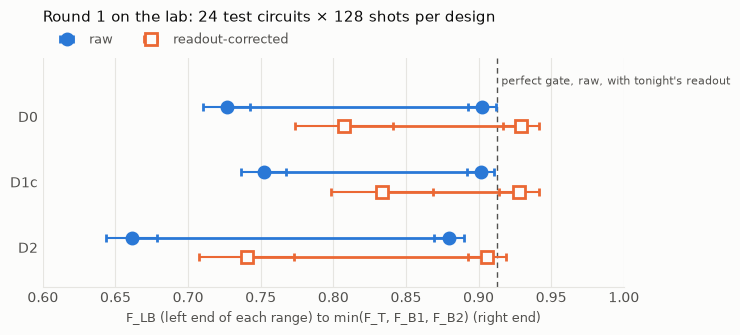

In [111]:
CHART = {"surface": "#fcfcfb", "ink": "#0b0b0b", "ink_2": "#52514e", "grid": "#e6e5e1",
         "raw": "#2a78d6", "corrected": "#eb6834"}  # categorical slots 1 and 2, checked for colour-vision separation


def perfect_gate_raw(check_counts):
    """Raw F_LB a perfect Toffoli would score with this readout check's error rates."""
    matrices = readout_matrices(check_counts)
    rates = {}
    for (name, _), (_, expected) in test_circuits(designs["D0"]).items():
        rates.setdefault(name, []).append(np.prod([matrices[q][int(expected[2 - q]), int(expected[2 - q])] for q in range(3)]))
    return sum(np.mean(r) for r in rates.values()) - 2


def plot_ranges(rows, title, reference=None):
    """Raw and readout-corrected fidelity ranges per design, each end with its 1 sigma bar (rows as from design_report)."""
    names = list(rows)
    fig, ax = plt.subplots(figsize=(7.5, 1.2 + 0.75 * len(names)), facecolor=CHART["surface"])
    ax.set_facecolor(CHART["surface"])
    low = min(rows[n][k]["F_LB"] - 2 * rows[n][k]["F_LB_err"] for n in names for k in (0, 1))
    for i, name in enumerate(names):
        y0 = len(names) - 1 - i
        for offset, k, color, marker, label in ((0.15, 0, CHART["raw"], "o", "raw"), (-0.15, 1, CHART["corrected"], "s", "readout-corrected")):
            r, y = rows[name][k], y0 + offset
            ax.plot([r["F_LB"], r["upper"]], [y, y], color=color, linewidth=2, solid_capstyle="round", zorder=2)
            ax.errorbar([r["F_LB"], r["upper"]], [y, y], xerr=[r["F_LB_err"], r["upper_err"]], fmt=marker, color=color,
                        markersize=8, markerfacecolor=color if k == 0 else CHART["surface"], markeredgewidth=2,
                        elinewidth=1.5, capsize=3, zorder=3, label=label if i == 0 else None)
    if reference:
        value, text = reference
        ax.axvline(value, color=CHART["ink_2"], linewidth=1, linestyle=(0, (4, 3)), zorder=1)
        ax.text(value, len(names) - 0.55, " " + text, color=CHART["ink_2"], fontsize=8, va="bottom", ha="left")
    ax.set_yticks(range(len(names)), list(reversed(names)), color=CHART["ink"], fontsize=10)
    ax.set_ylim(-0.6, len(names) - 0.1)
    ax.set_xlim(min(0.6, low - 0.02), 1.0)
    ax.set_xlabel("F_LB (left end of each range) to min(F_T, F_B1, F_B2) (right end)", color=CHART["ink_2"], fontsize=9)
    ax.grid(axis="x", color=CHART["grid"], linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(CHART["grid"])
    ax.tick_params(colors=CHART["ink_2"], length=0)
    ax.set_title(title, color=CHART["ink"], fontsize=11, loc="left", pad=26)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, labelcolor=CHART["ink_2"], fontsize=9)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


def claim(rows):
    """The claim rule (Decisions): highest raw F_LB; among designs tied with it within 2 sigma, the higher raw F_T."""
    ranked = sorted(rows, key=lambda n: rows[n][0]["F_LB"], reverse=True)
    top = rows[ranked[0]][0]
    tied = [n for n in ranked if top["F_LB"] - rows[n][0]["F_LB"] <= 2 * np.hypot(top["F_LB_err"], rows[n][0]["F_LB_err"])]
    return max(tied, key=lambda n: rows[n][0]["F"]["T"]), tied


if "round1" in live and "check_1" in live:
    plot_ranges(live["round1"], "Round 1 on the lab: 24 test circuits × 128 shots per design",
                (perfect_gate_raw(live["check_1"]), "perfect gate, raw, with tonight's readout"))
else:
    print("run 5.3 and 5.6 first: the chart needs round 1's results")

### 7.3 Why D2 failed

D2 was tuned on the real machine, from the `round1-A` probes, and it made the gate worse.

| | Predicted before any test result (committed 17:32) | Measured in round 1 |
|---|---|---|
| D2 − D0, raw F_LB | +0.077 | −0.065 ± 0.024 |

The probes repeated each `rxx` 5 times in a row. Fitting D0's and D2's own round 1 circuits (5.8) shows what the same gates do inside the Toffoli (actual minus commanded angle, rad):

| Pair | Inside the Toffoli circuits | `round1-A` probe, 5 repeats in a row |
|---|---|---|
| (0, 1) | +0.073 ± 0.048 | −0.135 ± 0.009 |
| (0, 2) | +0.097 ± 0.023 | −0.179 ± 0.010 |
| (1, 2) | +0.056 ± 0.064 | +0.037 ± 0.014 |

Inside the circuits the π/2 gates turn slightly too far, while the probe showed them falling short; D2 added 0.14 to 0.18 rad to gates that were already a little over. The lesson: calibrate a gate in the same setting it is used in. Two causes are possible, and round 2's re-probe tells them apart: a gate repeated 5 times in a row behaves differently from one inside a circuit, or the machine changed after 16:59. The fit also says that about 5% of shots carry random error that no angle can fix, which is why a perfect gate would score 0.913 raw while our best designs score 0.73 to 0.75.

Round 2's re-probe answered it: the machine drifted. At 21:42 the same 5-repeat probe gave (0, 2) +0.026 and (0, 1) −0.077, against −0.179 and −0.135 at 16:59, while the readout held steady (H7). So D2's calibration was out of date by the time its tests ran (17:15 to 18:22). D3, tuned from round 1's own circuits, lost too in round 2 (0.699 against D1c's 0.756); with the angles still moving, its corrections were most likely out of date as well. On this machine the `rxx` angles moved by up to 0.2 rad within a few hours, so a calibration only helps if it is measured right before it is used, and in the same setting. D1c needs no calibration, and its score held steady (0.752, then 0.756). A likely reason, not yet tested: its largest gates sit on pair (1, 2), whose angle barely moved (+0.037, then +0.017), and its gates on the drifting pairs (0, 1) and (0, 2) are small π/4 turns.

### 7.4 Hypotheses after both rounds

| | Hypothesis (4.1) | Verdict |
|---|---|---|
| H1 | one fixed over-rotation on every `rxx` | false in the probe (the three errors differ in sign). Inside the circuits the three fitted errors agree within their error bars (+0.07 to +0.10) |
| H2 | the error grows with the angle | partly in the probe (ratio −0.23 ± 0.09). Not shown on hardware: D1c, with smaller angles, ties D0 |
| H3 | ion pairs differ | true in the probe ((0, 1) minus (0, 2) = +0.044 ± 0.013, 3.3σ). Not significant inside the circuits |
| H4 | readout reads 1 as 0 more often than 0 as 1 | true on q1 and q2; within its error on q0 |
| H5 | readout errors are independent | true (p = 0.649), so per-qubit correction |
| H6 | random gate error is small | true on (0, 1) and (0, 2) in the probe, not on (1, 2) (contrast 0.84 ± 0.06). Inside the circuits about 5% of shots carry random error |
| H7 | the device stays calibrated | false: readout held steady (every rate changed by 1.6σ or less), but the `rxx` angles drifted between 16:59 and 21:42: (0, 2) from −0.179 to +0.026 (10σ), (0, 1) from −0.135 to −0.077 (3.3σ), combined p = 0.000. D1c's score held steady across the rounds |
| H8 | a gate's error inside D0 equals its error in the probe | false: D2 − D0 was −0.065 ± 0.024 against the +0.077 predicted |

### 7.5 Round 2 and the claim

Round 2 ran D1c again next to D3, D2 retuned from its own round 1 circuit results (5.8; Decisions, "Changes after round 1"). The next cell needs 6.3. It draws the final ranges, applies the claim rule written before any round 2 result (Decisions), and prints the claimed circuit's OpenQASM, which is what we hand in.

Round 2 ran from 21:42 to 21:44, with D1c and D3 taking turns. H7 found drift (6.2), so the rounds are not pooled, and each is reported on its own (6.3).

| Design | Raw F_LB | Raw upper end | Readout-corrected range | S_TT (raw) |
|---|---|---|---|---|
| D1c | 0.756 ± 0.015 | 0.907 ± 0.009 | [0.823 ± 0.036, 0.929 ± 0.013] | 0.931 |
| D3 | 0.699 ± 0.017 | 0.885 ± 0.010 | [0.766 ± 0.037, 0.906 ± 0.015] | 0.927 |

D1c − D3 = +0.057 (2σ = 0.045): different. D1c, the only design that ran in both rounds, moved from 0.752 to 0.756 (+0.004, 2σ = 0.043), so it held steady while the gate angles drifted.

The claim. By the rule written at 21:50, before any round 2 result, we claim D1c: it has the highest raw F_LB in round 2, and no other round 2 design is within 2σ of it. D0 ran only in round 1, where it was tied with D1c (+0.025, 2σ = 0.044). Under the rule a tie goes to the higher raw F_T, and D1c's is higher (0.938 against 0.920), so the claim is D1c either way. D1c ties the starter kit's baseline and clearly beats both of our calibrated designs. Its readout-corrected range puts its process fidelity between about 0.82 and 0.93.

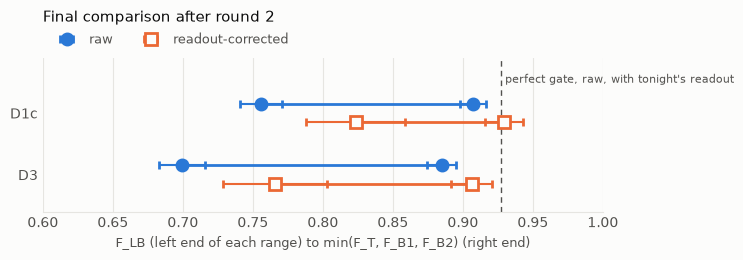

claimed: D1c, raw F_LB 0.756 ± 0.015, raw F_T 0.931, readout-corrected range [0.823, 0.929]
no other design is within 2 sigma
D1c as OpenQASM (the circuit we hand in):
OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];
ry(pi/2) q[1];
rxx(-pi/4) q[1],q[0];
rz(pi/2) q[0];
ry(pi/4) q[0];
rz(-pi/2) q[0];
ry(-pi/2) q[1];
rz(pi/4) q[1];
ry(pi/2) q[2];
rxx(-pi/2) q[2],q[1];
ry(pi/2) q[1];
rz(-pi/2) q[1];
rxx(pi/4) q[1],q[0];
rz(-pi/2) q[0];
ry(pi/4) q[0];
rz(pi/2) q[0];
ry(-pi/2) q[1];
rz(-pi/4) q[1];
ry(-pi/2) q[2];
rz(pi/2) q[2];
ry(pi/2) q[2];
rxx(-pi/2) q[2],q[1];
rz(pi/2) q[1];
ry(pi/2) q[1];
rz(-pi/2) q[1];
ry(-pi/2) q[2];
rz(pi/2) q[2];
ry(pi/2) q[2];
rxx(-pi/4) q[2],q[0];
rz(pi/2) q[0];
ry(pi/4) q[0];
rz(-pi/2) q[0];
ry(-pi/2) q[2];
rz(pi/4) q[2];


In [112]:
if "final" not in live:
    print("run 6.3 first: the claim needs round 2's final comparison")
else:
    check = pool(live["check_1"], live["check_2"]) if live.get("p_drift", 0) >= 0.05 else live["check_2"]
    title = ("Final comparison, both rounds pooled" if live.get("p_drift", 0) >= 0.05
             else "Round 2: D1c and D3 side by side (rounds not pooled: the angles drifted)")
    plot_ranges(live["final"], title, (perfect_gate_raw(check), "perfect gate, raw, with this round's readout"))
    chosen, tied = claim(live["final"])
    raw, corrected = live["final"][chosen]
    print(f"claimed: {chosen}, raw F_LB {raw['F_LB']:.3f} ± {raw['F_LB_err']:.3f}, raw F_T {raw['F']['T']:.3f}, "
          f"readout-corrected range [{corrected['F_LB']:.3f}, {corrected['upper']:.3f}]")
    others = [n for n in tied if n != chosen]
    print(f"tied within 2 sigma with: {others}, so the higher raw F_T decided" if others else "no other design is within 2 sigma")
    live["claimed"] = chosen
    print(f"{chosen} as OpenQASM (the circuit we hand in):")
    print(qasm2.dumps(live["designs"][chosen]))

### 7.6 What we changed during the session, and why

1. 16:10: the readout circuit that prepares 000 went out as `rz(0)` instead of an empty circuit, so the lab never received an empty program.
2. 17:10: the lab writes each shot as a number from 0 to 7, not as the bitstrings the starter kit describes. We wrote a reader, and our readout check confirmed the bit order (every prepared state read mostly as itself).
3. 17:20: the relay failed to save circuit 18 of `round1-B` and did not charge it. We added resume support, so rerunning a send cell sends only what did not go out (`round1-B-rest`).
4. 20:47: one request for all 86 result files took longer than the relay's 30-second limit, so results are now fetched one queue ID at a time.
5. 21:10: round 1 showed the probe-based tuning failed (H8), so round 2 tested D3, retuned on its own circuit results, in place of a repeat of D0.
6. 21:50: before any round 2 result, we fixed the rule that picks the design we claim.
7. 22:20: we planned one more probe of pair (0, 2) with 256 of the 288 spare shots, to measure how fast its angle keeps moving, but it was not sent before the lab's queue closed at midnight. 288 shots were left unused.

### 7.7 What the data does not show

- The in-circuit fit is rough: it reproduces D0 at 0.757 against the observed 0.727 (5.8). One uniform share of random error cannot capture every error the machine makes.
- D0 ran in round 1 only and D3 in round 2 only, so their gap crosses the two rounds, and the angles drifted in between (H7), so we do not compare them directly. Only designs that ran side by side are compared.
- D1c's own gates were never probed, and a fit on D1c alone was not informative.
- At 128 shots per test (256 where pooled), gaps smaller than about 0.03 to 0.04 cannot be told apart.
- The readout-corrected numbers assume our readout model (H5 supports independent qubits), and they count the `rx(π)` used in the readout check as readout error.
- Why D1c held steady is a hypothesis (its large gates sit on the pair that drifted least); we did not test it.
- So far this is one machine, on one evening. We could not use the mystery backend (we had no URL for it), and IonQ comes after midnight.

## 8. IonQ Forte 1

From midnight to noon the challenge continued on IonQ's Forte 1 trapped-ion computer, with the same goal, gates and wires. We fixed this plan at 23:45, before any IonQ result:

| Batch | Circuits | What it gives |
|---|---|---|
| 0, IonQ's free simulator | the readout check, D0 and D1c with no noise; then all of batch 1 with IonQ's forte-1 noise model | a bit-order check (every circuit must come out exact) and a run of the whole path before any paid job |
| 1 | the readout check and the 24 tests of D0, D1c and their known-shift copies (8.1) | the designs side by side, and the training data for method 2 |
| 2 | D1c and the trained designs D5 (from D0) and D6 (from D1c) side by side | the measured test of the trained designs |

What changed during the night, each written down before the result it affected:

1. 00:11: IonQ's estimate was $20.08 per circuit, its minimum charge, the same at 128, 1,024 or 2,500 shots, with a predicted queue of 5.1 hours. So we use 1,024 shots per circuit (more shots cost nothing extra) and first ran batch 0 on the simulator.
2. 00:44: we froze the fitting method (8.6), after the blind tests of Section 9 and before fitting any IonQ data.
3. 01:44: we sent batch 1 to the real Forte 1 (104 circuits).
4. 03:25, before the Forte 1 fit: a trained design goes to batch 2 only if it is predicted to gain at least 0.02 in raw F_LB, with a fit that matches the data (deviance per degree of freedom under 1.5).
5. 05:08: neither D5 nor D6 met that rule (8.7), but neither had ever been measured against D1c, so we sent batch 2 anyway. We made this choice after seeing the predictions; the test itself still runs all three designs side by side in one job.
6. 05:55: reading back the circuits IonQ ran (8.9), we found that IonQ's compiler had removed the entangling gates from many of our test circuits, including every one of D1c's, so batches 1 and 2 do not compare our designs.
7. 06:15: we sent D0 and D1c again in IonQ's native gates, translated gate by gate so that every `rxx` runs (8.10). We sent it before an organizer had said whether native gates are allowed.

The claim rule (23:45): the IonQ claim is the design with the highest raw F_LB in the last batch where the finalists ran side by side; a tie within 2σ goes to the higher raw F_T. The claim is for this machine: a trained design only fits the machine and the hours it was trained on.

Every job went through `run_without_debiasing`, since debiasing is not allowed. `evidence/ionq_jobs.csv` lists every circuit of every job with its job ID, and `evidence/ionq/` holds each job's circuits and raw counts, so the cells below need no IonQ key.

### 8.1 Why each base needs a known-shift copy

Method 2 finds each gate's error e, how far its `rxx` turns past the angle we ask for, and the trained design asks for e less. D0 is an exact Toffoli, so every test is at its best score when e = 0, and an error of +e costs the same as −e: the counts give the size of e but not its sign (below). A wrong sign would double the error instead of removing it. The shifted copy turns every `rxx` 0.15 rad further on purpose, so on the machine it misses by 0.15 + e, and +e and −e give clearly different scores. Fitting both designs together gives the size and the sign. If IonQ's compiler did not pass our angle changes through, D0 and its shifted copy would score the same.

In [ ]:
# 8.1 D0 alone scores the same for errors of +e and -e; its shifted copy does not (exact, no other noise)
SHIFT = 0.15  # the shifted copies turn every rxx this much further in its own direction


def shifted(base):
    """The base design with every rxx turned SHIFT further in its own direction."""
    return correct_each(base, {gate: -SHIFT * np.sign(gate[1]) for gate in rxx_gates(base)})


def mean_pass_rate(design, error):
    """Mean pass rate over the 24 tests when every rxx turns `error` rad past its angle."""
    turned = correct_each(design, {gate: -error for gate in rxx_gates(design)})
    return np.mean([Statevector(qc).probabilities_dict().get(expected, 0) for qc, expected in test_circuits(turned).values()])


for name, design in (("D0", designs["D0"]), ("D0-shifted", shifted(designs["D0"]))):
    print(f"{name:10s} mean pass rate with an error of +0.1 rad on every rxx: {mean_pass_rate(design, 0.1):.4f}, with -0.1 rad: {mean_pass_rate(design, -0.1):.4f}")

D0         mean pass rate with an error of +0.1 rad on every rxx: 0.9880, with -0.1 rad: 0.9880
D0-shifted mean pass rate with an error of +0.1 rad on every rxx: 0.9372, with -0.1 rad: 0.9871


### 8.2 Helpers: one job per batch, logged, with its results saved as evidence

`send_ionq` checks every circuit (4.2), prices a paid job, and sends all its circuits as one job with debiasing off; a label is never sent twice. `collect_ionq` reads a batch's counts from `evidence/ionq/`, and with an IonQ backend it first fetches and saves them. The send cells are kept as we ran them, with SUBMIT = False, so running this notebook sends nothing.

In [ ]:
# 8.2 IonQ helpers (they need an IonQ key only to send or to fetch; everything else reads evidence/ionq)
import csv
from collections import Counter

from toffoli_challenge.ionq import counts_to_bitstrings, estimate_cost, gate_counts, measured_copy, record_job, run_without_debiasing

IONQ_SHOTS = 1024  # IonQ charges its minimum per circuit up to a few thousand shots, so 1,024 costs the same as 128
IONQ_LOG = ROOT / "submissions" / "ionq_jobs.json"  # local log written by record_job
IONQ_EVIDENCE = ROOT / "evidence" / "ionq_jobs.csv"  # one row per circuit of every job
IONQ_RESULTS = ROOT / "evidence" / "ionq"  # each job's circuits and raw counts
PLAIN = ("D0", "D1c")
TRAINED = {"D0": "D5", "D1c": "D6"}


def batch_jobs(candidates):
    """The readout check and all 24 tests of each design, in rotated order, at IONQ_SHOTS."""
    return readout_jobs(IONQ_SHOTS) + test_jobs(candidates, shots=IONQ_SHOTS)


def job_id(label):
    """The IonQ job ID of a sent batch, from the evidence file (None if it was never sent)."""
    if not IONQ_EVIDENCE.exists():
        return None
    with open(IONQ_EVIDENCE) as f:
        ids = {row["job_id"] for row in csv.DictReader(f) if row["label"] == label}
    assert len(ids) <= 1, (label, ids)
    return ids.pop() if ids else None


def results_file(label, kind):
    return IONQ_RESULTS / f"{label}_{job_id(label)}_{kind}.json"


def send_ionq(backend, label, jobs, submit=False):
    """Check every circuit and send them as one job with debiasing off. Refuses a second send of the same label."""
    if job_id(label):
        print(f"{label} was already sent as job {job_id(label)}: not sent again")
        return None
    preflight(jobs, exact_designs=PLAIN)
    circuits = [measured_copy(j["circuit"], name=f"{label}-{i}") for i, j in enumerate(jobs)]
    paid = "qpu" in backend.name
    if paid:
        prices = {}
        for c in circuits:
            if gate_counts(c) not in prices:
                prices[gate_counts(c)] = estimate_cost(backend, c, IONQ_SHOTS)["estimated_total_cost"]
        each = [prices[gate_counts(c)] for c in circuits]
        print(f"IonQ's estimate for {label}: ${sum(each):,.2f} for {len(circuits)} circuits x {IONQ_SHOTS} shots")
    if not submit:
        print(f"{label}: {len(circuits)} circuits ready for {backend.name}; not sent (SUBMIT is False)")
        return None
    if paid and input(f"type {label} to send {len(circuits)} circuits x {IONQ_SHOTS} shots to {backend.name}: ").strip() != label:
        print("not sent")
        return None
    job = run_without_debiasing(backend, circuits, shots=IONQ_SHOTS)
    entry = record_job(job, backend.name, label, IONQ_SHOTS, path=IONQ_LOG, circuits=len(circuits))
    IONQ_RESULTS.mkdir(parents=True, exist_ok=True)
    infos = [{**j["info"], "qasm": qasm2.dumps(j["circuit"])} for j in jobs]
    (IONQ_RESULTS / f"{label}_{entry['job_id']}_circuits.json").write_text(json.dumps(infos, indent=1))
    new_file = not IONQ_EVIDENCE.exists()
    with open(IONQ_EVIDENCE, "a", newline="") as f:
        writer = csv.writer(f)
        if new_file:
            writer.writerow(["job_id", "label", "backend", "submitted_at", "index", "shots", "kind", "design", "test_set", "labels", "expected", "prepared"])
        for i, info in enumerate(infos):
            writer.writerow([entry["job_id"], label, backend.name, entry["submitted_at"], i, IONQ_SHOTS, info["kind"], info.get("design", ""),
                             info.get("test_set", ""), info.get("labels", ""), info.get("expected", ""), info.get("prepared", "")])
    print(f"{label}: sent {len(circuits)} circuits to {backend.name} as job {entry['job_id']}")
    return job


def collect_ionq(label, backend=None):
    """[(entry, counts)] of a sent batch from evidence/ionq; with a backend, fetch and save the counts first."""
    if job_id(label) is None:
        print(f"{label} was never sent")
        return None
    infos = json.loads(results_file(label, "circuits").read_text())
    if not results_file(label, "counts").exists():
        if backend is None:
            print(f"{label} (job {job_id(label)}): no saved counts yet")
            return None
        job = backend.retrieve_job(job_id(label))
        if job.status().name != "DONE":
            print(f"{label} (job {job_id(label)}) is {job.status().name}: collect again later")
            return None
        result = job.result()
        results_file(label, "counts").write_text(json.dumps([dict(Counter(counts_to_bitstrings(result.get_counts(i)))) for i in range(len(infos))], indent=1))
    counts = json.loads(results_file(label, "counts").read_text())
    assert len(counts) == len(infos)
    return list(zip(infos, counts))


def wrong_shots(done, names):
    """Share of shots that came out wrong in the readout check and in each design's three test sets."""
    tally = {}
    for entry, counts in done:
        want = entry["prepared"] if entry["kind"] == "readout" else entry["expected"]
        key = "readout check" if entry["kind"] == "readout" else f"{entry['design']} {entry['test_set']}"
        wrong, total = tally.get(key, (0, 0))
        tally[key] = (wrong + sum(v for k, v in counts.items() if k != want), total + sum(counts.values()))
    for key in ["readout check"] + [f"{n} {s}" for n in names for s in TEST_SETS]:
        wrong, total = tally[key]
        print(f"   {key:16s} {wrong:5d} of {total} shots wrong ({wrong / total:.2%})")

### 8.3 IonQ's price and queue, and the backends

This cell needs an IonQ key in `.env` (`IONQ_API_KEY`, never printed or committed). Without one it says so, and the rest of Section 8 still runs from the saved results. At 00:11 IonQ's estimate for one test circuit was $20.08 at 128 shots and also at 1,024 and 2,500 shots, with a predicted queue of 5.1 hours.

In [ ]:
# 8.3 IonQ backends and IonQ's current estimate for one test circuit (needs IONQ_API_KEY in .env)
load_env(ROOT / ".env")
qpu = sim = None
if not os.environ.get("IONQ_API_KEY"):
    print("no IonQ key: the cells below read the saved results in evidence/ionq")
else:
    from qiskit_ionq import IonQProvider

    provider = IonQProvider()
    qpu, sim = provider.get_backend("qpu.forte-1"), provider.get_backend("simulator")
    example_circuit = measured_copy(next(iter(test_circuits(designs["D0"]).values()))[0])
    for shots in (128, 1024):
        estimate = estimate_cost(qpu, example_circuit, shots)
        print(f"one D0 test circuit at {shots} shots: ${estimate['estimated_total_cost']:.2f}, run time {estimate['estimated_execution_time'] / 1000:.1f} s")

one D0 test circuit at 128 shots: $20.08, run time 2.8 s
one D0 test circuit at 1024 shots: $20.08, run time 19.1 s


### 8.4 Batch 0: the free rehearsal on IonQ's simulator

With no noise, the simulator must reproduce every readout state and every D0 and D1c test exactly. That checks the bit order before any paid job: the lab's output format surprised us in Section 4. Then all of batch 1 ran with IonQ's forte-1 noise model, through the same code the paid job would use.

In [ ]:
# 8.4 Batch 0, no noise (job rehearsal-ideal): every readout state and every D0 and D1c test must come out exactly
rehearsal_ideal = json.loads(results_file("rehearsal-ideal", "probabilities").read_text())
infos = json.loads(results_file("rehearsal-ideal", "circuits").read_text())
exact_count = sum(1 for info, p in zip(infos, rehearsal_ideal) if p.get(info["prepared"] if info["kind"] == "readout" else info["expected"], 0) > 0.999)
print(f"job {job_id('rehearsal-ideal')}: {exact_count} of {len(infos)} circuits came out exactly as expected")

job 01a1715b-ee71-74de-88c8-8f1b5bfb76dc: 56 of 56 circuits came out exactly as expected


### 8.5 Batch 0 with IonQ's forte-1 noise model

In [ ]:
# 8.5 Batch 0 with IonQ's forte-1 noise model (job sim-batch1): the designs side by side, and where the wrong shots are
sim_batch_1 = collect_ionq("sim-batch1")
BATCH_1 = ["D0", "D0-shifted", "D1c", "D1c-shifted"]
print(f"job {job_id('sim-batch1')}, IonQ simulator with the forte-1 noise model, 1,024 shots per circuit")
design_report(sim_batch_1, readout_counts(sim_batch_1), BATCH_1)
wrong_shots(sim_batch_1, ["D0", "D1c"])

job 01a1715d-23b5-7267-a58c-954fcce0ee60, IonQ simulator with the forte-1 noise model, 1,024 shots per circuit
D0 raw     S_TT 1.000±0.000   F_B1 0.978±0.002   F_B2 0.978±0.002   range [0.956±0.002, 0.978±0.002]
D0 corr.   S_TT 1.000±0.001   F_B1 0.978±0.002   F_B2 0.978±0.002   range [0.956±0.004, 0.978±0.002]
D0-shifted raw S_TT 0.988±0.001   F_B1 0.949±0.002   F_B2 0.953±0.002   range [0.891±0.004, 0.949±0.002]
D0-shifted corr. S_TT 0.988±0.002   F_B1 0.949±0.003   F_B2 0.953±0.003   range [0.891±0.005, 0.949±0.003]
D1c raw    S_TT 1.000±0.000   F_B1 1.000±0.000   F_B2 1.000±0.000   range [1.000±0.001, 1.000±0.000]
D1c corr.  S_TT 1.000±0.001   F_B1 1.000±0.001   F_B2 1.000±0.001   range [1.000±0.004, 1.000±0.001]
D1c-shifted raw S_TT 0.955±0.002   F_B1 0.956±0.002   F_B2 0.986±0.001   range [0.897±0.004, 0.955±0.002]
D1c-shifted corr. S_TT 0.955±0.003   F_B1 0.956±0.003   F_B2 0.986±0.002   range [0.897±0.005, 0.955±0.002]
raw F_LB(D1c) - F_LB(D0) = +0.044, 2 sigma = 0.005 -> diffe

IonQ's job record confirms the forte-1 noise model ran. Yet the readout check and D1c came back without a single wrong shot, and D0's truth table was perfect while 2.2% of its phase-test shots were wrong. The reason, found later (8.9), is that IonQ compiles each circuit before simulating it: its compiler removed every two-qubit gate from D1c's tests and from all truth-table tests, and left two in each of D0's phase tests. We used this run only to check the code path. It still shows why a truth table alone is not enough: D0's compiled circuits had perfect truth tables and wrong phases.

### 8.6 The frozen fit

Method 2 (5.8) fits, for each `rxx`, how far it turns past the angle we ask for, from the counts of a base design and its shifted copy. Before using it on IonQ we tested it blind on simulated machines (Section 9), and changed three things, then froze the code at 00:44, before fitting any IonQ data:

- a grid of starting points (3 per error), because the first version stopped in a wrong minimum when fitting D1c;
- one error per pair and gate sign, because D1c's pair (0, 1) has a +π/4 and a −π/4 gate, which can err differently;
- a sign test for each error: we force the error to the other side of zero, refit the rest, and correct the error only if that costs at least 2 in log-likelihood (2σ). Otherwise that gate keeps its base angle.

The fit also reports how well its model matches the data (deviance per degree of freedom, about 1 for a good match) and the raw F_LB it predicts for each design.

In [ ]:
# 8.6 The frozen fit (00:44): grid of starts, one error per pair and gate sign, and a sign test for each error
import itertools

from scipy.optimize import minimize

SETTLED = 2.0  # log-likelihood cost of the opposite sign needed to correct an error (2 sigma)
NELDER = {"method": "Nelder-Mead"}


def fit_with_signs(done, check_counts, designs_to_fit, refits=12, seed=3, grid=(-0.25, 0.0, 0.25)):
    """Fit each (pair, gate sign) error and the share without random error; test each error's sign before using it."""
    matrices = readout_matrices(check_counts)
    full = np.array([[1.0]])
    for q in (2, 1, 0):
        full = np.kron(full, matrices[q])
    data = []
    for entry, counts in done:
        if entry["kind"] == "test" and entry["design"] in designs_to_fit:
            n = np.zeros(8)
            for outcome, c in counts.items():
                n[int(outcome, 2)] += c
            data.append((gate_list(qasm2.loads(entry["qasm"], custom_instructions=qasm2.LEGACY_CUSTOM_INSTRUCTIONS)), n))
    group = lambda where, theta: (where, int(np.sign(theta)))
    groups = sorted({group(w, t) for g, _ in data for name, w, t in g if name == "rxx"}, key=str)

    def probabilities(gates, errors, keep):
        psi = np.zeros(8, dtype=complex)
        psi[0] = 1
        for name, where, theta in gates:
            if name == "rxx":
                a = theta + errors[group(where, theta)]
                psi = (np.cos(a / 2) * np.eye(8) - 1j * np.sin(a / 2) * XX_ON[where]) @ psi
            else:
                psi = embed(rotation(name, theta), where) @ psi
        return full @ (keep * np.abs(psi) ** 2 + (1 - keep) / 8)

    def nll(x, sample=data):
        if not 0 < x[-1] <= 1:
            return 1e12
        errors = dict(zip(groups, x[:-1]))
        return -sum(np.sum(n * np.log(np.clip(probabilities(g, errors, x[-1]), 1e-12, 1))) for g, n in sample)

    coarse = [minimize(nll, (*s, 0.95), options={"xatol": 1e-3, "fatol": 1e-2, "maxiter": 800}, **NELDER)
              for s in itertools.product(grid, repeat=len(groups))]
    best = minimize(nll, min(coarse, key=lambda f: f.fun).x, options={"xatol": 1e-5, "fatol": 1e-4, "maxiter": 4000}, **NELDER)
    x = best.x
    sign_cost = {}
    for k, g in enumerate(groups):  # force this error to the other side of zero, refit the rest
        side = np.sign(x[k]) or 1.0
        start = x.copy()
        start[k] = -x[k]
        flipped = minimize(lambda y: nll(y) + 1e6 * max(0.0, side * y[k]) ** 2, start, options={"xatol": 1e-4, "fatol": 1e-3, "maxiter": 3000}, **NELDER)
        sign_cost[g] = float(flipped.fun - best.fun)
    rng = np.random.default_rng(seed)
    boot = [minimize(nll, x, args=([(gates, rng.multinomial(int(n.sum()), n / n.sum()).astype(float)) for gates, n in data],),
                     options={"xatol": 1e-4, "fatol": 1e-3, "maxiter": 4000}, **NELDER).x for _ in range(refits)]
    sigma = np.std(boot, axis=0, ddof=1)
    errors = dict(zip(groups, x[:-1]))
    keep = float(x[-1])
    deviance = sum(2 * np.sum(n[n > 0] * np.log(n[n > 0] / (probabilities(g, errors, keep) * n.sum())[n > 0])) for g, n in data)
    return {"errors": errors, "sigma": dict(zip(groups, sigma[:-1])), "sign_cost": sign_cost, "keep": keep, "group": group,
            "used": {g: (e if sign_cost[g] >= SETTLED else 0.0) for g, e in errors.items()}, "probabilities": probabilities,
            "deviance_per_dof": float(deviance / (7 * len(data) - len(groups) - 1))}


def train_both(done, check):
    """D5 from D0 and its shifted copy, D6 from D1c and its shifted copy; prints the fit and the gain it predicts."""
    out = {}
    for base_name, new in TRAINED.items():
        base = designs[base_name]
        fit = fit_with_signs(done, check, (base_name, base_name + "-shifted"))
        fixed = correct_each(base, {(pair, theta): fit["used"][fit["group"](pair, theta)] for pair, theta in rxx_gates(base)})
        validate_submission_circuit(fixed)
        predicted = {name: float(expected_raw_lb(c, fit["probabilities"], fit["errors"], fit["keep"])) for name, c in ((base_name, base), (new, fixed))}
        out[new] = {**fit, "base": base_name, "circuit": fixed, "predicted": predicted, "worth": any(v != 0 for v in fit["used"].values())}
        print(f"{new} from {base_name} and its shifted copy (error = how far each rxx turns past its angle, rad):")
        for g, e in fit["errors"].items():
            verdict = "sign settled: corrected" if fit["used"][g] else "sign not settled: not corrected"
            print(f"   {g[0]}, {'+' if g[1] > 0 else '-'} gates: {e:+.3f} ± {fit['sigma'][g]:.3f}; the other sign costs {fit['sign_cost'][g]:.1f} -> {verdict}")
        print(f"   share without random error {fit['keep']:.3f}; deviance per degree of freedom {fit['deviance_per_dof']:.2f} (about 1 if the model fits)")
        if out[new]["worth"]:
            print(f"   predicted raw F_LB on the fitted model: {base_name} {predicted[base_name]:.3f}, {new} {predicted[new]:.3f}, gain {predicted[new] - predicted[base_name]:+.3f}")
            print(f"   {new} rxx angles / pi:", [round(float(i.operation.params[0]) / np.pi, 4) for i in fixed.data if i.operation.name == "rxx"])
        else:
            print(f"   no error has a settled sign, so {new} would equal {base_name}")
    return out

### 8.7 Batch 1 on the real Forte 1

Job `01a17197-3f99-727d-87c1-349b513bb629`: 104 circuits x 1,024 shots, sent 01:45, run between 01:51 and 04:34 (14.6 minutes of machine time between other users' jobs), debiasing off according to IonQ's job record. IonQ's estimate was $2,088.32.

In [ ]:
# 8.7 Batch 1 on Forte 1 (job ionq-batch1): the four designs side by side, and where the wrong shots are
forte_1 = collect_ionq("ionq-batch1")
print(f"job {job_id('ionq-batch1')}, IonQ Forte 1, 1,024 shots per circuit")
forte_rows_1, _ = design_report(forte_1, readout_counts(forte_1), BATCH_1)
wrong_shots(forte_1, ["D0", "D1c"])

job 01a17197-3f99-727d-87c1-349b513bb629, IonQ Forte 1, 1,024 shots per circuit
D0 raw     S_TT 0.992±0.001   F_B1 0.981±0.002   F_B2 0.978±0.002   range [0.951±0.002, 0.978±0.002]
D0 corr.   S_TT 1.001±0.002   F_B1 0.990±0.002   F_B2 0.988±0.002   range [0.979±0.006, 0.988±0.002]
D0-shifted raw S_TT 0.981±0.002   F_B1 0.947±0.002   F_B2 0.950±0.002   range [0.878±0.004, 0.947±0.002]
D0-shifted corr. S_TT 0.991±0.002   F_B1 0.956±0.003   F_B2 0.959±0.003   range [0.905±0.006, 0.956±0.003]
D1c raw    S_TT 0.991±0.001   F_B1 0.991±0.001   F_B2 0.989±0.001   range [0.970±0.002, 0.989±0.001]
D1c corr.  S_TT 1.000±0.002   F_B1 1.000±0.002   F_B2 0.998±0.002   range [0.999±0.006, 0.998±0.002]
D1c-shifted raw S_TT 0.953±0.002   F_B1 0.962±0.002   F_B2 0.979±0.002   range [0.894±0.004, 0.953±0.002]
D1c-shifted corr. S_TT 0.962±0.003   F_B1 0.971±0.002   F_B2 0.988±0.002   range [0.921±0.006, 0.962±0.003]
raw F_LB(D1c) - F_LB(D0) = +0.020, 2 sigma = 0.006 -> different
raw F_LB(D1c) - F_LB(D1c-s

On these numbers D1c is ahead of D0, but 8.9 shows that they do not compare our designs. IonQ's compiler removed every two-qubit gate from D1c's test circuits and from all truth-table tests, and left two native ZZ gates in each of D0's phase tests. So D1c's score is the readout of circuits with no entangling gate, and D0's loss comes from those two ZZ gates. We found this only after both batches had run.

In [ ]:
# 8.7 The frozen fit on Forte 1 batch 1 (about 15 minutes), then the batch 2 rule written at 03:25
trained = train_both(forte_1, readout_counts(forte_1))
for new, r in trained.items():
    gain = r["predicted"][new] - r["predicted"][r["base"]]
    passes = r["worth"] and gain >= 0.02 and r["deviance_per_dof"] < 1.5
    print(f"{new}: predicted gain {gain:+.4f}, deviance per degree of freedom {r['deviance_per_dof']:.4f} -> {'meets' if passes else 'does not meet'} the batch 2 rule")

D5 from D0 and its shifted copy (error = how far each rxx turns past its angle, rad):
   (0, 1), + gates: +0.052 ± 0.003; the other sign costs 71.2 -> sign settled: corrected
   (0, 2), + gates: -0.042 ± 0.005; the other sign costs 20.0 -> sign settled: corrected
   (1, 2), - gates: -0.067 ± 0.007; the other sign costs 37.9 -> sign settled: corrected
   share without random error 1.000; deviance per degree of freedom 1.50 (about 1 if the model fits)
   predicted raw F_LB on the fitted model: D0 0.961, D5 0.972, gain +0.011
   D5 rxx angles / pi: [0.4835, 0.5134, 0.4835, 0.5134, -0.2287]
D6 from D1c and its shifted copy (error = how far each rxx turns past its angle, rad):
   (0, 1), - gates: +0.004 ± 0.007; the other sign costs 0.1 -> sign not settled: not corrected
   (0, 1), + gates: +0.040 ± 0.009; the other sign costs 2.1 -> sign settled: corrected
   (0, 2), - gates: +0.021 ± 0.007; the other sign costs 4.4 -> sign settled: corrected
   (1, 2), - gates: +0.007 ± 0.004; the other s

The fit assumes that the machine ran our circuits as written, with 5 `rxx` gates each. It did not (8.9), so D5 and D6 were fitted to circuits the machine never ran, and the batch 2 rule above was applied to predictions for those circuits.

### 8.8 Batch 2 on the real Forte 1

Job `01a17252-fb04-7602-be87-5c4468214d59`: the readout check, D1c, D5 and D6, 80 circuits x 1,024 shots in one job, sent 05:10 and run between 05:12 and 05:31 (10.4 minutes of machine time), debiasing off according to IonQ's job record. IonQ's estimate was $1,606.40. D5 and D6 are the designs from 8.7, loaded from `evidence/ionq/forte1_fit_D5_D6.json`. D1c ran in both batches, so it also shows whether the machine moved in between.

In [ ]:
# 8.8 Batch 2 on Forte 1 (job ionq-batch2): D1c, D5 and D6 side by side, the claim rule, and D1c's drift since batch 1
from scipy.stats import chi2


def batch_drift(done_1, done_2, name):
    """Did one design's 24 pass rates change between two batches? One combined chi-square, as in 6.2."""
    rates = lambda done: {(e["test_set"], e["labels"]): (c.get(e["expected"], 0), sum(c.values()))
                          for e, c in done if e["kind"] == "test" and e["design"] == name}
    one, two = rates(done_1), rates(done_2)
    z = []
    for key, (k1, n1) in one.items():
        k2, n2 = two[key]
        p = (k1 + k2 + 1) / (n1 + n2 + 2)
        z.append((k2 / n2 - k1 / n1) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2)))
    total = float(np.sum(np.square(z)))
    return total, float(chi2.sf(total, df=len(z)))


forte_2 = collect_ionq("ionq-batch2", backend=qpu)
if forte_2 is not None:
    fit_record = json.loads((IONQ_RESULTS / "forte1_fit_D5_D6.json").read_text())
    print(f"job {job_id('ionq-batch2')}, IonQ Forte 1, 1,024 shots per circuit")
    forte_rows_2, _ = design_report(forte_2, readout_counts(forte_2), ["D1c", "D5", "D6"])
    wrong_shots(forte_2, ["D1c", "D5", "D6"])
    for new in ("D5", "D6"):
        a, b = forte_rows_2[new][0], forte_rows_2["D1c"][0]
        gap, two_sigma = a["F_LB"] - b["F_LB"], 2 * np.hypot(a["F_LB_err"], b["F_LB_err"])
        print(f"{new} - D1c = {gap:+.3f}, 2 sigma = {two_sigma:.3f} -> {'better' if gap > two_sigma else 'worse' if gap < -two_sigma else 'tied'}; "
              f"{new} predicted {fit_record[new]['predicted'][new]:.3f}, measured {a['F_LB']:.3f}")
    claimed_ionq, tied_ionq = claim(forte_rows_2)
    print(f"IonQ claim (highest raw F_LB in batch 2, ties to the higher raw F_T): {claimed_ionq}"
          + (f", tied with {', '.join(t for t in tied_ionq if t != claimed_ionq)}" if len(tied_ionq) > 1 else ""))
    drift_total, p_drift = batch_drift(forte_1, forte_2, "D1c")
    print(f"D1c between batches: raw F_LB {forte_rows_1['D1c'][0]['F_LB']:.3f} then {forte_rows_2['D1c'][0]['F_LB']:.3f}; "
          f"combined test over its 24 circuits: sum of squares {drift_total:.1f}, p = {p_drift:.3f} -> {'drift' if p_drift < 0.05 else 'no drift seen'}")

job 01a17252-fb04-7602-be87-5c4468214d59, IonQ Forte 1, 1,024 shots per circuit
D1c raw    S_TT 0.992±0.001   F_B1 0.992±0.001   F_B2 0.992±0.001   range [0.976±0.002, 0.992±0.001]
D1c corr.  S_TT 1.001±0.002   F_B1 1.001±0.002   F_B2 1.001±0.002   range [1.003±0.005, 1.001±0.002]
D5 raw     S_TT 0.990±0.001   F_B1 0.977±0.002   F_B2 0.979±0.002   range [0.946±0.003, 0.977±0.002]
D5 corr.   S_TT 0.999±0.002   F_B1 0.986±0.002   F_B2 0.988±0.002   range [0.973±0.006, 0.986±0.002]
D6 raw     S_TT 0.991±0.001   F_B1 0.987±0.001   F_B2 0.988±0.001   range [0.967±0.002, 0.987±0.001]
D6 corr.   S_TT 1.000±0.002   F_B1 0.996±0.002   F_B2 0.997±0.002   range [0.994±0.005, 0.996±0.002]
raw F_LB(D1c) - F_LB(D6) = +0.009, 2 sigma = 0.006 -> different
raw F_LB(D1c) - F_LB(D5) = +0.030, 2 sigma = 0.006 -> different
raw F_LB(D6) - F_LB(D5) = +0.021, 2 sigma = 0.007 -> different
   readout check       74 of 8192 shots wrong (0.90%)
   D1c T               69 of 8192 shots wrong (0.84%)
   D1c B1      

### 8.9 What IonQ actually ran

IonQ's cloud compiles every circuit into its native gates before running it, and keeps the compiled circuit with the job. We read these back for both batches and for the native jobs of 8.10 (saved in `evidence/ionq/forte1_compiled_native_circuits.json`) and found that the compiler had also simplified our circuits. Each test starts in |000⟩ and ideally ends in one known bitstring, and the compiler shortened the circuits with that in mind. It removed every two-qubit gate from all of D1c's and D6's tests and from every truth-table test, and left two native ZZ gates in each phase test of D0, D5 and the shifted copies. So batches 1 and 2 measured what the compiler made of our circuits, which for D1c was no entangling gate at all. The lab runs each circuit exactly as written (Section 4), so the lab is the only machine where our designs themselves were compared.

In [ ]:
# 8.9 Two-qubit gates IonQ actually ran in each Forte 1 test circuit (we sent 5 rxx per test), from the compiled circuits
compiled = json.loads((IONQ_RESULTS / "forte1_compiled_native_circuits.json").read_text())
for label, circuits in compiled.items():
    table = {}
    for c in circuits:
        if c["kind"] == "test":
            two = sum(1 for g in c["native_gates"] if len(g.get("targets", [])) + len(g.get("controls", [])) == 2)
            table.setdefault((c["design"], c["test_set"]), []).append(two)
    print(f"{label}, job {job_id(label)}:")
    for (design, test_set), twos in sorted(table.items()):
        print(f"   {design:12s} {test_set:2s}  two-qubit gates run per circuit: {sorted(set(twos))}")

ionq-batch1, job 01a17197-3f99-727d-87c1-349b513bb629:
   D0           B1  two-qubit gates run per circuit: [2]
   D0           B2  two-qubit gates run per circuit: [2]
   D0           T   two-qubit gates run per circuit: [0]
   D0-shifted   B1  two-qubit gates run per circuit: [2]
   D0-shifted   B2  two-qubit gates run per circuit: [2]
   D0-shifted   T   two-qubit gates run per circuit: [0]
   D1c          B1  two-qubit gates run per circuit: [0]
   D1c          B2  two-qubit gates run per circuit: [0]
   D1c          T   two-qubit gates run per circuit: [0]
   D1c-shifted  B1  two-qubit gates run per circuit: [2]
   D1c-shifted  B2  two-qubit gates run per circuit: [0]
   D1c-shifted  T   two-qubit gates run per circuit: [1]
ionq-batch2, job 01a17252-fb04-7602-be87-5c4468214d59:
   D1c          B1  two-qubit gates run per circuit: [0]
   D1c          B2  two-qubit gates run per circuit: [0]
   D1c          T   two-qubit gates run per circuit: [0]
   D5           B1  two-qubit gates

### 8.10 A native-gate run, so that every gate runs

To test our designs on Forte 1 we translated D0 and D1c, gate by gate, into IonQ's native gates (GPi, GPi2 and ZZ). Each `rz` becomes a phase on the qubit's later pulses, as on the hardware; each `rxx(θ)` becomes one ZZ(θ/2π) gate with one-qubit turns around it; and each run of one-qubit gates on a wire becomes at most two pulses, the same merging D1c already uses. Every translated circuit equals its original up to final `rz` turns, which do not change the measured bits, and a ZZ beyond IonQ's limit of a quarter turn becomes the same turn less half a turn, plus a free Z turn on both qubits. IonQ does not simplify native circuits: in every native job, on its simulator and on Forte 1, each test ran all 5 ZZ gates (8.9). We ran three native jobs on Forte 1: D0 and D1c at 06:16, then each trained design side by side with D1c and D0, D5 at 07:22 and D6 at 07:53. D5 and D6 were fitted to compiled data (8.7), so those two jobs test their particular angle changes with every gate running, not the training method. We sent the first native job before an organizer had said whether native gates are allowed, so we report all three separately from the main result, since the challenge's gates are `rx`, `ry`, `rz` and `rxx`.

In [ ]:
# 8.10 Translation into IonQ's native gates, one gate at a time, keeping every entangling gate
from qiskit.circuit.library import HGate
from qiskit.synthesis import OneQubitEulerDecomposer
from qiskit_ionq.ionq_gates import GPI2Gate, GPIGate, ZZGate

EULER = OneQubitEulerDecomposer("ZSXX")  # sx and x: a pi/2 turn is one GPi2 pulse, a pi turn one GPi pulse
H = HGate().to_matrix()


def to_native(circuit):
    """IonQ native version of a measurement-free circuit of rx, ry, rz and rxx."""
    n = circuit.num_qubits
    pending = [np.eye(2, dtype=complex) for _ in range(n)]  # one-qubit gates not yet emitted, per wire
    frame = [0.0] * n  # rz still to be applied later, per wire
    out = QuantumCircuit(n)

    def flush(q):
        """Emit wire q's pending one-qubit unitary as at most two pulses, folding its rz parts into the frame."""
        u = pending[q]
        pending[q] = np.eye(2, dtype=complex)
        if np.allclose(u, u[0, 0] * np.eye(2), atol=1e-12):
            return
        for inst in EULER(u).data:  # rz, sx and x, in time order
            name, params = inst.operation.name, inst.operation.params
            if name == "rz":
                frame[q] += float(params[0])
            elif name == "sx":  # a pi/2 turn about X; after the frame, about the axis at angle -frame
                out.append(GPI2Gate((-frame[q] / (2 * np.pi)) % 1.0), [q])
            elif name == "x":
                out.append(GPIGate((-frame[q] / (2 * np.pi)) % 1.0), [q])
            else:
                raise ValueError(name)

    for inst in circuit.data:
        name = inst.operation.name
        qs = [circuit.find_bit(q).index for q in inst.qubits]
        if name in ("rx", "ry", "rz"):
            pending[qs[0]] = Operator(inst.operation).data @ pending[qs[0]]
        elif name == "rxx":  # rxx(theta) = (H x H) rzz(theta) (H x H), and rzz(theta) = ZZ(theta / 2 pi)
            theta = float(inst.operation.params[0])
            for q in qs:
                pending[q] = H @ pending[q]
                flush(q)
            turns = theta / (2 * np.pi)
            if abs(turns) > 0.25:  # IonQ accepts at most a quarter turn: ZZ(t) = ZZ(t -+ 1/2) times Z on both qubits, and Z is a free rz(pi)
                turns -= 0.5 * np.sign(turns)
                for q in qs:
                    frame[q] += np.pi
            out.append(ZZGate(turns), qs)  # rzz commutes with the rz frames, so they pass through
            for q in qs:
                pending[q] = H @ pending[q]
        else:
            raise ValueError(f"unexpected gate {name}")
    for q in range(n):
        flush(q)
    return out


def same_up_to_final_rz(original, native):
    """True if two circuits agree up to final rz turns (a diagonal) and a global phase."""
    d = Operator(original).data @ Operator(native).data.conj().T
    return bool(np.allclose(d, np.diag(np.diag(d)), atol=1e-9) and np.allclose(np.abs(np.diag(d)), 1, atol=1e-9))

In [ ]:
# 8.10 The native-gate runs: translation checks, IonQ's simulator without and with noise, and the real Forte 1
fit_record = json.loads((IONQ_RESULTS / "forte1_fit_D5_D6.json").read_text())
pool = {"D0": designs["D0"], "D1c": designs["D1c"],
        **{n: qasm2.loads(fit_record[n]["qasm"], custom_instructions=qasm2.LEGACY_CUSTOM_INSTRUCTIONS) for n in ("D5", "D6")}}
RUNS = {"native-sim": ("IonQ simulator, forte-1 noise model", ["D0", "D1c"]), "native-qpu": ("IonQ Forte 1", ["D0", "D1c"]),
        "native-qpu-d5": ("IonQ Forte 1", ["D1c", "D5", "D0"]), "native-qpu-d6": ("IonQ Forte 1", ["D1c", "D6", "D0"])}
for label, (where, names) in RUNS.items():
    jobs_here = readout_jobs(IONQ_SHOTS) + test_jobs({n: pool[n] for n in names}, shots=IONQ_SHOTS)
    natives = [to_native(j["circuit"]) for j in jobs_here]
    agree = sum(same_up_to_final_rz(j["circuit"], n) for j, n in zip(jobs_here, natives))
    widest = max(abs(float(i.operation.params[0])) for n in natives for i in n.data if i.operation.name == "zz")
    print(f"{label}: {agree} of {len(jobs_here)} translated circuits equal to their originals; largest ZZ angle {widest:.4f} turns (limit 0.25)")
ideal = json.loads(results_file("native-ideal", "probabilities").read_text())
infos = json.loads(results_file("native-ideal", "circuits").read_text())
exact_native = sum(1 for i, p in zip(infos, ideal) if p.get(i["prepared"] if i["kind"] == "readout" else i["expected"], 0) > 0.999)
print(f"IonQ simulator, no noise (job {job_id('native-ideal')}): {exact_native} of {len(infos)} circuits exact")
for label, (where, names) in RUNS.items():
    native_done = collect_ionq(label)
    if native_done is not None:
        print(f"{where} (job {job_id(label)}), 1,024 shots per circuit:")
        design_report(native_done, readout_counts(native_done), names)
        wrong_shots(native_done, names)

native-sim: 56 of 56 translated circuits equal to their originals; largest ZZ angle 0.2500 turns (limit 0.25)
native-qpu: 56 of 56 translated circuits equal to their originals; largest ZZ angle 0.2500 turns (limit 0.25)
native-qpu-d5: 80 of 80 translated circuits equal to their originals; largest ZZ angle 0.2500 turns (limit 0.25)
native-qpu-d6: 80 of 80 translated circuits equal to their originals; largest ZZ angle 0.2500 turns (limit 0.25)
IonQ simulator, no noise (job 01a17285-3fa2-724e-ba34-e4178d1a6ad6): 56 of 56 circuits exact
IonQ simulator, forte-1 noise model (job 01a17287-0dab-7571-9a56-6353e3a0a7b8), 1,024 shots per circuit:
D0 raw     S_TT 0.953±0.002   F_B1 0.958±0.002   F_B2 0.952±0.002   range [0.863±0.004, 0.952±0.002]
D0 corr.   S_TT 0.953±0.003   F_B1 0.958±0.003   F_B2 0.952±0.003   range [0.863±0.006, 0.952±0.002]
D1c raw    S_TT 0.950±0.002   F_B1 0.946±0.003   F_B2 0.951±0.002   range [0.848±0.004, 0.946±0.003]
D1c corr.  S_TT 0.950±0.003   F_B1 0.946±0.002   F_B2

### 8.11 What IonQ showed

With every gate running (8.10), D1c and D0 were tied on Forte 1 in all three native jobs that ran them side by side: raw F_LB 0.912 ± 0.003 against 0.906 ± 0.003 at 06:16 (a gap of 0.007, with 2σ = 0.009), 0.906 ± 0.003 each at 07:22, and 0.907 ± 0.003 against 0.901 ± 0.003 at 07:53. With perfect gates and the 06:16 job's readout both would score 0.975, so their gates cost D1c 0.062 and D0 0.069, and the errors show up in all three test sets. IonQ's own noise model had put D0 ahead by 0.016, and the machine did not.

The two trained designs did not beat their bases. D5, the trained version of D0, scored 0.896 ± 0.004 at 07:22, about 0.010 below both D0 and D1c: just past 2σ against D0, and just short of it against D1c. D6, the trained version of D1c, scored 0.908 ± 0.003 at 07:53, tied with D1c (0.907) and D0 (0.901). Both were fitted to compiled data, so this says their particular angle changes did not help, and says nothing about the training method itself.

D0 has the better truth table in every native job (0.973 to 0.974, against 0.965 to 0.969 for D1c), and D1c the better second phase test (0.971 to 0.977, against 0.961 to 0.966), so the two designs fail in slightly different ways that nearly cancel in F_LB. Our IonQ claim rule (23:45) breaks a tie by the raw truth-table score, so on Forte 1 it picks D0, while on the lab it picked D1c. So the two designs are tied on both machines when our gates actually run. The main Forte 1 batches (8.7 and 8.8) do not compare the designs, because IonQ's compiler removed their entangling gates (8.9).

## 9. Testing the training method blind

On the lab, both calibrated designs lost (7.3), so before trusting method 2 on IonQ we tested it on simulated machines whose noise we chose but the method could not see. The training code only gets counts back, the way hardware returns files. A separate referee uses the hidden noise to compute each design's true process fidelity, for grading only.

### 9.1 D4: method 2 on the starter kit's noise model

D4 is D0 trained by method 2 as in 5.8 on the starter kit's disclosed model, where every `rxx` turns 0.2 rad too far. Training data: the readout check, D0 and D0's shifted copy, 128 shots each; then a fresh run tests D0 and D4 side by side.

In [ ]:
# 9.1 D4: method 2 (5.8) trained blind on the starter kit's noise model, then tested on a fresh run and graded
import contextlib
import io

from toffoli_challenge.known_noise import known_noise_model


class HiddenMachine:
    """A noise model behind a wall: it runs circuits and returns counts, nothing else."""

    def __init__(self, model, seed):
        self._sim = AerSimulator(noise_model=model, seed_simulator=seed)

    def run(self, circuits, shots=128):
        batch = [c.copy() for c in circuits]
        for c in batch:
            c.measure_all()
        result = self._sim.run(batch, shots=shots).result()
        return [result.get_counts(i) for i in range(len(batch))]


def readout_check_on(machine):
    circuits = readout_check_circuits()
    return dict(zip(circuits, machine.run(list(circuits.values()))))


def tests_on(machine, candidates):
    """All 24 tests of each design on a machine, as [(entry, counts)] like the lab files."""
    jobs = test_jobs(candidates)
    counts = machine.run([j["circuit"] for j in jobs])
    return [({"kind": "test", "qasm": qasm2.dumps(j["circuit"]), **j["info"]}, c) for j, c in zip(jobs, counts)]


def referee(circuit, model):
    """True process fidelity of the gate alone under the hidden noise. Used for grading only."""
    qc = circuit.copy()
    qc.save_superop()
    return process_fidelity(SuperOp(AerSimulator(method="superop", noise_model=model).run(qc).result().data()["superop"]), TARGET)


def train_d4(seed, refits=12, quiet=False):
    machine = HiddenMachine(known_noise_model(), seed)
    check = readout_check_on(machine)
    done = tests_on(machine, {"D0": designs["D0"], "D0-shifted": shifted(designs["D0"])})
    errors, keep, sigma, _ = fit_in_circuit(done, check, designs_to_fit=("D0", "D0-shifted"), refits=refits)
    with contextlib.redirect_stdout(io.StringIO()) if quiet else contextlib.nullcontext():
        d4 = build_d2({gate: {"error": errors[gate[0]]} for gate in rxx_gates(designs["D0"])}, name="D4")
    return d4, errors, sigma


def test_d4(d4, seed):
    machine = HiddenMachine(known_noise_model(), seed)
    check = readout_check_on(machine)
    with contextlib.redirect_stdout(io.StringIO()) as out:
        rows, _ = design_report(tests_on(machine, {"D0": designs["D0"], "D4": d4}), check, ["D0", "D4"])
    return rows, out.getvalue()


d4, errors_d4, sigma_d4 = train_d4(seed=101)
print("fitted error per pair (rad): " + ", ".join(f"{p} {errors_d4[p]:+.3f} ± {sigma_d4[p]:.3f}" for p in errors_d4))
rows_d4, report_text = test_d4(d4, seed=202)
print("fresh test, 24 tests x 128 shots each:\n" + report_text.rstrip())
print(f"revealed: every rxx turns +0.200 rad too far; true process fidelity D0 {referee(designs['D0'], known_noise_model()):.3f}, "
      f"D4 {referee(d4, known_noise_model()):.3f}")

REPEATS = 8  # new training and test data each time (about 5 minutes)
record = []
for k in range(REPEATS):
    d4k, errors_k, _ = train_d4(seed=1000 + k, refits=2, quiet=True)
    rows_k, _ = test_d4(d4k, seed=5000 + k)
    a, b = rows_k["D4"][0], rows_k["D0"][0]
    gap = a["F_LB"] - b["F_LB"]
    record.append((np.mean(list(errors_k.values())), referee(d4k, known_noise_model()), gap, gap > 2 * np.hypot(a["F_LB_err"], b["F_LB_err"])))
record = np.array(record, dtype=float)
if REPEATS:
    print(f"{REPEATS} more runs: mean fitted error {record[:, 0].mean():+.3f} ± {record[:, 0].std(ddof=1):.3f} (truth +0.200); "
          f"D4 true process fidelity {record[:, 1].mean():.3f} ± {record[:, 1].std(ddof=1):.3f}; "
          f"raw F_LB D4 - D0 {record[:, 2].mean():+.3f} ± {record[:, 2].std(ddof=1):.3f}, D4 ahead by more than 2 sigma in {int(record[:, 3].sum())} of {REPEATS}")

D4 checked: only the rxx angles changed, and adding the measured errors back gives an exact Toffoli
fitted error per pair (rad): (0, 1) +0.194 ± 0.013, (0, 2) +0.226 ± 0.011, (1, 2) +0.100 ± 0.047
fresh test, 24 tests x 128 shots each:
D0 raw     S_TT 0.894±0.010   F_B1 0.876±0.010   F_B2 0.855±0.011   range [0.625±0.018, 0.855±0.011]
D0 corr.   S_TT 0.976±0.019   F_B1 0.958±0.019   F_B2 0.934±0.019   range [0.868±0.046, 0.934±0.018]
D4 raw     S_TT 0.901±0.010   F_B1 0.902±0.009   F_B2 0.914±0.009   range [0.718±0.016, 0.901±0.010]
D4 corr.   S_TT 0.985±0.018   F_B1 0.986±0.019   F_B2 0.999±0.018   range [0.971±0.047, 0.985±0.017]
raw F_LB(D4) - F_LB(D0) = +0.093, 2 sigma = 0.049 -> different
revealed: every rxx turns +0.200 rad too far; true process fidelity D0 0.929, D4 0.987
8 more runs: mean fitted error +0.209 ± 0.016 (truth +0.200); D4 true process fidelity 0.989 ± 0.001; raw F_LB D4 - D0 +0.117 ± 0.026, D4 ahead by more than 2 sigma in 8 of 8


Method 2 finds the hidden error from counts alone, without being told it is the same on every pair, and D4 gets most of the possible gain: the best any angle fix can reach on this model is 0.990, and what is left is the 0.1% random error on each `rx` and `ry`. This is the easy case, though: the hidden error has exactly the form the fit assumes, and it never moves.

### 9.2 The frozen fit under other kinds of noise

We then ran the whole two-batch plan (training batch, the fit, a fresh test batch) on the noise models of Section 3, once with the first version of the fit (23:54) and once with the frozen fit of 8.6 (00:49), with the same seeds and so the same training data. True process fidelity of each design, graded by the referee:

| Hidden noise | D0 | D1c | D5, first fit | D6, first fit | D5, frozen fit | D6, frozen fit |
|---|---|---|---|---|---|---|
| every `rxx` 0.2 rad too far | 0.929 | 0.933 | 0.988 | 0.880 | 0.988 | 0.989 |
| every `rxx` 0.15 rad too far in its own direction | 0.955 | 0.957 | 0.989 | 0.976 | 0.989 | 0.988 |
| over-rotation and random error that grow with the angle | 0.901 | 0.921 | 0.906 | 0.921 | 0.906 | 0.926 |
| readout error only (nothing to fix) | 1.000 | 1.000 | left out | left out | left out | left out |

The first version got D6's signs wrong under the plain 0.2 rad error, because its fit stopped in a wrong local minimum. The grid of starts fixed this, the per-sign errors helped D6 when the error follows the sign, and the sign test corrected nothing when there was nothing to fix. When the error grows with the angle, most of the loss is random error that no angle change can remove, so the gain is small.

### 9.3 Random noise

To test the method on noise it was not built for, we also drew three random noise models from the five standard Qiskit Aer error types: a random coherent error on every gate (in any direction, including directions that method 2 does not fit), depolarizing and Pauli errors with random strengths, thermal relaxation with random T1, T2 and gate times, and random readout errors, each switched on with 50% chance (seeds 2001 to 2003). These three tests were still running when this section was written: their fits had been running for more than four hours.